# **Customer Behaviour Discovery Using Temporal Clustering and Association Rules Mining**

Author: Stefanus Felix Wigna Sunarto

Supervised by: Dr. Jesmin Nahar

## **Notebook Structure**

This notebook contains all analysis code for the thesis *Customer Behaviour Discovery Using Temporal Clustering and Association Rules Mining*. All code was written by the author; external libraries are listed in the Libraries cell and their versions in the final Computational Environment cell.

**Data:** 

UCI Online Retail dataset (Chen, 2015, doi:10.24432/C5BW33). Place `Online Retail.xlsx` in the same folder as this notebook. The cleaning section writes `Online_Retail_Clean.csv`, which the later sections read.

**How to reproduce:** 

Run *Restart Kernel and Run All Cells*. Random seeds are fixed (`random_state=42`).

| Notebook section | Thesis section |
|---|---|
| Data Cleaning | III-C, Table I |
| Exploratory Data Analysis | III-D (supporting analysis) |
| Static K-Means (whole-period baseline) | III-E, III-F, Table III, Fig. 2 |
| Temporal Windowing and Temporal Clustering | III-D, III-F, Table II, Fig. 3 |
| RQ1: Archetype Composition and Transitions | IV-B, Tables IV–V |
| Static ARM and Static vs Temporal ARM | Supplementary, not reported in the thesis |
| Temporal Unsegmented ARM | III-G, IV-C |
| RQ2: Segmented ARM, statistical tests, null model | IV-C, Tables VI–VII |
| RQ3: Temporal Rule Dynamics | IV-D, Tables VIII–IX |

## **Data Cleaning**

In [3]:
# Libraries
import sys
import platform

import numpy as np
import pandas as pd
import missingno as msno
import matplotlib
import matplotlib.pyplot as plt
import networkx as nx

import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import scipy
from scipy.optimize import linear_sum_assignment
from scipy.stats import mannwhitneyu

import statsmodels
from statsmodels.stats.multitest import multipletests

import mlxtend
from mlxtend.frequent_patterns import fpgrowth, association_rules
from mlxtend.preprocessing import TransactionEncoder

In [4]:
df = pd.read_excel("Online Retail.xlsx")
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


---

### **Check Data Types**

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


Based on the results above, the `CustomerID` column is stored as a `float` data type, which is not appropriate. Although `CustomerID` is conceptually a categorical identifier and could therefore be represented as a string (`object`), converting it to an integer is more practical. Integer-based identifiers require less memory and provide better computational efficiency, as integer comparisons and `groupby` operations are generally faster than those performed on strings.

In [6]:
# Convert CustomerID to integer 
df["CustomerID"] = df["CustomerID"].astype("Int64")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  Int64         
 7   Country      541909 non-null  str           
dtypes: Int64(1), datetime64[us](1), float64(1), int64(1), object(3), str(1)
memory usage: 33.6+ MB


---

### **Check Missing Values**

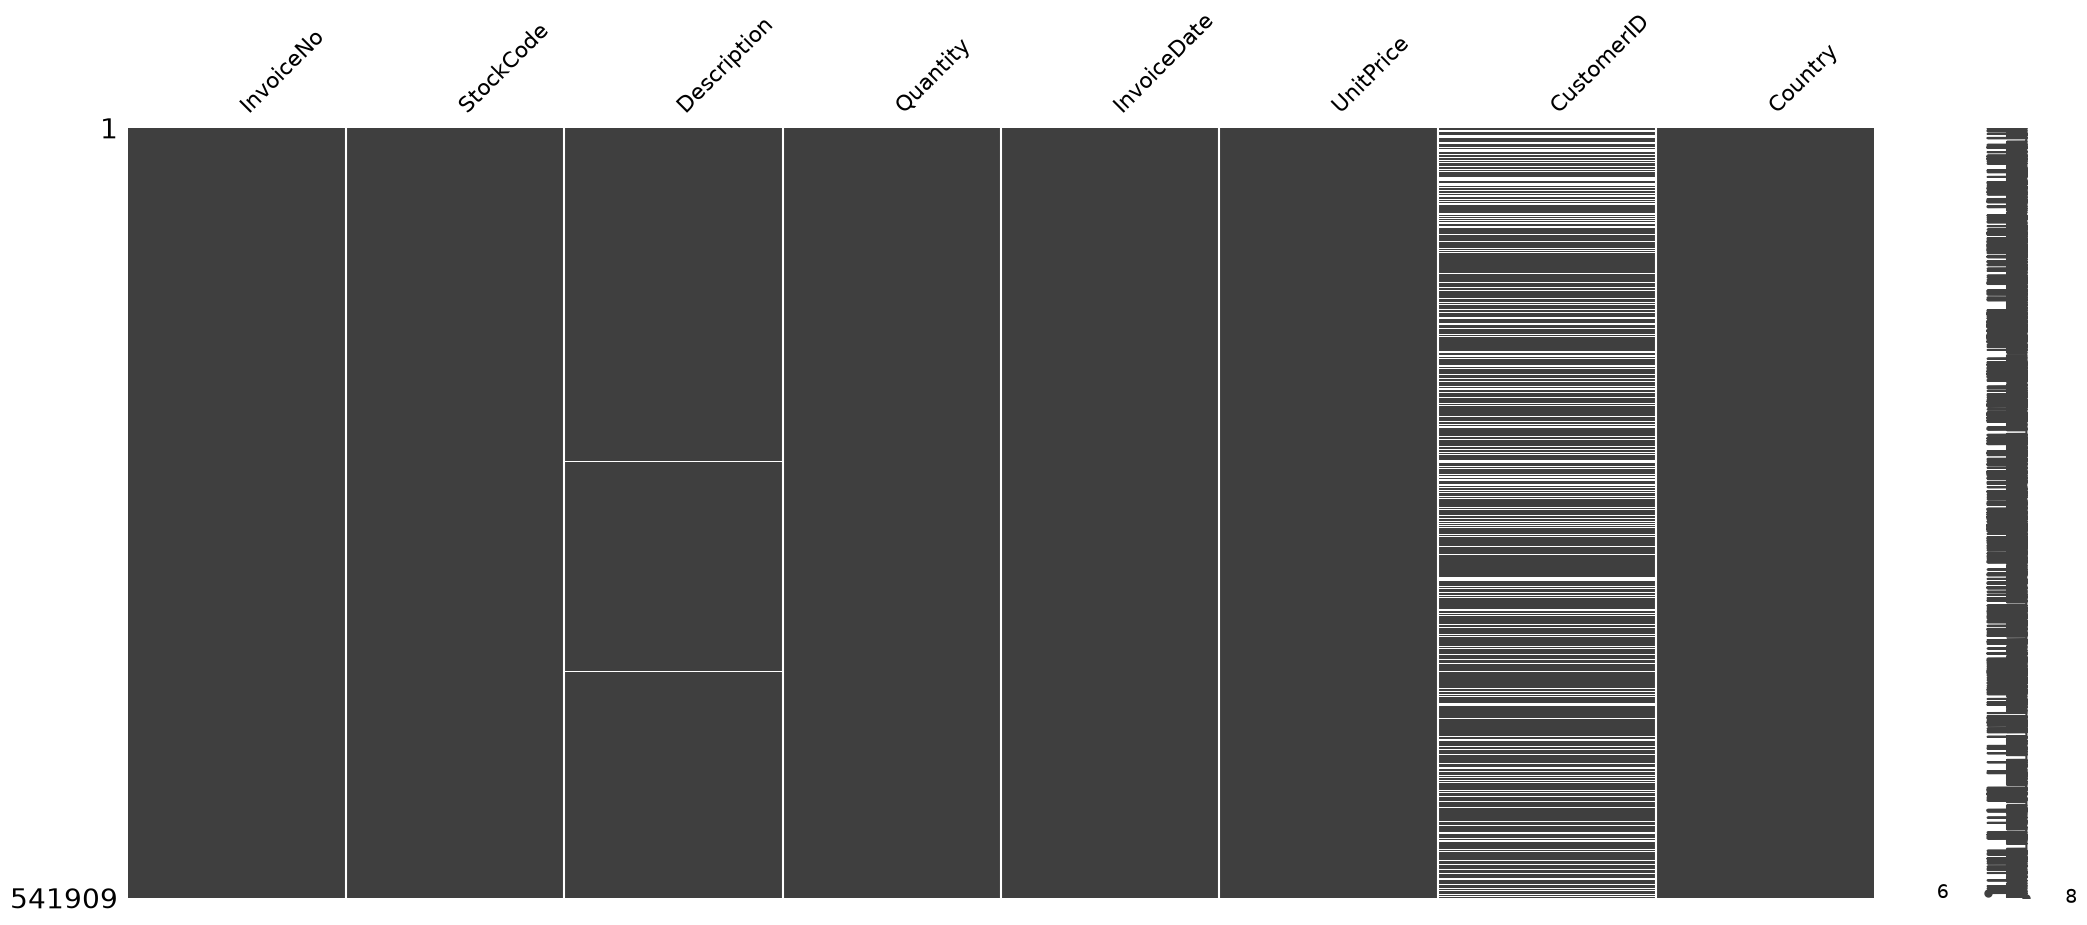

In [7]:
msno.matrix(df);

In [8]:
df.isna().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

### **Handle Missing Values**

In [9]:
df_copy = df.copy()
df_copy.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


**Description**

In [10]:
# Inspect missing values in Description
df_missing_desc = df_copy[df_copy["Description"].isna()]
df_missing_desc

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,<NA>,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,<NA>,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,<NA>,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,<NA>,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,<NA>,United Kingdom
...,...,...,...,...,...,...,...,...
535322,581199,84581,NaN,-2,2011-12-07 18:26:00,0.0,<NA>,United Kingdom
535326,581203,23406,NaN,15,2011-12-07 18:31:00,0.0,<NA>,United Kingdom
535332,581209,21620,NaN,6,2011-12-07 18:35:00,0.0,<NA>,United Kingdom
536981,581234,72817,NaN,27,2011-12-08 10:33:00,0.0,<NA>,United Kingdom


In [11]:
df_missing_desc["InvoiceNo"].nunique()

1454

In [12]:
df_missing_desc.groupby("InvoiceNo")["CustomerID"].nunique().sort_values(ascending=False).head(10)

InvoiceNo
536414    0
560403    0
560401    0
560400    0
560399    0
560389    0
560388    0
560216    0
560215    0
560214    0
Name: CustomerID, dtype: int64

Based on the results above, all 1,454 rows with missing `Description` also have missing `CustomerID` values, as indicated by zero unique customers per invoice. Because these missing values cannot be reliably imputed, the affected rows will be removed from the dataset.


In [13]:
# Drop missing values in Description
df_copy.dropna(subset=["Description"], inplace=True)
df_copy.isna().sum()

InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     133626
Country             0
dtype: int64

**CustomerID**

In [14]:
# Inspect missing values in CustomerID
df_missing_custid = df_copy[df_copy["CustomerID"].isna()]
df_missing_custid

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
1443,536544,21773,DECORATIVE ROSE BATHROOM BOTTLE,1,2010-12-01 14:32:00,2.51,<NA>,United Kingdom
1444,536544,21774,DECORATIVE CATS BATHROOM BOTTLE,2,2010-12-01 14:32:00,2.51,<NA>,United Kingdom
1445,536544,21786,POLKADOT RAIN HAT,4,2010-12-01 14:32:00,0.85,<NA>,United Kingdom
1446,536544,21787,RAIN PONCHO RETROSPOT,2,2010-12-01 14:32:00,1.66,<NA>,United Kingdom
1447,536544,21790,VINTAGE SNAP CARDS,9,2010-12-01 14:32:00,1.66,<NA>,United Kingdom
...,...,...,...,...,...,...,...,...
541536,581498,85099B,JUMBO BAG RED RETROSPOT,5,2011-12-09 10:26:00,4.13,<NA>,United Kingdom
541537,581498,85099C,JUMBO BAG BAROQUE BLACK WHITE,4,2011-12-09 10:26:00,4.13,<NA>,United Kingdom
541538,581498,85150,LADIES & GENTLEMEN METAL SIGN,1,2011-12-09 10:26:00,4.96,<NA>,United Kingdom
541539,581498,85174,S/4 CACTI CANDLES,1,2011-12-09 10:26:00,10.79,<NA>,United Kingdom


In [15]:
df_missing_custid["InvoiceNo"].nunique()

2256

In [16]:
df_missing_custid["InvoiceNo"].value_counts()

InvoiceNo
573585    1114
581219     749
581492     731
580729     721
558475     705
          ... 
581211       1
581212       1
581213       1
581226       1
581422       1
Name: count, Length: 2256, dtype: int64

The remaining 133,626 rows (24.93%) contain missing `CustomerID` values. Since the proposed framework is entirely based on customer-level analysis, these transactions cannot be incorporated into the analytical pipeline. Specifically, RFM feature engineering requires transactions to be grouped by customer to calculate Recency, Frequency, and Monetary values, while cluster-specific association rule mining is performed within customer segments. Without a valid `CustomerID`, these transactions cannot be assigned to a customer or a cluster and therefore cannot contribute to any stage of the framework. Consequently, these rows are removed from the dataset. This proportion of missing `CustomerID` values is consistent with previous studies using the same dataset (Kumar, 2025), where a similar percentage of records was excluded during the preprocessing stage.


In [17]:
df_copy.dropna(subset=["CustomerID"], inplace=True)
df_copy.isna().sum()

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

In [18]:
len_before_missing_values = len(df)
len_after_missing_values = len(df_copy)

print(f"Number of rows before removing missing values: {len_before_missing_values:,}")
print(f"Number of rows after removing missing values: {len_after_missing_values:,}")

Number of rows before removing missing values: 541,909
Number of rows after removing missing values: 406,829


----

### **Check Cancellation Transactions**

In [19]:
df_cancelled = df_copy[df_copy["InvoiceNo"].str.upper().str.startswith("C", na=False)]
df_cancelled.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548,United Kingdom


In [20]:
print(f"Cancelled transactions: {len(df_cancelled)} ({len(df_cancelled)/len(df_copy)*100:.2f}%)")

Cancelled transactions: 8905 (2.19%)


In [21]:
len_before_cancelled = len(df_copy)

Based on the results above, the dataset contains 8,905 cancelled transactions. As these transactions do not represent completed purchases and are not relevant to the subsequent analysis, they will be removed from the dataset.

In [22]:
# Remove cancelled transactions
df_copy = df_copy[~df_copy["InvoiceNo"].str.upper().str.startswith("C", na=False)]

In [23]:
len_after_cancelled = len(df_copy)

In [24]:
print(f"Number of rows before removing cancelled transactions: {len_before_cancelled:,}")
print(f"Number of rows after removing cancelled transactions: {len_after_cancelled:,}")

Number of rows before removing cancelled transactions: 406,829
Number of rows after removing cancelled transactions: 397,924


---

### **Check InvoiceNo and InvoiceDate**

In [25]:
df_multiple_inv_date = df_copy.groupby("InvoiceNo")["InvoiceDate"].nunique().sort_values(ascending=False).head(10)
df_multiple_inv_date

InvoiceNo
553199    2
576057    2
546986    2
563245    2
541631    2
544667    2
554116    2
562128    2
544926    2
542806    2
Name: InvoiceDate, dtype: int64

In [26]:
for inv_no in df_multiple_inv_date.index:
    print(inv_no)
    print(df_copy[df_copy["InvoiceNo"] == inv_no]["InvoiceDate"].unique())
    print()

553199
<DatetimeArray>
['2011-05-15 15:13:00', '2011-05-15 15:14:00']
Length: 2, dtype: datetime64[us]

576057
<DatetimeArray>
['2011-11-13 15:05:00', '2011-11-13 15:06:00']
Length: 2, dtype: datetime64[us]

546986
<DatetimeArray>
['2011-03-18 12:55:00', '2011-03-18 12:56:00']
Length: 2, dtype: datetime64[us]

563245
<DatetimeArray>
['2011-08-15 10:53:00', '2011-08-15 10:54:00']
Length: 2, dtype: datetime64[us]

541631
<DatetimeArray>
['2011-01-20 10:47:00', '2011-01-20 10:48:00']
Length: 2, dtype: datetime64[us]

544667
<DatetimeArray>
['2011-02-22 15:09:00', '2011-02-22 15:10:00']
Length: 2, dtype: datetime64[us]

554116
<DatetimeArray>
['2011-05-22 15:11:00', '2011-05-22 15:12:00']
Length: 2, dtype: datetime64[us]

562128
<DatetimeArray>
['2011-08-03 09:06:00', '2011-08-03 09:07:00']
Length: 2, dtype: datetime64[us]

544926
<DatetimeArray>
['2011-02-24 17:50:00', '2011-02-24 17:51:00']
Length: 2, dtype: datetime64[us]

542806
<DatetimeArray>
['2011-02-01 11:19:00', '2011-02-01 11:20

Based on the inspection above, invoices with multiple `InvoiceDate` values differ by only one minute on the same day. This suggests the timestamps reflect processing latency rather than separate transactions. To simplify temporal analysis without losing granularity, `InvoiceDate `will be decomposed into `InvDate` (date component) and `InvTime` (time component). This ensures each invoice maps to a single date for temporal windowing purposes.

In [27]:
df_copy["InvDate"] = df_copy["InvoiceDate"].dt.date
df_copy["InvTime"] = df_copy["InvoiceDate"].dt.time

df_copy.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,InvDate,InvTime
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,2010-12-01,08:26:00
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,2010-12-01,08:26:00
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,2010-12-01,08:26:00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,2010-12-01,08:26:00
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,2010-12-01,08:26:00


In [28]:
df_copy.groupby("InvoiceNo")["InvDate"].nunique().sort_values(ascending=False).head(10)

InvoiceNo
536365    1
567165    1
567296    1
567295    1
567294    1
567293    1
567292    1
567291    1
567290    1
567288    1
Name: InvDate, dtype: int64

After decomposing `InvoiceDate` into `InvDate` and `InvTime`, the result confirms that every `InvoiceNo` maps to exactly one date.

---

### **Check StockCode and Description**

In [29]:
df_multi_desc = df_copy.groupby("StockCode")["Description"].nunique()
df_multi_desc[df_multi_desc > 1].sort_values(ascending=False)

StockCode
23236     4
23196     4
23231     3
23366     3
23370     3
         ..
23057     2
23061     2
23065     2
23066     2
90014C    2
Name: Description, Length: 213, dtype: int64

In [30]:
df_copy[df_copy["StockCode"] == 23236]["Description"].unique()

array(['DOILEY STORAGE TIN', 'DOILEY BISCUIT TIN',
       'STORAGE TIN VINTAGE DOILY ', 'STORAGE TIN VINTAGE DOILEY '],
      dtype=object)

In [31]:
df_copy[df_copy["StockCode"] == 23196]["Description"].unique()

array(['RETRO LEAVES MAGNETIC NOTEPAD',
       'RETO LEAVES MAGNETIC SHOPPING LIST',
       'LEAVES MAGNETIC  SHOPPING LIST', 'VINTAGE LEAF MAGNETIC NOTEPAD'],
      dtype=object)

Based on the result above, 213 `StockCode` are associated with multiple `Description` values. To ensure consistent product identification, each `StockCode` is standardised to its most frequently occurring `Description`.

In [32]:
most_common_desc = df_copy.groupby("StockCode")["Description"].agg(lambda x: x.value_counts().idxmax())
most_common_desc

StockCode
10002     INFLATABLE POLITICAL GLOBE 
10080        GROOVY CACTUS INFLATABLE
10120                    DOGGY RUBBER
10125         MINI FUNKY DESIGN TAPES
10133    COLOURING PENCILS BROWN TUBE
                     ...             
C2                           CARRIAGE
DOT                    DOTCOM POSTAGE
M                              Manual
PADS       PADS TO MATCH ALL CUSHIONS
POST                          POSTAGE
Name: Description, Length: 3665, dtype: str

In [33]:
print(most_common_desc[23236])
print(most_common_desc[23196])

STORAGE TIN VINTAGE DOILY 
VINTAGE LEAF MAGNETIC NOTEPAD


In [34]:
df_copy["Description"] = df_copy["StockCode"].map(most_common_desc)

In [35]:
df_copy["Description"]

0          WHITE HANGING HEART T-LIGHT HOLDER
1                         WHITE METAL LANTERN
2              CREAM CUPID HEARTS COAT HANGER
3         KNITTED UNION FLAG HOT WATER BOTTLE
4              RED WOOLLY HOTTIE WHITE HEART.
                         ...                 
541904            PACK OF 20 SPACEBOY NAPKINS
541905           CHILDREN'S APRON DOLLY GIRL 
541906          CHILDRENS CUTLERY DOLLY GIRL 
541907        CHILDRENS CUTLERY CIRCUS PARADE
541908          BAKING SET 9 PIECE RETROSPOT 
Name: Description, Length: 397924, dtype: str

In [36]:
df_copy.groupby("StockCode")["Description"].nunique().sort_values(ascending=False).head(10)

StockCode
10002    1
72127    1
72130    1
72131    1
72132    1
72133    1
72134    1
72232    1
72586    1
72598    1
Name: Description, dtype: int64

After standardisation, every `StockCode` now maps to exactly one `Description`, confirming that product naming inconsistencies have been resolved.

**Descriptions shared by distinct stock codes.** The reverse check counts descriptions that map to more than one `StockCode`. Such products are different items that happen to share a name, which is why baskets in the association rule mining sections use `StockCode` as the item identifier rather than `Description`.

In [37]:
desc_multi_code = df_copy.groupby("Description")["StockCode"].nunique()
shared_desc = desc_multi_code[desc_multi_code > 1].sort_values(ascending=False)
print(f"Descriptions shared by more than one StockCode: {len(shared_desc)}")

df_copy[df_copy["Description"].isin(shared_desc.index)] \
    .groupby(["Description", "StockCode"]) \
    .agg(First=("InvDate", "min"), Last=("InvDate", "max"),
         Median_Price=("UnitPrice", "median"), Lines=("InvoiceNo", "size"))

Descriptions shared by more than one StockCode: 17


First        Last  \
Description                     StockCode                           
COLOURING PENCILS BROWN TUBE    10133      2010-12-01  2011-09-07   
                                10135      2010-12-02  2011-12-07   
COLUMBIAN CANDLE RECTANGLE      72131      2010-12-06  2011-11-25   
                                72133      2010-12-02  2011-12-02   
COLUMBIAN CANDLE ROUND          72128      2010-12-03  2011-11-27   
                                72130      2010-12-03  2011-11-27   
EAU DE NILE JEWELLED PHOTOFRAME 85023B     2010-12-19  2011-12-05   
                                85024B     2011-01-30  2011-12-05   
FRENCH FLORAL CUSHION COVER     20837      2011-02-17  2011-11-20   
                                20840      2011-04-27  2011-12-06   
FRENCH LATTICE CUSHION COVER    20835      2011-05-03  2011-11-10   
                                20838      2011-05-03  2011-11-23   
FROSTED WHITE BASE              79403      2010-12-14  2011-12-02   
                                79406      2011-02-16  2011-11-03   
METAL SIGN,CUPCAKE SINGLE HOOK  82613A     2010-12-20  2011-07-14   
                                82613B     2010-12-05  2011-12-06   
                                82613C     2010-12-14  2011-11-20   
PINK FAIRY CAKE CUSHION COVER   47585A     2010-12-23  2011-12-01   
                                47586A     2010-12-06  2011-11-23   
PINK FLOCK GLASS CANDLEHOLDER   79329      2010-12-15  2011-04-10   
                                79331      2011-02-20  2011-04-07   
PINK FLOWERS RABBIT EASTER      35909B     2011-02-14  2011-06-14   
                                35910B     2011-03-18  2011-11-06   
RETRO PLASTIC 70'S TRAY         79190A     2010-12-05  2011-12-09   
                                79192A     2011-01-20  2011-02-02   
RETRO PLASTIC DAISY TRAY        79190D     2010-12-05  2011-12-02   
                                79191D     2011-01-23  2011-12-09   
RETRO PLASTIC POLKA TRAY        79190B     2010-12-09  2011-12-09   
                                79191B     2010-12-05  2011-12-09   
ROUND BLUE CLOCK WITH SUCKER    81952B     2011-07-04  2011-07-26   
                                81953B     2011-07-13  2011-07-18   
SQUARE CHERRY BLOSSOM CABINET   84665      2010-12-07  2011-11-08   
                                84666      2010-12-14  2011-04-19   
WHITE BAMBOO RIBS LAMPSHADE     40001      2010-12-01  2011-11-08   
                                40003      2010-12-09  2011-06-06   

                                           Median_Price  Lines  
Description                     StockCode                       
COLOURING PENCILS BROWN TUBE    10133             0.420    124  
                                10135             1.250    121  
COLUMBIAN CANDLE RECTANGLE      72131             1.950     19  
                                72133             1.250     14  
COLUMBIAN CANDLE ROUND          72128             0.850     33  
                                72130             0.650     25  
EAU DE NILE JEWELLED PHOTOFRAME 85023B            2.550     12  
                                85024B            1.650     12  
FRENCH FLORAL CUSHION COVER     20837             0.830     15  
                                20840             0.850     44  
FRENCH LATTICE CUSHION COVER    20835             0.830      7  
                                20838             0.850     33  
FROSTED WHITE BASE              79403             0.850     11  
                                79406             0.220      6  
METAL SIGN,CUPCAKE SINGLE HOOK  82613A            1.250     15  
                                82613B            1.250     46  
                                82613C            1.250     38  
PINK FAIRY CAKE CUSHION COVER   47585A            3.750     27  
                                47586A            2.550      8  
PINK FLOCK GLASS CANDLEHOLDER   79329             1.015      2  
                                79331             0.380      3  

---

### **Check Country**

In [38]:
df_copy["Country"].sort_values().unique()

<StringArray>
[           'Australia',              'Austria',              'Bahrain',
              'Belgium',               'Brazil',               'Canada',
      'Channel Islands',               'Cyprus',       'Czech Republic',
              'Denmark',                 'EIRE',   'European Community',
              'Finland',               'France',              'Germany',
               'Greece',              'Iceland',               'Israel',
                'Italy',                'Japan',              'Lebanon',
            'Lithuania',                'Malta',          'Netherlands',
               'Norway',               'Poland',             'Portugal',
                  'RSA',         'Saudi Arabia',            'Singapore',
                'Spain',               'Sweden',          'Switzerland',
                  'USA', 'United Arab Emirates',       'United Kingdom',
          'Unspecified']
Length: 37, dtype: str

No issues were identified in the `Country` column.


---

### **Check Quantity and UnitPrice Anomalies**

In [39]:
# Basic statistics
print(df_copy[["Quantity", "UnitPrice"]].describe())

# Check for zero and negative values
print(f"\nQuantity == 0: {(df_copy["Quantity"] == 0).sum()}")
print(f"Quantity < 0: {(df_copy["Quantity"] < 0).sum()}")

print(f"\nUnitPrice == 0: {(df_copy["UnitPrice"] == 0).sum()}")
print(f"UnitPrice < 0: {(df_copy["UnitPrice"] < 0).sum()}")

            Quantity      UnitPrice
count  397924.000000  397924.000000
mean       13.021823       3.116174
std       180.420210      22.096788
min         1.000000       0.000000
25%         2.000000       1.250000
50%         6.000000       1.950000
75%        12.000000       3.750000
max     80995.000000    8142.750000

Quantity == 0: 0
Quantity < 0: 0

UnitPrice == 0: 40
UnitPrice < 0: 0


In [40]:
# Inspect zero unit prices
df_zero_price = df_copy[df_copy["UnitPrice"] == 0]
print(f"Rows: {len(df_zero_price)}")
print(f"Unique StockCodes: {df_zero_price["StockCode"].nunique()}")

Rows: 40
Unique StockCodes: 35


In [41]:
df_zero_price = df_zero_price[["StockCode", "Description", "Quantity", "InvDate", "UnitPrice"]].drop_duplicates()
df_zero_price

,StockCode,Description,Quantity,InvDate,UnitPrice
9302,22841,ROUND CAKE TIN VINTAGE GREEN,1,2010-12-05,0.0
33576,22580,ADVENT CALENDAR GINGHAM SACK,4,2010-12-16,0.0
40089,22423,REGENCY CAKESTAND 3 TIER,10,2010-12-21,0.0
47068,22090,PAPER BUNTING RETROSPOT,24,2011-01-06,0.0
47070,22553,PLASTERS IN TIN SKULLS,24,2011-01-06,0.0
56674,22168,ORGANISER WOOD ANTIQUE WHITE,1,2011-01-13,0.0
86789,84535B,FAIRY CAKES NOTEBOOK A6 SIZE,16,2011-02-10,0.0
130188,22062,CERAMIC BOWL WITH LOVE HEART DESIGN,36,2011-03-23,0.0
139453,22055,MINI CAKE STAND HANGING STRAWBERY,5,2011-03-30,0.0
145208,22162,HEART GARLAND RUSTIC PADDED,2,2011-04-04,0.0


In [42]:
for stock_code in df_zero_price["StockCode"]:
    print(stock_code)
    print(df_copy[df_copy["StockCode"] == stock_code]["UnitPrice"].unique())
    print()

22841
[ 7.95  0.    6.95  5.49 15.79]

22580
[ 5.95  0.    4.95 11.63]

22423
[10.95 12.75  0.    4.    5.   24.96]

22090
[2.95 2.55 0.   5.79]

22553
[1.65 0.   1.45]

22168
[8.5  0.   7.65]

84535B
[0.65 0.   0.42 1.46]

22062
[2.95 0.83 0.  ]

22055
[1.45 1.65 0.   0.39]

22162
[2.95 0.  ]

22636
[8.5  7.65 0.  ]

47566
[ 4.65  3.75  4.15  4.95  0.    4.3  10.79]

22619
[3.75 3.39 0.   7.46]

22167
[9.95 3.95 0.  ]

22960
[4.25 3.75 2.96 0.   4.6  8.29 2.95]

M
[1.25000e+00 1.89500e+01 8.50000e-01 4.20000e-01 6.50000e-01 1.00000e+00
 1.90000e-01 3.50000e+01 5.95000e+00 2.95000e+00 1.50000e+01 2.10000e-01
 2.00000e+01 5.00000e+00 3.20000e-01 1.45000e+00 3.00000e+00 2.00000e-01
 1.65000e+00 6.70000e+00 1.27500e+01 3.80000e-01 2.55000e+00 1.00000e+01
 4.00000e+00 3.75000e+00 3.20690e+02 3.76500e+02 2.80050e+02 1.83750e+02
 2.75600e+02 4.50000e+01 2.10000e+00 7.95000e+00 1.68717e+03 2.00000e+00
 2.50000e+00 5.00000e-01 1.49500e+01 1.09500e+01 1.62600e+02 2.38292e+03
 2.39300e+02 1.2529

All 40 zero-price rows are removed as they do not represent genuine sales transactions. 

In [43]:
len_before_zero_price = len(df_copy)

In [44]:
df_copy = df_copy[df_copy["UnitPrice"] > 0]
df_copy.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,InvDate,InvTime
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,2010-12-01,08:26:00
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,2010-12-01,08:26:00
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,2010-12-01,08:26:00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,2010-12-01,08:26:00
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,2010-12-01,08:26:00


In [45]:
len_after_zero_price = len(df_copy)

In [46]:
print(f"Number of rows before removing zero unit price: {len_before_zero_price:,}")
print(f"Number of rows after removing zero unit price: {len_after_zero_price:,}")

Number of rows before removing zero unit price: 397,924
Number of rows after removing zero unit price: 397,884


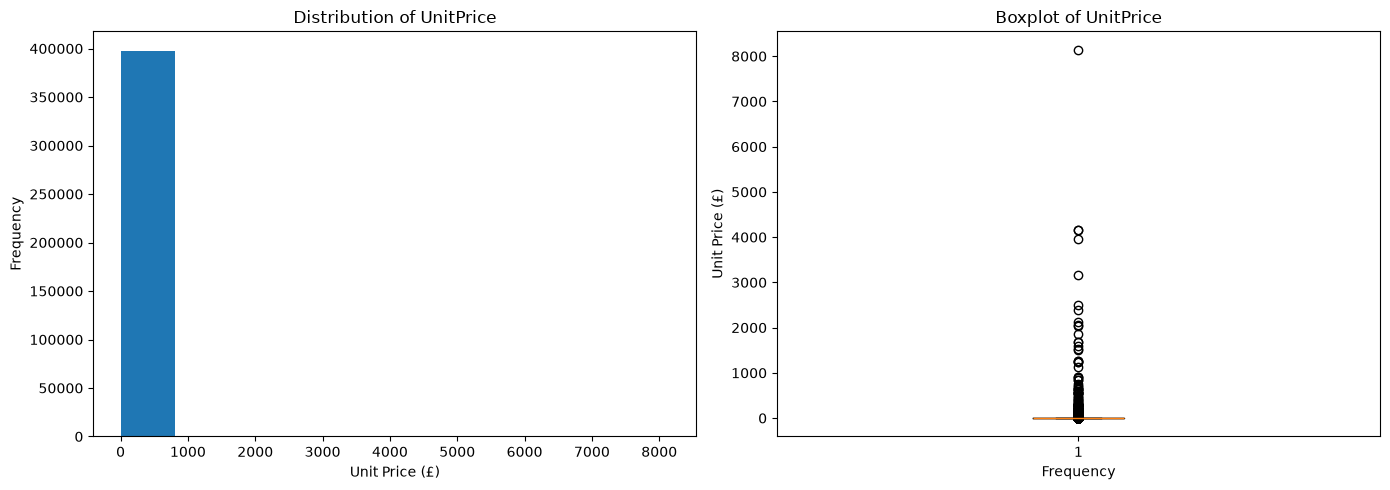

In [47]:
# Distribution of Unit Price before removing ("M", "POST", "DOT")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(df_copy["UnitPrice"], bins=10)
axes[0].set_title("Distribution of UnitPrice")
axes[0].set_xlabel("Unit Price (£)")
axes[0].set_ylabel("Frequency")

# Boxplot
axes[1].boxplot(df_copy["UnitPrice"])
axes[1].set_title("Boxplot of UnitPrice")
axes[1].set_xlabel("Frequency")
axes[1].set_ylabel("Unit Price (£)")

plt.tight_layout()
plt.show()

In [48]:
# Before removing ("M", "POST", "DOT")
print(df_copy["UnitPrice"].describe())
print("\nTop 20 highest unit prices:")
print(df_copy[["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice"]].sort_values("UnitPrice", ascending=False).head(20))

count    397884.000000
mean          3.116488
std          22.097877
min           0.001000
25%           1.250000
50%           1.950000
75%           3.750000
max        8142.750000
Name: UnitPrice, dtype: float64

Top 20 highest unit prices:
       InvoiceNo StockCode     Description  Quantity  UnitPrice
173382    551697      POST         POSTAGE         1    8142.75
422351    573077         M          Manual         1    4161.06
422376    573080         M          Manual         1    4161.06
406406    571751         M          Manual         1    3949.32
374542    569382         M          Manual         1    3155.95
297438    562946         M          Manual         1    2500.00
144826    548813         M          Manual         1    2382.92
406407    571751         M          Manual         1    2118.74
144829    548820         M          Manual         1    2053.07
343000    566927         M          Manual         1    2033.10
150615    549468         M          Manual         

---

### **Removing Postage, DotCom Postage, and Manual Entries**

Based on the inspection above, `StockCode` "M" corresponds to Manual entries, which represent transactions manually entered by staff for purposes such as price adjustments, credits, debits, or corrections rather than actual product purchases. Similarly, POSTAGE and DOTCOM POSTAGE represent shipping charges and other operational fees rather than merchandise. As the proposed framework focuses on analysing customer purchasing behaviour and product associations, these records do not correspond to tangible products and therefore do not provide meaningful information for product-level analysis. Retaining them could introduce noise into the dataset and distort purchasing patterns, particularly during association rule mining, where they may generate misleading rules involving operational charges instead of products. Consequently, all Manual, POSTAGE, and DOTCOM POSTAGE entries are removed from the dataset.

In [49]:
df_copy[df_copy["StockCode"].isin(["M", "POST", "DOT"])]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,InvDate,InvTime
45,536370,POST,POSTAGE,3,2010-12-01 08:45:00,18.00,12583,France,2010-12-01,08:45:00
386,536403,POST,POSTAGE,1,2010-12-01 11:27:00,15.00,12791,Netherlands,2010-12-01,11:27:00
1123,536527,POST,POSTAGE,1,2010-12-01 13:04:00,18.00,12662,Germany,2010-12-01,13:04:00
2239,536569,M,Manual,1,2010-12-01 15:35:00,1.25,16274,United Kingdom,2010-12-01,15:35:00
2250,536569,M,Manual,1,2010-12-01 15:35:00,18.95,16274,United Kingdom,2010-12-01,15:35:00
...,...,...,...,...,...,...,...,...,...,...
541198,581493,POST,POSTAGE,1,2011-12-09 10:10:00,15.00,12423,Belgium,2011-12-09,10:10:00
541216,581494,POST,POSTAGE,2,2011-12-09 10:13:00,18.00,12518,Germany,2011-12-09,10:13:00
541730,581570,POST,POSTAGE,1,2011-12-09 11:59:00,18.00,12662,Germany,2011-12-09,11:59:00
541767,581574,POST,POSTAGE,2,2011-12-09 12:09:00,18.00,12526,Germany,2011-12-09,12:09:00


In [50]:
df_copy[df_copy["InvoiceNo"] == 580646]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,InvDate,InvTime
526018,580646,M,Manual,800,2011-12-05 13:13:00,0.25,17857,United Kingdom,2011-12-05,13:13:00
526019,580646,22560,TRADITIONAL MODELLING CLAY,800,2011-12-05 13:13:00,1.06,17857,United Kingdom,2011-12-05,13:13:00


In [51]:
df_copy[df_copy["StockCode"] == 22560]["UnitPrice"].unique()

array([1.25, 1.06, 2.46])

In [52]:
len_before_manual_post = len(df_copy)

In [53]:
df_copy = df_copy[~(df_copy["StockCode"].isin(["M", "POST", "DOT"]))]
df_copy.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,InvDate,InvTime
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,2010-12-01,08:26:00
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,2010-12-01,08:26:00
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,2010-12-01,08:26:00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,2010-12-01,08:26:00
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,2010-12-01,08:26:00


In [54]:
len_after_manual_post = len(df_copy)

In [55]:
print(f"Number of rows before removing manual: {len_before_manual_post:,}")
print(f"Number of rows after removing manual: {len_after_manual_post:,}")

Number of rows before removing manual: 397,884
Number of rows after removing manual: 396,485


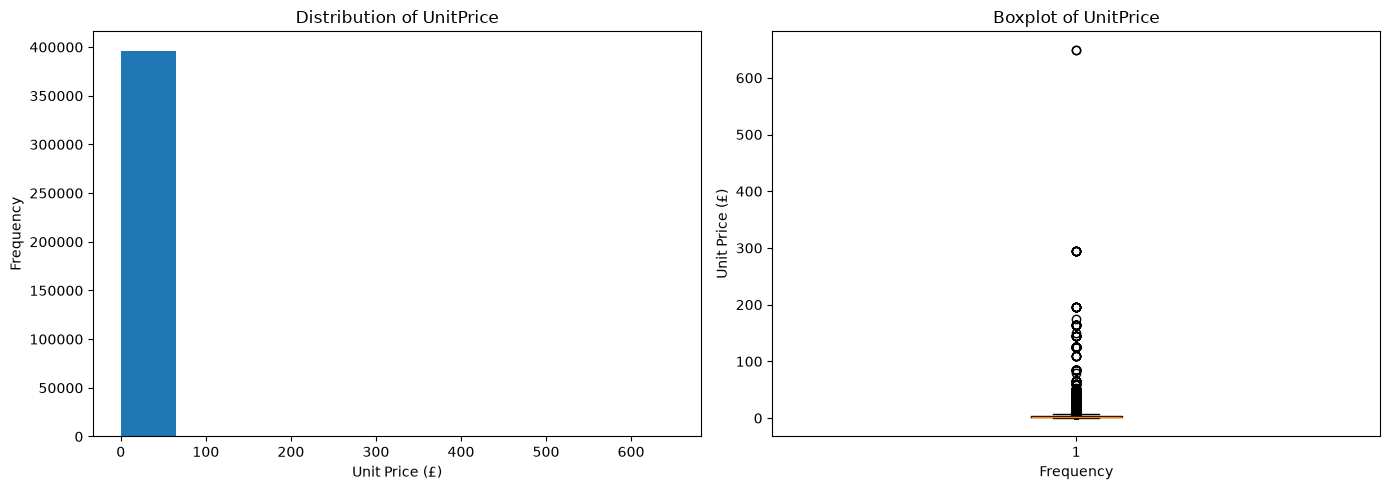

In [56]:
# Distribution of Unit Price after removing ("M", "POST", "DOT")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(df_copy["UnitPrice"], bins=10)
axes[0].set_title("Distribution of UnitPrice")
axes[0].set_xlabel("Unit Price (£)")
axes[0].set_ylabel("Frequency")

# Boxplot
axes[1].boxplot(df_copy["UnitPrice"])
axes[1].set_title("Boxplot of UnitPrice")
axes[1].set_xlabel("Frequency")
axes[1].set_ylabel("Unit Price (£)")

plt.tight_layout()
plt.show()

In [57]:
# After removing ("M", "POST", "DOT")
print(df_copy["UnitPrice"].describe())
print("\nTop 20 highest unit prices:")
print(df_copy[["InvoiceNo", "StockCode", "Description", "Quantity", "UnitPrice"]].sort_values("UnitPrice", ascending=False).head(20))

count    396485.000000
mean          2.884385
std           4.354867
min           0.001000
25%           1.250000
50%           1.950000
75%           3.750000
max         649.500000
Name: UnitPrice, dtype: float64

Top 20 highest unit prices:
       InvoiceNo StockCode                    Description  Quantity  UnitPrice
222680    556444     22502     PICNIC BASKET WICKER SMALL        60      649.5
222682    556446     22502     PICNIC BASKET WICKER SMALL         1      649.5
4989      536835     22655    VINTAGE RED KITCHEN CABINET         1      295.0
118769    546480     22656   VINTAGE BLUE KITCHEN CABINET         1      295.0
51636     540647     22655    VINTAGE RED KITCHEN CABINET         1      295.0
133994    547814     22656   VINTAGE BLUE KITCHEN CABINET         1      295.0
171178    551393     22656   VINTAGE BLUE KITCHEN CABINET         1      295.0
82768     543253     22655    VINTAGE RED KITCHEN CABINET         1      295.0
205759    554836     22655    VINTAGE RED KI

---

### **Rearrange the Columns**

In [58]:
df_copy = df_copy[["InvoiceNo", "InvoiceDate", "InvDate", "InvTime", "CustomerID", "Country", "StockCode", "Description", "Quantity", "UnitPrice"]]
df_copy.head()

,InvoiceNo,InvoiceDate,InvDate,InvTime,CustomerID,Country,StockCode,Description,Quantity,UnitPrice
0,536365,2010-12-01 08:26:00,2010-12-01,08:26:00,17850,United Kingdom,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55
1,536365,2010-12-01 08:26:00,2010-12-01,08:26:00,17850,United Kingdom,71053,WHITE METAL LANTERN,6,3.39
2,536365,2010-12-01 08:26:00,2010-12-01,08:26:00,17850,United Kingdom,84406B,CREAM CUPID HEARTS COAT HANGER,8,2.75
3,536365,2010-12-01 08:26:00,2010-12-01,08:26:00,17850,United Kingdom,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,3.39
4,536365,2010-12-01 08:26:00,2010-12-01,08:26:00,17850,United Kingdom,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,3.39


In [59]:
# Save the cleaned dataset; the EDA and modelling sections below read from this file
df_copy.to_csv("Online_Retail_Clean.csv", index=False)

---

## **Exploratory Data Analysis (EDA)**

### **Dataset Overview**

In [60]:
df = pd.read_csv("Online_Retail_Clean.csv")
df.head()

,InvoiceNo,InvoiceDate,InvDate,InvTime,CustomerID,Country,StockCode,Description,Quantity,UnitPrice
0,536365,2010-12-01 08:26:00,2010-12-01,08:26:00,17850,United Kingdom,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55
1,536365,2010-12-01 08:26:00,2010-12-01,08:26:00,17850,United Kingdom,71053,WHITE METAL LANTERN,6,3.39
2,536365,2010-12-01 08:26:00,2010-12-01,08:26:00,17850,United Kingdom,84406B,CREAM CUPID HEARTS COAT HANGER,8,2.75
3,536365,2010-12-01 08:26:00,2010-12-01,08:26:00,17850,United Kingdom,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,3.39
4,536365,2010-12-01 08:26:00,2010-12-01,08:26:00,17850,United Kingdom,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,3.39


In [61]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 396485 entries, 0 to 396484
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    396485 non-null  int64  
 1   InvoiceDate  396485 non-null  str    
 2   InvDate      396485 non-null  str    
 3   InvTime      396485 non-null  str    
 4   CustomerID   396485 non-null  int64  
 5   Country      396485 non-null  str    
 6   StockCode    396485 non-null  str    
 7   Description  396485 non-null  str    
 8   Quantity     396485 non-null  int64  
 9   UnitPrice    396485 non-null  float64
dtypes: float64(1), int64(3), str(6)
memory usage: 30.2 MB


In [62]:
df["InvDate"] = pd.to_datetime(df["InvDate"])
df["InvTime"] = pd.to_datetime(df["InvTime"], format="%H:%M:%S")

In [63]:
print(f"Total rows: {len(df):,}")
print(f"Date range: {df["InvDate"].min()} to {df["InvDate"].max()}")
print(f"Unique invoices: {df["InvoiceNo"].nunique():,}")
print(f"Unique customers: {df["CustomerID"].nunique():,}")
print(f"Unique products: {df["StockCode"].nunique():,}")
print(f"Unique countries: {df["Country"].nunique()}")

Total rows: 396,485
Date range: 2010-12-01 00:00:00 to 2011-12-09 00:00:00
Unique invoices: 18,416
Unique customers: 4,335
Unique products: 3,662
Unique countries: 37


---

### **Temporal Distribution**

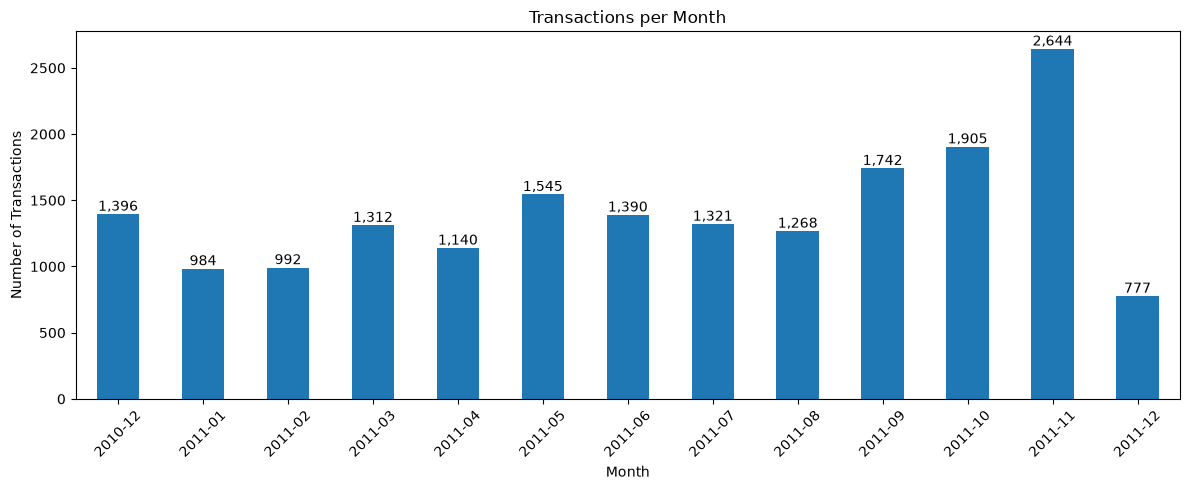

In [64]:
# Transactions per month 
monthly_transaction = df.groupby(df["InvDate"].dt.to_period("M"))["InvoiceNo"].nunique()
ax = monthly_transaction.plot(kind="bar", figsize=(12,5), title="Transactions per Month")
ax.set_xlabel("Month")
ax.set_ylabel("Number of Transactions")
ax.bar_label(ax.containers[0], fmt=lambda v: f"{int(v):,}")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Insight:**

Monthly volume is fairly stable from December 2010 through August 2011 (roughly 1,000–1,550 transactions), then climbs steadily from September to a sharp peak in November 2011 (2,650). This late-year surge is consistent with pre-Christmas wholesale ordering, as retailers stock up ahead of the holiday season. Two months need care in temporal windowing: December 2010 is a full month but sits at the very start, and December 2011 (778) is incomplete, covering only the first 9 days.

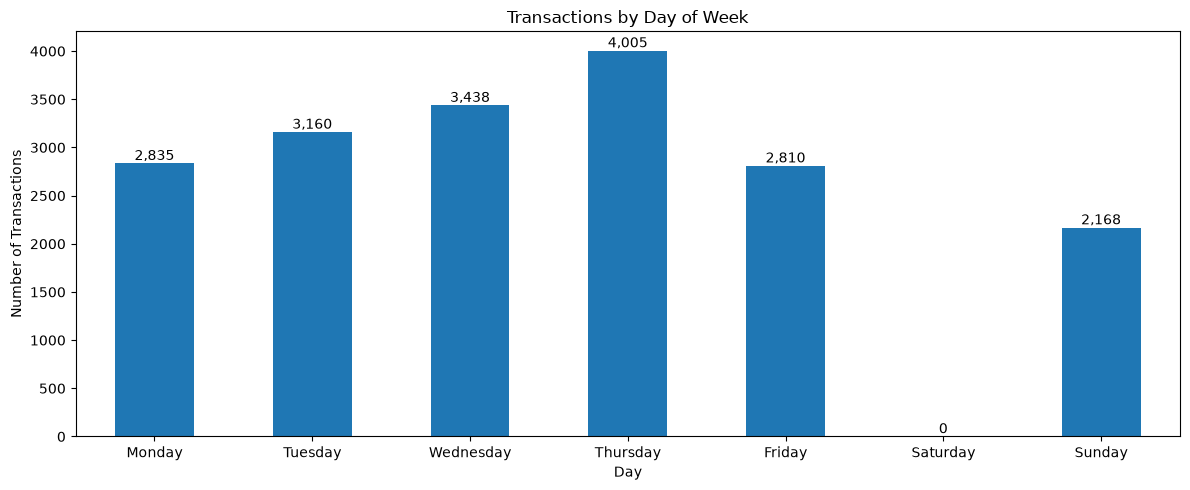

In [65]:
# Transactions by day of the week 
daily_transaction = df.groupby(df["InvDate"].dt.day_name())["InvoiceNo"].nunique()
daily_transaction = daily_transaction.reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
ax = daily_transaction.plot(kind="bar", figsize=(12,5), title="Transactions by Day of Week")
ax.set_xlabel("Day")
ax.set_ylabel("Number of Transactions")
ax.bar_label(ax.containers[0], fmt=lambda v: f"{int(v):,}")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Insight:**

There are no Saturday transactions at all (0), confirming the retailer did not process orders on Saturdays during this period. Thursday is the busiest day (4,005), with activity generally concentrated midweek (Tuesday–Thursday). Sunday is the quietest trading day (2,168). 

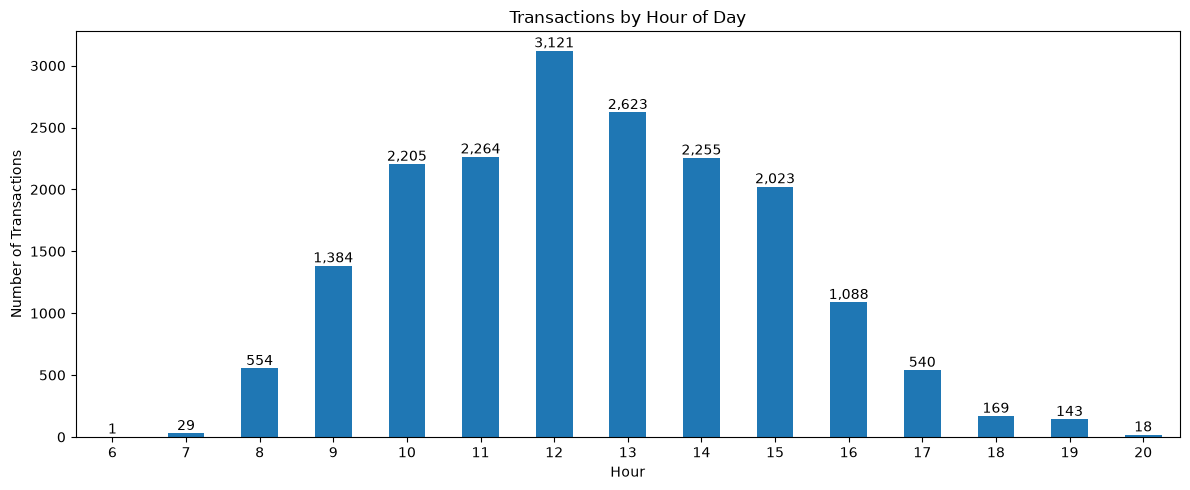

In [66]:
# Transactions by hour 
hourly_transaction = df.groupby(df["InvTime"].dt.hour)["InvoiceNo"].nunique()
ax = hourly_transaction.plot(kind="bar", figsize=(12,5), title="Transactions by Hour of Day")
ax.set_xlabel("Hour")
ax.set_ylabel("Number of Transactions")
ax.bar_label(ax.containers[0], fmt=lambda v: f"{int(v):,}")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Insight:**

Trading is concentrated during business hours, running from 6:00 to 20:00, with a pronounced midday peak at 12:00 (3,121). Activity ramps up from 9:00, stays high between 10:00 and 15:00, then tapers off through the afternoon and evening. 

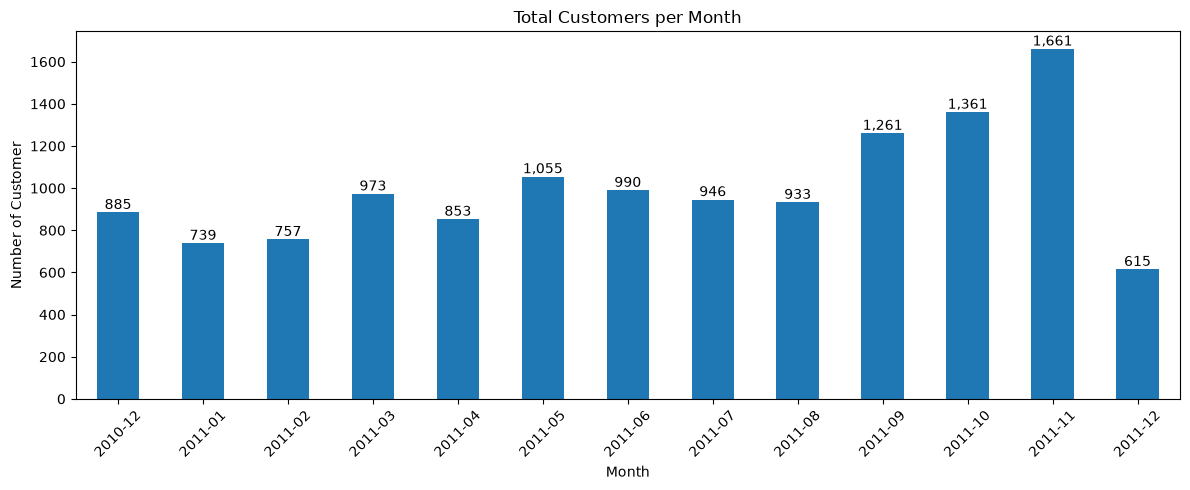

In [67]:
# Customers per month 
monthly_customer = df.groupby(df["InvDate"].dt.to_period("M"))["CustomerID"].nunique()
ax = monthly_customer.plot(kind="bar", figsize=(12,5), title="Total Customers per Month")
ax.set_xlabel("Month")
ax.set_ylabel("Number of Customer")
ax.bar_label(ax.containers[0], fmt=lambda v: f"{int(v):,}")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Insight:**

Active customers stay fairly stable from December 2010 to August 2011 (around 740–1,055 per month), then rise steadily from September to peak in November 2011 (1,661), before the incomplete December 2011 (615). This mirrors the transaction trend, confirming the late-year surge is driven by more active customers rather than existing customers ordering more often, consistent with pre-holiday demand.

---

### **Customer Activity Analysis**

count    4335.000000
mean        4.248212
std         7.646024
min         1.000000
25%         1.000000
50%         2.000000
75%         5.000000
max       206.000000
Name: InvoiceNo, dtype: float64


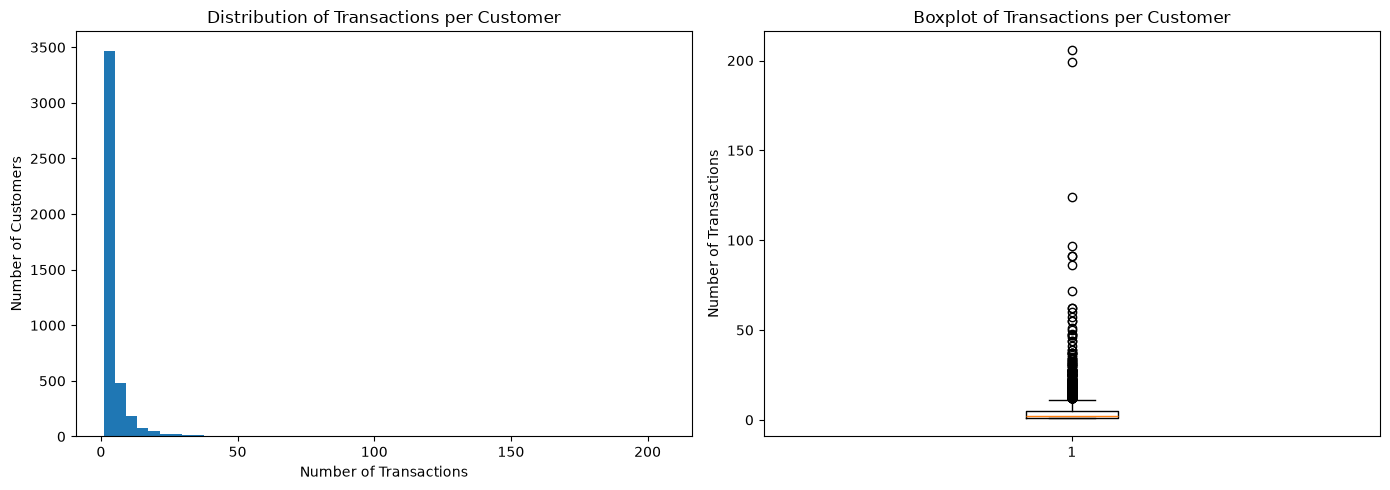

In [68]:
# Transactions per customer 
transaction_per_customer = df.groupby("CustomerID")["InvoiceNo"].nunique()
print(transaction_per_customer.describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(transaction_per_customer, bins=50)
axes[0].set_title("Distribution of Transactions per Customer")
axes[0].set_xlabel("Number of Transactions")
axes[0].set_ylabel("Number of Customers")

# Boxplot
axes[1].boxplot(transaction_per_customer)
axes[1].set_title("Boxplot of Transactions per Customer")
axes[1].set_ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

**Insight:**

Transaction frequency is highly right-skewed. Half of the customers made two or fewer transactions (median = 2), with at least 25% making only a single purchase. Although the average customer completed 4.25 transactions, this mean is inflated by a relatively small group of highly active customers, including extreme outliers with up to 206 transactions.

In [69]:
# Total Price
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]
df.head()

,InvoiceNo,InvoiceDate,InvDate,InvTime,CustomerID,Country,StockCode,Description,Quantity,UnitPrice,TotalPrice
0,536365,2010-12-01 08:26:00,2010-12-01,1900-01-01 08:26:00,17850,United Kingdom,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55,15.30
1,536365,2010-12-01 08:26:00,2010-12-01,1900-01-01 08:26:00,17850,United Kingdom,71053,WHITE METAL LANTERN,6,3.39,20.34
2,536365,2010-12-01 08:26:00,2010-12-01,1900-01-01 08:26:00,17850,United Kingdom,84406B,CREAM CUPID HEARTS COAT HANGER,8,2.75,22.00
3,536365,2010-12-01 08:26:00,2010-12-01,1900-01-01 08:26:00,17850,United Kingdom,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,3.39,20.34
4,536365,2010-12-01 08:26:00,2010-12-01,1900-01-01 08:26:00,17850,United Kingdom,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,3.39,20.34


count      4335.000000
mean       2022.587694
std        8923.226623
min           3.750000
25%         305.765000
50%         668.110000
75%        1631.475000
max      279138.020000
Name: TotalPrice, dtype: float64


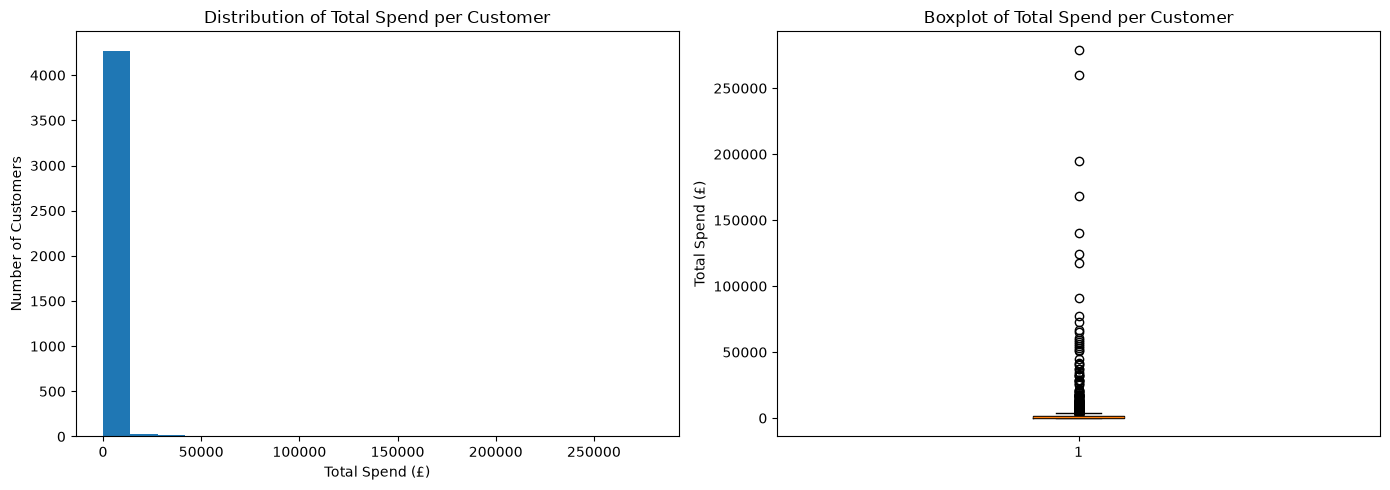

In [70]:
# Spend per Customer
spend_per_customer = df.groupby("CustomerID")["TotalPrice"].sum()
print(spend_per_customer.describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(spend_per_customer, bins=20)
axes[0].set_title("Distribution of Total Spend per Customer")
axes[0].set_xlabel("Total Spend (£)")
axes[0].set_ylabel("Number of Customers")

# Boxplot
axes[1].boxplot(spend_per_customer)
axes[1].set_title("Boxplot of Total Spend per Customer")
axes[1].set_ylabel("Total Spend (£)")

plt.tight_layout()
plt.show()

**Insight:**

Total customer spending is highly right-skewed. The median customer spends approximately £668 over the year, while the interquartile range (IQR) spans from approximately £306 to £1,631, indicating that the central 50% of customers fall within this range. However, a small number of high-value customers spend up to £279,138, resulting in a long right tail. Consequently, the mean total spend (£2,023) is substantially higher than the median, indicating that a relatively small number of large wholesale customers significantly inflate the average.

count     18416.000000
mean        476.103261
std        1678.286286
min           0.380000
25%         157.740000
50%         302.280000
75%         465.552500
max      168469.600000
Name: TotalPrice, dtype: float64


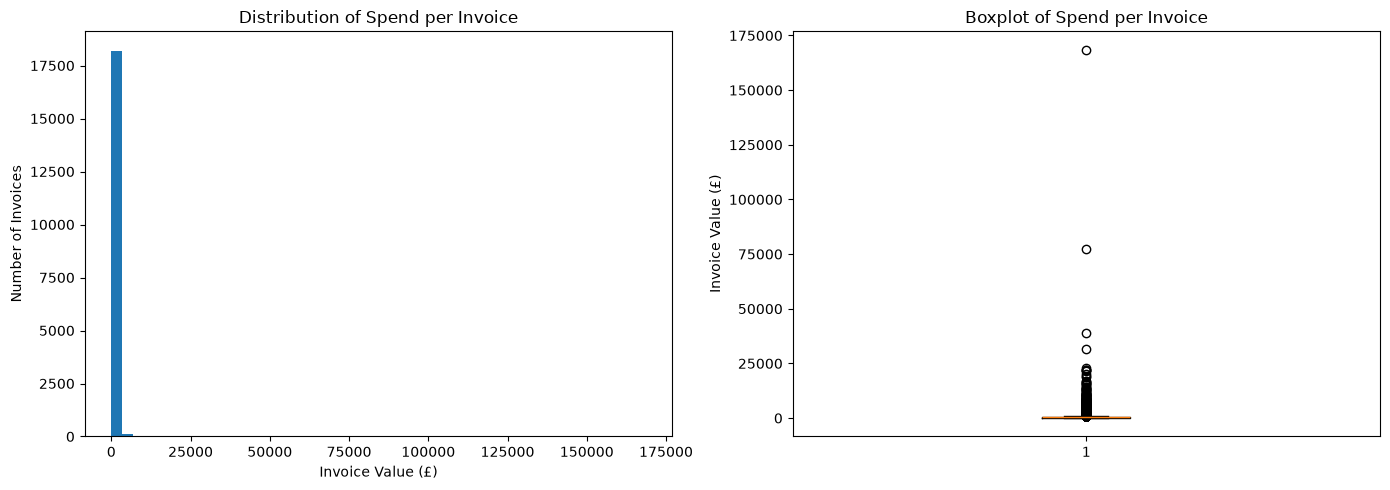

In [71]:
# Spend per Transaction
spend_per_transaction = df.groupby("InvoiceNo")["TotalPrice"].sum()
print(spend_per_transaction.describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(spend_per_transaction, bins=50)
axes[0].set_title("Distribution of Spend per Invoice")
axes[0].set_xlabel("Invoice Value (£)")
axes[0].set_ylabel("Number of Invoices")

# Boxplot
axes[1].boxplot(spend_per_transaction)
axes[1].set_title("Boxplot of Spend per Invoice")
axes[1].set_ylabel("Invoice Value (£)")

plt.tight_layout()
plt.show()

In [72]:
spend_per_transaction.sort_values(ascending=False)

InvoiceNo
581483    168469.60
541431     77183.60
556444     38970.00
567423     31698.16
556917     22775.93
            ...    
538194         0.95
538669         0.95
540945         0.85
542736         0.55
570554         0.38
Name: TotalPrice, Length: 18416, dtype: float64

**Insight:**

Spend per transaction is highly right-skewed. The median invoice value is approximately £302, with the middle 50% of invoices ranging from approximately £158 to £465. However, a small number of exceptionally high-value transactions create a long right tail, with the maximum invoice value reaching £168,470.


count    4335.000000
mean       61.421684
std        85.312346
min         1.000000
25%        16.000000
50%        35.000000
75%        77.000000
max      1786.000000
Name: StockCode, dtype: float64


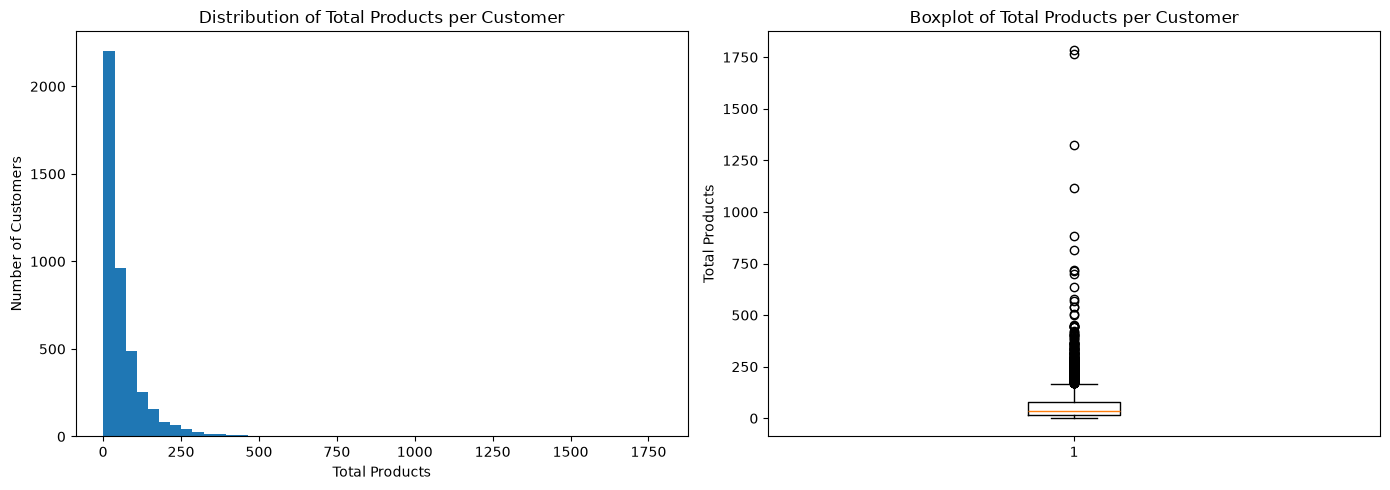

In [73]:
product_per_customer = df.groupby("CustomerID")["StockCode"].nunique()
print(product_per_customer.describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(product_per_customer, bins=50)
axes[0].set_title("Distribution of Total Products per Customer")
axes[0].set_xlabel("Total Products")
axes[0].set_ylabel("Number of Customers")

# Boxplot
axes[1].boxplot(product_per_customer)
axes[1].set_title("Boxplot of Total Products per Customer")
axes[1].set_ylabel("Total Products")

plt.tight_layout()
plt.show() 

**Insight:**

Product variety per customer is right-skewed, although less pronounced than the distributions of customer spending and transaction frequency. The median customer purchases 35 distinct products over the year, while the interquartile range (IQR) spans from 16 to 77 distinct products, indicating that the central 50% of customers fall within this range. However, a small number of customers purchase a much wider variety of products, with the maximum reaching 1,786 distinct products. Consequently, the mean product variety (61) exceeds the median, reflecting the influence of a relatively small group of high-variety wholesale customers.


---

### **Product Analysis**

In [74]:
top_products_freq = df.groupby("Description")["InvoiceNo"].nunique().sort_values(ascending=False).head(15)
print(top_products_freq)

Description
WHITE HANGING HEART T-LIGHT HOLDER    1978
REGENCY CAKESTAND 3 TIER              1703
JUMBO BAG RED RETROSPOT               1600
PARTY BUNTING                         1379
ASSORTED COLOUR BIRD ORNAMENT         1375
LUNCH BAG RED RETROSPOT               1289
SET OF 3 CAKE TINS PANTRY DESIGN      1146
JUMBO BAG VINTAGE DOILY               1080
LUNCH BAG  BLACK SKULL.               1052
LUNCH BAG SUKI DESIGN                 1043
POPCORN HOLDER                        1035
PACK OF 72 RETROSPOT CAKE CASES       1029
SPOTTY BUNTING                        1009
LUNCH BAG VINTAGE DOILY               1006
LUNCH BAG SPACEBOY DESIGN              988
Name: InvoiceNo, dtype: int64


**Insight:**

The most frequently purchased products are primarily home decor, kitchenware, and gift-related items. WHITE HANGING HEART T-LIGHT HOLDER appears in the highest number of invoices (1,978), followed by REGENCY CAKESTAND 3 TIER (1,703) and JUMBO BAG RED RETROSPOT (1,600). The presence of several LUNCH BAG variants and decorative items among the top-selling products suggests that customers commonly purchase practical household goods alongside seasonal or gift-oriented products. These high-frequency items are likely to play an important role in subsequent association rule mining, as they have strong potential to co-occur with other products in customer baskets.

In [75]:
top_products_qty = df.groupby("Description")["Quantity"].sum().sort_values(ascending=False).head(15)
print(top_products_qty)

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        77916
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54415
POPCORN HOLDER                        49183
JUMBO BAG RED RETROSPOT               46181
WHITE HANGING HEART T-LIGHT HOLDER    36782
ASSORTED COLOUR BIRD ORNAMENT         35362
PACK OF 72 RETROSPOT CAKE CASES       33693
RABBIT NIGHT LIGHT                    27202
MINI PAINT SET VINTAGE                26076
PACK OF 12 LONDON TISSUES             25345
PACK OF 60 PINK PAISLEY CAKE CASES    24264
BROCADE RING PURSE                    22963
VICTORIAN GLASS HANGING T-LIGHT       22433
ASSORTED COLOURS SILK FAN             21876
Name: Quantity, dtype: int64


**Insight:** 

The highest-selling products by quantity are dominated by low-cost household and gift items that are often purchased in bulk. PAPER CRAFT, LITTLE BIRDIE records the highest total quantity sold (80,995 units), followed by MEDIUM CERAMIC TOP STORAGE JAR (77,916) and WORLD WAR 2 GLIDERS ASSTD DESIGNS (54,415). While several products, such as WHITE HANGING HEART T-LIGHT HOLDER and JUMBO BAG RED RETROSPOT, also rank highly by purchase frequency, others achieve high sales volumes primarily because customers tend to buy multiple units per transaction. This suggests that both purchase frequency and purchase quantity contribute to product popularity, highlighting the importance of considering multiple sales metrics when identifying key products.

In [76]:
top_products_rev = df.groupby("Description")["TotalPrice"].sum().sort_values(ascending=False).head(15)
print(top_products_rev)

Description
PAPER CRAFT , LITTLE BIRDIE           168469.60
REGENCY CAKESTAND 3 TIER              142592.95
WHITE HANGING HEART T-LIGHT HOLDER    100603.50
JUMBO BAG RED RETROSPOT                85220.78
MEDIUM CERAMIC TOP STORAGE JAR         81416.73
PARTY BUNTING                          68844.33
ASSORTED COLOUR BIRD ORNAMENT          56580.34
RABBIT NIGHT LIGHT                     51346.20
PICNIC BASKET WICKER SMALL             47366.20
CHILLI LIGHTS                          46286.51
PAPER CHAIN KIT 50'S CHRISTMAS         42660.83
BLACK RECORD COVER FRAME               39064.55
JUMBO BAG VINTAGE DOILY                37684.38
JUMBO BAG PINK POLKADOT                37289.59
POPCORN HOLDER                         37226.43
Name: TotalPrice, dtype: float64


**Insight:**

The highest-revenue products are primarily home decor, storage, and gift items. PAPER CRAFT, LITTLE BIRDIE generates the greatest revenue (£168,469.60), followed by REGENCY CAKESTAND 3 TIER (£142,592.95) and WHITE HANGING HEART T-LIGHT HOLDER (£100,603.50). Several products, including REGENCY CAKESTAND 3 TIER, JUMBO BAG RED RETROSPOT, and WHITE HANGING HEART T-LIGHT HOLDER, consistently rank among the top products by purchase frequency, sales quantity, and revenue, indicating that their strong financial performance is driven by both widespread demand and high sales volume. These products are likely to be key contributors to overall business revenue and important candidates for subsequent customer and basket analysis.


count    18416.000000
mean        20.985719
std         23.816161
min          1.000000
25%          7.000000
50%         15.000000
75%         27.000000
max        540.000000
Name: StockCode, dtype: float64


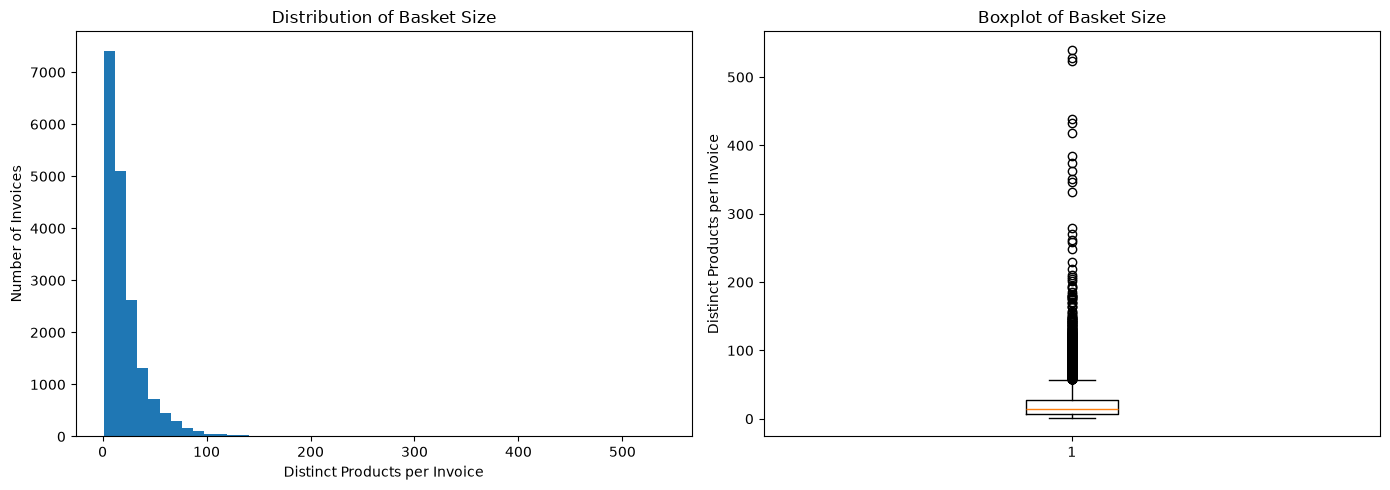

In [77]:
basket_size = df.groupby("InvoiceNo")["StockCode"].nunique()
print(basket_size.describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(basket_size, bins=50)
axes[0].set_title("Distribution of Basket Size")
axes[0].set_xlabel("Distinct Products per Invoice")
axes[0].set_ylabel("Number of Invoices")
axes[1].boxplot(basket_size)
axes[1].set_title("Boxplot of Basket Size")
axes[1].set_ylabel("Distinct Products per Invoice")
plt.tight_layout()
plt.show()

In [78]:
print(f"Single-item invoices: {(basket_size == 1).sum()} ({(basket_size == 1).mean()*100:.1f}%)")
print(f"Invoices with 2+ items: {(basket_size >= 2).sum()} ({(basket_size >= 2).mean()*100:.1f}%)")

Single-item invoices: 1327 (7.2%)
Invoices with 2+ items: 17089 (92.8%)


**Insight:**

Basket size is highly right-skewed, with most invoices containing a relatively small number of distinct products. Although the majority of invoices include fewer than 30 unique items, a small number of large orders contain several hundred distinct products, with the maximum exceeding 500 products per invoice. Additionally, only 7.2% of invoices consist of a single item, while 92.8% contain two or more items, indicating that customers typically purchase multiple products within a single transaction. This purchasing behaviour provides a strong basis for association rule mining, as multi-item baskets offer meaningful product co-occurrence patterns.

---

### **Country Distribution**

In [79]:
country_summary = df.groupby("Country").agg(Transactions=("InvoiceNo", "nunique"),
                                            Customers=("CustomerID", "nunique"),
                                            Revenue=("TotalPrice", "sum")).sort_values("Transactions", ascending=False)
print(country_summary)

                      Transactions  Customers      Revenue
Country                                                   
United Kingdom               16590       3917  7267502.234
Germany                        443         94   205569.890
France                         380         87   184077.680
EIRE                           258          3   262171.560
Belgium                         98         25    36927.340
Netherlands                     93          9   283889.340
Spain                           88         30    55725.110
Australia                       56          9   138171.310
Portugal                        49         19    26707.950
Switzerland                     47         21    52441.950
Finland                         40         12    18344.880
Italy                           35         14    15820.240
Sweden                          34          8    36839.330
Norway                          32         10    32454.640
Channel Islands                 25          9    20157.4

**Insight:**

The customer base is highly concentrated in the United Kingdom, which accounts for the vast majority of transactions (16,590), customers (3,917), and revenue (approximately £7.27 million). International sales are comparatively limited, with Germany, France, and EIRE (Ireland) representing the largest overseas markets by transaction volume. Notably, although EIRE (Ireland) has only three customers and the Netherlands has nine customers, both generate substantial revenue, suggesting that these customers place relatively large or high-value orders. Overall, the dataset reflects a business that primarily serves the UK market while maintaining a smaller but valuable international wholesale customer base.


In [80]:
uk_transaction = df[df["Country"] == "United Kingdom"]["InvoiceNo"].nunique()
total_transaction = df["InvoiceNo"].nunique()

uk_customer = df[df["Country"] == "United Kingdom"]["CustomerID"].nunique()
total_customer = df["CustomerID"].nunique()

print(f"UK transactions: {uk_transaction:,} / {total_transaction:,} ({uk_transaction/total_transaction * 100:.1f}%)")
print(f"UK customers: {uk_customer:,} / {total_customer:,} ({uk_customer/total_customer * 100:.1f}%)")

UK transactions: 16,590 / 18,416 (90.1%)
UK customers: 3,917 / 4,335 (90.4%)


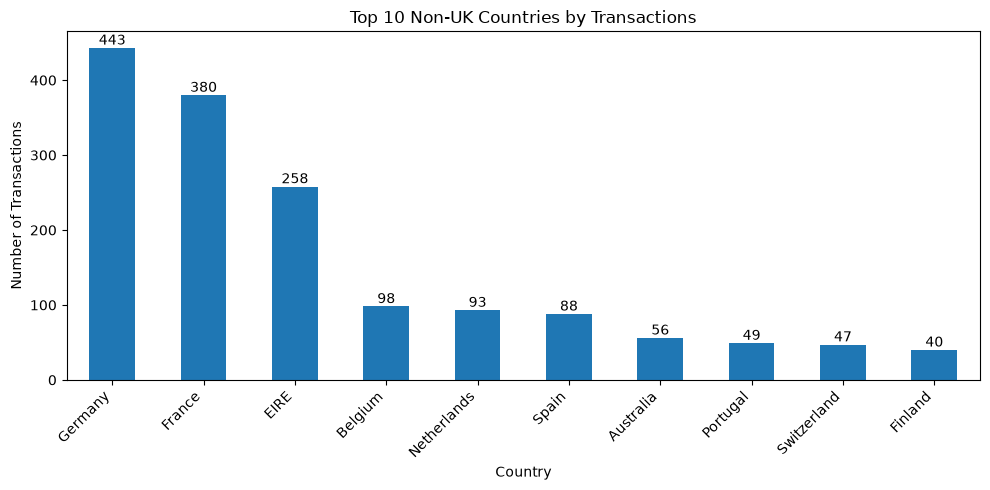

In [81]:
top_countries = country_summary.drop("United Kingdom").head(10)
ax = top_countries["Transactions"].plot(kind="bar", figsize=(10, 5), title="Top 10 Non-UK Countries by Transactions")
ax.set_xlabel("Country")
ax.set_ylabel("Number of Transactions")
ax.bar_label(ax.containers[0], fmt=lambda v: f"{int(v):,}")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Insight:**

The United Kingdom overwhelmingly dominates the customer base, accounting for 90.1% of all transactions and 90.4% of all customers. Among international markets, Germany, France, and EIRE (Ireland) generate the highest number of transactions, although each contributes only a small fraction compared with the UK. 

---

### **Revenue and Spending Patterns**

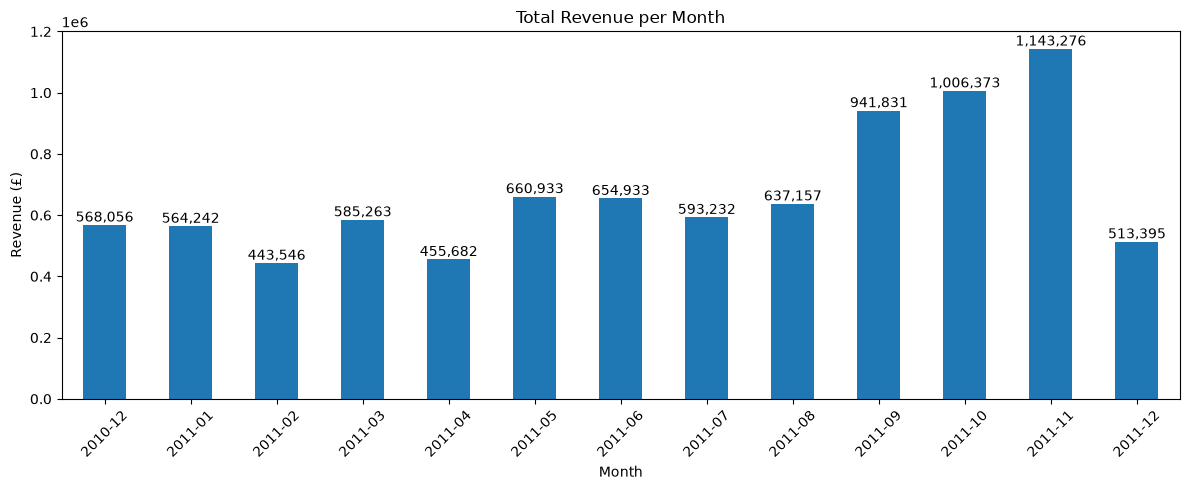

In [82]:
monthly_revenue = df.groupby(df["InvDate"].dt.to_period("M"))["TotalPrice"].sum()
ax = monthly_revenue.plot(kind="bar", figsize=(12, 5), title="Total Revenue per Month")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (£)")
ax.bar_label(ax.containers[0], fmt=lambda v: f"{v:,.0f}")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Insight:**

Monthly revenue shows an overall upward trend throughout 2011, despite some month-to-month fluctuations. Revenue increased from approximately £564,242 in January to a peak of £1.14 million in November, indicating substantially stronger sales during the latter part of the year, likely driven by seasonal demand leading up to the holiday period. Revenue then declined to approximately £513,395 in December; however, this decrease is expected because the dataset contains transactions for only part of the month, making December an incomplete reporting period rather than evidence of reduced business performance.

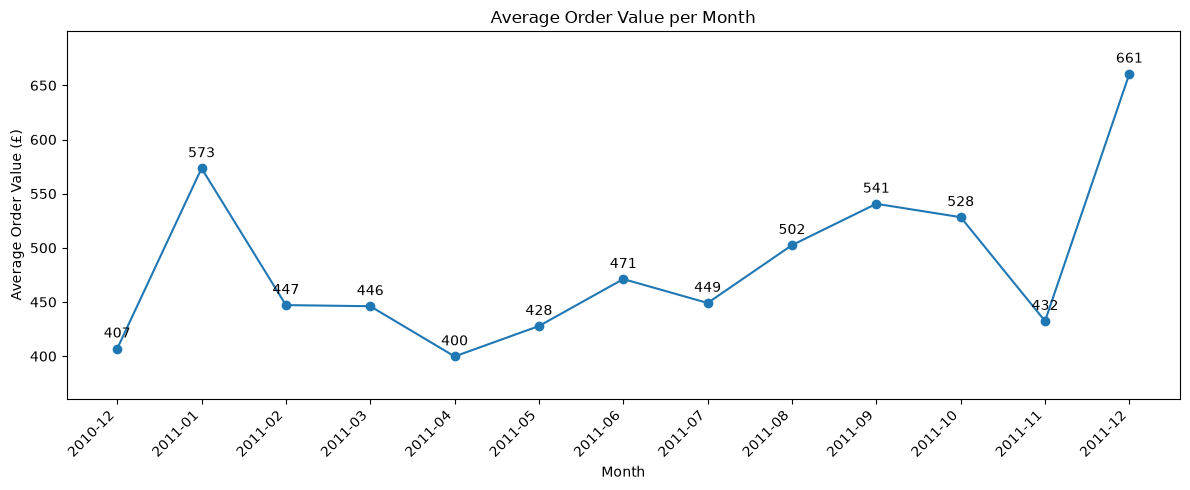

In [83]:
monthly_aov = df.groupby(df["InvDate"].dt.to_period("M")).apply(lambda x: x["TotalPrice"].sum() / x["InvoiceNo"].nunique())
monthly_aov.index = monthly_aov.index.astype("str")

ax = monthly_aov.plot(kind="line", marker="o", figsize=(12, 5), title="Average Order Value per Month")
ax.set_xlabel("Month")
ax.set_ylabel("Average Order Value (£)")

for x, y in enumerate(monthly_aov):
    ax.annotate(f"{y:,.0f}", (x, y), textcoords="offset points", xytext=(0, 8), ha="center")

ax.set_xticks(range(len(monthly_aov)))
ax.set_xticklabels(monthly_aov.index, rotation=45, ha="right")

ax.margins(y=0.15)
plt.tight_layout()
plt.show()

**Insight:** 

Average Order Value (AOV) varies throughout the year, ranging from approximately £400 to £661 per order. AOV remains relatively stable between April and November, generally fluctuating between £400 and £540, with modest increases in January and September–October. The highest AOV is observed in December (£660.74); however, this should be interpreted with caution because the dataset contains transactions for only part of the month. Overall, the results suggest that while monthly revenue increases substantially toward the end of the year, this growth is driven primarily by a higher number of orders rather than a consistent increase in the value of individual orders.

---

## **Static K-Means**

In [84]:
df.head()

,InvoiceNo,InvoiceDate,InvDate,InvTime,CustomerID,Country,StockCode,Description,Quantity,UnitPrice,TotalPrice
0,536365,2010-12-01 08:26:00,2010-12-01,1900-01-01 08:26:00,17850,United Kingdom,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55,15.30
1,536365,2010-12-01 08:26:00,2010-12-01,1900-01-01 08:26:00,17850,United Kingdom,71053,WHITE METAL LANTERN,6,3.39,20.34
2,536365,2010-12-01 08:26:00,2010-12-01,1900-01-01 08:26:00,17850,United Kingdom,84406B,CREAM CUPID HEARTS COAT HANGER,8,2.75,22.00
3,536365,2010-12-01 08:26:00,2010-12-01,1900-01-01 08:26:00,17850,United Kingdom,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,3.39,20.34
4,536365,2010-12-01 08:26:00,2010-12-01,1900-01-01 08:26:00,17850,United Kingdom,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,3.39,20.34


The analysis covers December 2010 to November 2011, giving twelve complete months that partition evenly into four quarterly windows. December 2011 is excluded because the dataset ends on 9 December 2011, making it an incomplete period. Retaining it would introduce a partial month whose transaction counts, spend, and recency values are not comparable with the full months around it, which would distort both the static baseline and the final quarterly window. Excluding these nine days preserves equal, complete windows and keeps comparisons across periods valid.

In [85]:
# Restrict to Dec 2010 - Nov 2011 so the baseline matches the four quarterly windows
df_static = df[df["InvDate"] < "2011-12-01"].copy()

print(f"Transactions retained: {len(df_static):,} of {len(df):,}")
print(f"Date range: {df_static["InvDate"].min().date()} to {df_static["InvDate"].max().date()}")
print(f"Unique customers: {df_static["CustomerID"].nunique():,}")

Transactions retained: 379,239 of 396,485
Date range: 2010-12-01 to 2011-11-30
Unique customers: 4,294


In [86]:
# A fixed reference point to calculate the Recency
snapshot_date = df_static["InvDate"].max() + pd.Timedelta(days=1)
print(f"Snapshot date: {snapshot_date.date()}")

rfm = df_static.groupby("CustomerID").agg(Recency=("InvDate", lambda x: (snapshot_date - x.max()).days),
                                          Frequency=("InvoiceNo", "nunique"),
                                          Monetary=("TotalPrice", "sum"))

print(rfm.describe())
rfm.head()

Snapshot date: 2011-12-01
           Recency    Frequency       Monetary
count  4294.000000  4294.000000    4294.000000
mean     91.668607     4.107825    1922.338664
std      98.762277     7.360585    8290.208534
min       1.000000     1.000000       2.900000
25%      16.000000     1.000000     302.385000
50%      50.000000     2.000000     653.285000
75%     146.000000     4.000000    1573.077500
max     365.000000   197.000000  267410.000000


,Recency,Frequency,Monetary
CustomerID,,,
12346,317,1,77183.60
12347,31,6,4085.18
12348,67,4,1437.24
12349,10,1,1457.55
12350,302,1,294.40


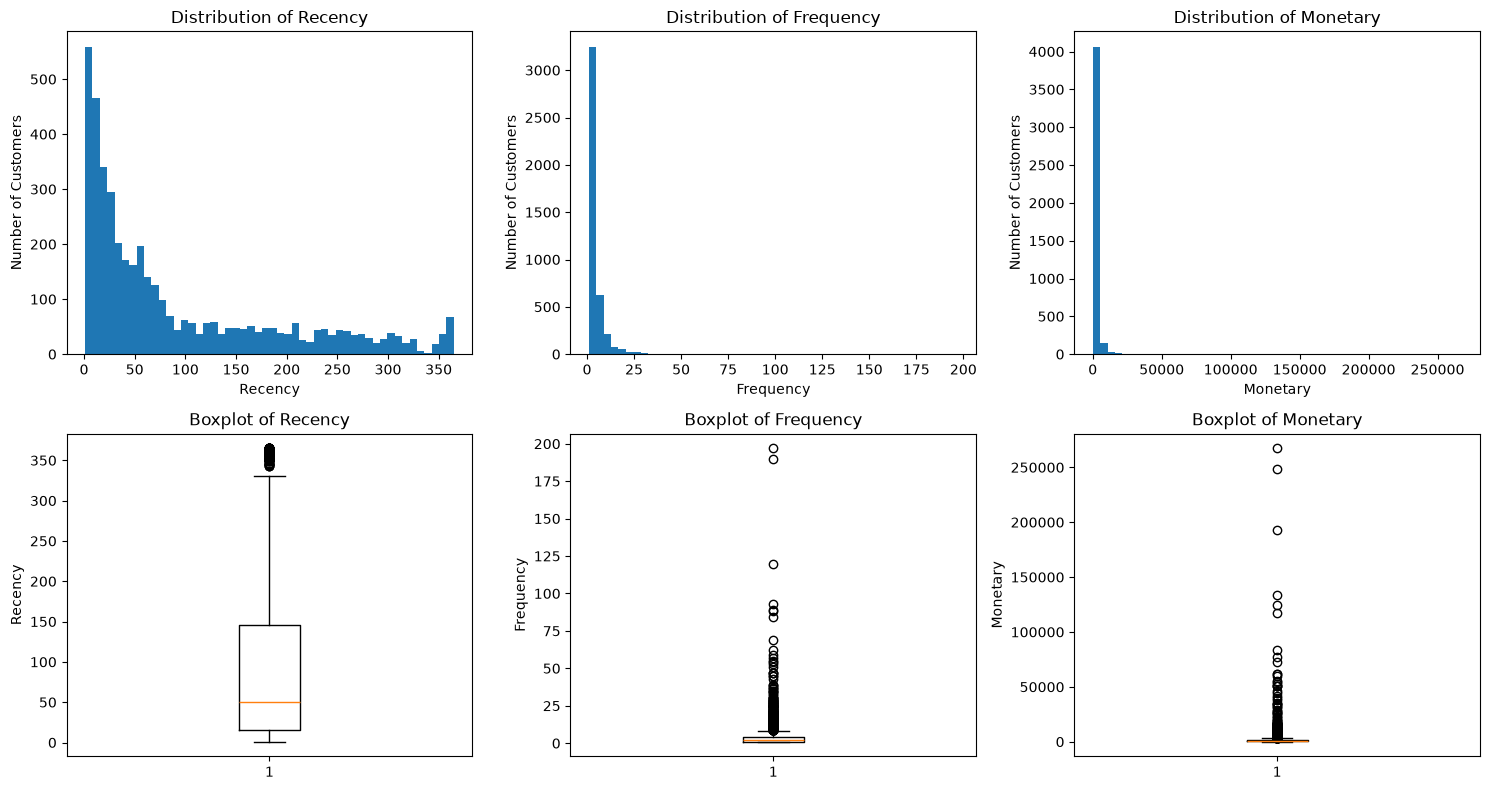

In [87]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(["Recency", "Frequency", "Monetary"]):
    axes[0,i].hist(rfm[col], bins=50)
    axes[0,i].set_title(f"Distribution of {col}")
    axes[0,i].set_xlabel(col)
    axes[0,i].set_ylabel("Number of Customers")

    axes[1,i].boxplot(rfm[col])
    axes[1,i].set_title(f"Boxplot of {col}")
    axes[1,i].set_ylabel(col)

plt.tight_layout()
plt.show()

`StandardScaler` is a machine learning tool that standardises numeric features by subtracting the mean (μ) and dividing by the standard deviation (σ) for each column. This transforms data to have a mean of 0 and a standard deviation of 1.

In [88]:
rfm_log = np.log1p(rfm)

scaler = StandardScaler()
rfm_scaled = pd.DataFrame(scaler.fit_transform(rfm_log),
                          index=rfm.index,
                          columns=rfm.columns)

print(rfm_scaled.describe())

            Recency     Frequency      Monetary
count  4.294000e+03  4.294000e+03  4.294000e+03
mean  -3.938267e-16  3.789341e-16 -2.846142e-16
std    1.000116e+00  1.000116e+00  1.000116e+00
min   -2.338714e+00 -9.344805e-01 -4.166742e+00
25%   -7.384932e-01 -9.344805e-01 -6.737311e-01
50%    8.298712e-02 -3.320151e-01 -5.717071e-02
75%    8.745538e-01  4.270015e-01  6.471085e-01
max    1.556646e+00  5.893236e+00  4.766749e+00


Exploratory analysis showed all three features were heavily right-skewed, with a small number of wholesale customers holding extreme Frequency and Monetary values (Monetary reaching £279,138 against a median of £668). Because K-Means++ relies on Euclidean distance, such extreme values would dominate the distance calculation and pull cluster centroids toward the outliers, producing segments that separate a few large accounts from everyone else rather than revealing structure across the customer base. A log transformation (log1p) was therefore applied to compress the long right tails and reduce the influence of these extreme values, while preserving the relative ordering of customers. Following the log transformation, the features were standardised using StandardScaler to zero mean and unit variance.

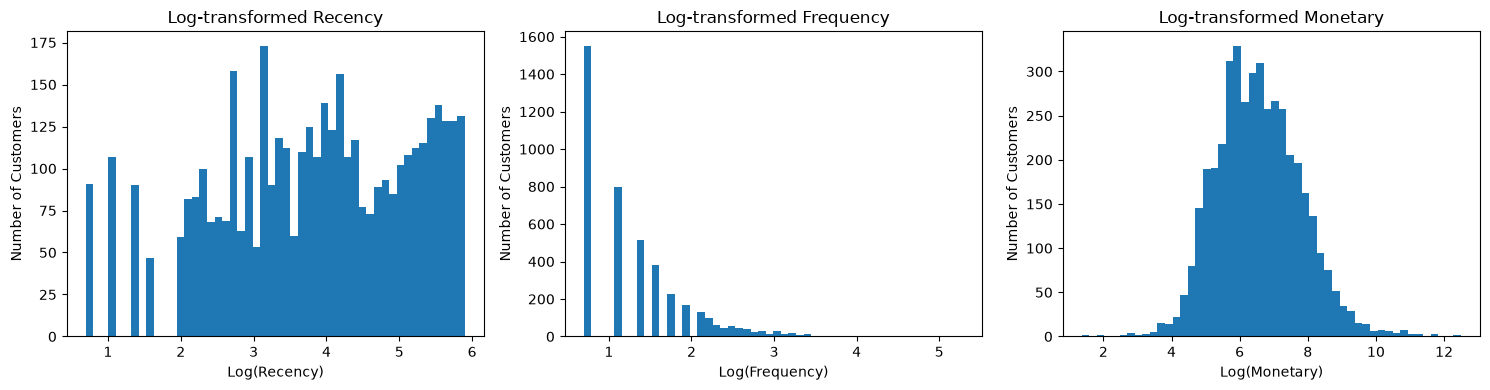

In [89]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(["Recency", "Frequency", "Monetary"]):
    axes[i].hist(rfm_log[col], bins=50)
    axes[i].set_title(f"Log-transformed {col}")
    axes[i].set_xlabel(f"Log({col})")
    axes[i].set_ylabel("Number of Customers")
plt.tight_layout()
plt.show()

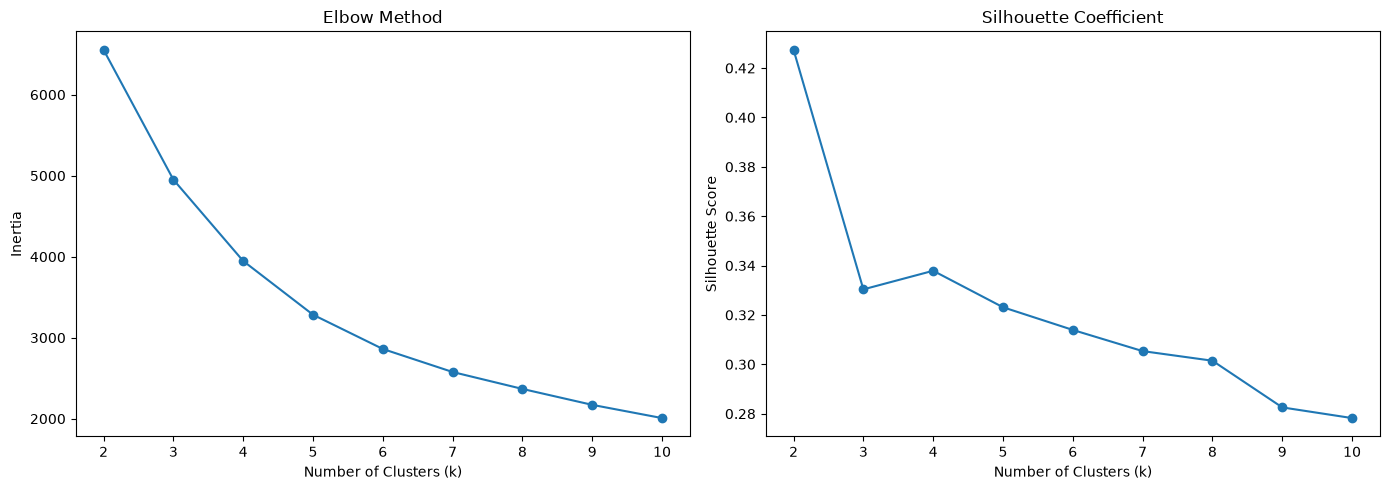

k=2: silhouette=0.4274
k=3: silhouette=0.3304
k=4: silhouette=0.3379
k=5: silhouette=0.3231
k=6: silhouette=0.3139
k=7: silhouette=0.3054
k=8: silhouette=0.3015
k=9: silhouette=0.2826
k=10: silhouette=0.2782


In [90]:
inertia = []
silhouette = []
k_range = range(2, 11)

for k in k_range:
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    labels = km.fit_predict(rfm_scaled)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(rfm_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(k_range), inertia, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(list(k_range), silhouette, marker="o")
axes[1].set_title("Silhouette Coefficient")
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

for k, s in zip(k_range, silhouette):
    print(f"k={k}: silhouette={s:.4f}")

The Elbow Method examines inertia, the total within-cluster sum of squared distances between each point and its assigned centroid. Inertia always falls as the number of clusters increases, since more clusters allow tighter groupings, so the aim is not to minimise it but to locate the point where the rate of decrease slows markedly. This bend, or "elbow," indicates the value of k beyond which adding further clusters yields diminishing returns. As shown in the figure, inertia falls steeply from k=2 to k=4 and then flattens, placing the elbow at approximately k=4.

The Silhouette Coefficient measures how well separated the clusters are by comparing each point's average distance to members of its own cluster against its distance to the nearest neighbouring cluster. Scores range from -1 to 1, where higher values indicate denser, better-separated clusters. The highest score occurs at k=2 (0.427), after which the score drops at k=3 and recovers to a local peak at k=4 (0.338) before declining steadily.

Although k=2 records the highest silhouette score, it was not selected. Two clusters provide only a coarse separation of the customer base, most likely dividing customers into a single high-value group and a large low-value group, which offers limited analytical value and insufficient resolution to observe the segment-level dynamics central to this research. The elevated score at k=2 also reflects the strong right-skew of the RFM features, where a small high-value group separates easily from the majority, rather than indicating a genuinely informative segmentation.

The value k=4 was therefore selected. It coincides with the elbow in the inertia curve, corresponds to a local recovery in the silhouette score, and retains a moderate silhouette value indicating reasonable cluster separation. Four segments also align with established RFM-based segmentation studies, which commonly identify four customer tiers, and provide sufficient granularity to define meaningful behavioural archetypes and to track customer movement between segments across time windows. The moderate silhouette value is expected for RFM data, as customer behaviour tends to form a continuous gradient rather than sharply separated groups.

In [91]:
k = 4
kmeans = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

print(rfm["Cluster"].value_counts().sort_index())

Cluster
0    1189
1    1560
2     851
3     694
Name: count, dtype: int64


In [92]:
profile = rfm.groupby("Cluster").agg(Count=("Recency", "size"),
                                     Avg_Recency=("Recency", "mean"),
                                     Avg_Frequency=("Frequency", "mean"),
                                     Avg_Monetary=("Monetary", "mean"),
                                     Median_Recency=("Recency", "median"),
                                     Median_Frequency=("Frequency", "median"),
                                     Median_Monetary=("Monetary", "median")).round(2)

profile["Pct"] = (profile["Count"] / profile["Count"].sum() * 100).round(1)
profile

,Count,Avg_Recency,Avg_Frequency,Avg_Monetary,Median_Recency,Median_Frequency,Median_Monetary,Pct
Cluster,,,,,,,,
0,1189,67.37,3.98,1718.26,52.0,4.0,1316.07,27.7
1,1560,185.42,1.31,343.32,180.0,1.0,294.90,36.3
2,851,17.97,1.93,488.94,15.0,2.0,414.20,19.8
3,694,12.94,13.28,7579.02,9.0,10.0,3534.04,16.2


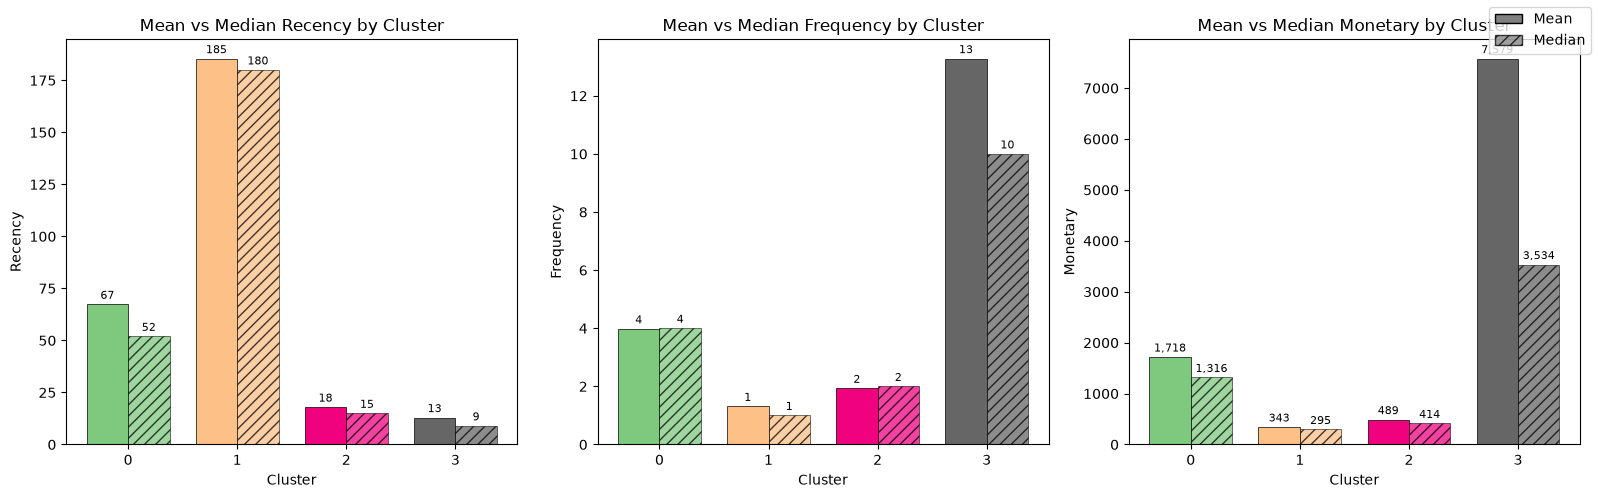

In [93]:
# Compute both statistics
stats = rfm.groupby("Cluster").agg(Recency_mean=("Recency", "mean"), 
                                   Recency_median=("Recency", "median"),
                                   Frequency_mean=("Frequency", "mean"), 
                                   Frequency_median=("Frequency", "median"),
                                   Monetary_mean=("Monetary", "mean"), 
                                   Monetary_median=("Monetary", "median"))

clusters = stats.index.astype(str)
x = np.arange(len(clusters))
width = 0.38
colors = plt.cm.Accent(np.linspace(0, 1, len(clusters)))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axes, ["Recency", "Frequency", "Monetary"]):
    means = stats[f"{col}_mean"]
    medians = stats[f"{col}_median"]

    bars_mean = ax.bar(x - width/2, means, width, color=colors, edgecolor="black", linewidth=0.5)
    bars_median = ax.bar(x + width/2, medians, width, color=colors, edgecolor="black",
                         linewidth=0.5, hatch="///", alpha=0.75)

    ax.set_title(f"Mean vs Median {col} by Cluster")
    ax.set_xlabel("Cluster")
    ax.set_ylabel(col)
    ax.set_xticks(x)
    ax.set_xticklabels(clusters)
    ax.bar_label(bars_mean, fmt=lambda v: f"{v:,.0f}", padding=2, fontsize=8)
    ax.bar_label(bars_median, fmt=lambda v: f"{v:,.0f}", padding=2, fontsize=8)

# Legend distinguishing mean vs median (cluster colour shown on x-axis)
from matplotlib.patches import Patch
legend_elems = [
    Patch(facecolor="gray", edgecolor="black", label="Mean"),
    Patch(facecolor="gray", edgecolor="black", hatch="///", alpha=0.75, label="Median"),
]
fig.legend(handles=legend_elems, loc="upper right")

plt.tight_layout()
plt.show()

| Cluster | Label | Size | Profile signature |
|---|---|---|---|
| 3 | Platinum | 694 (16.2%) | Purchased within 9 days (median), median 10 transactions, highest spend |
| 0 | Gold | 1,189 (27.7%) | Purchased within 52 days (median), median 4 transactions, medium spend |
| 2 | Iron | 851 (19.8%) | Purchased within 15 days (median), median 2 transactions, low spend |
| 1 | Lead | 1,560 (36.3%) | Last purchase 180 days ago (median), median 1 transaction, lowest spend |

Cluster 3 — Platinum (694 customers, 16.2%). They purchased very recently (median Recency 9 days), buy often (median Frequency 10, average 13.3), and spend by far the most (median £3,534, average £7,579). These are the loyal, high-frequency accounts, very likely the wholesalers. Small in number but commercially the most important group.

Cluster 0 — Gold (1,189 customers, 27.7%). A solid, engaged segment sitting below the top tier. Recent (median Recency 52 days), moderately frequent (median Frequency 4), with healthy spend (median £1,316). They are regular repeat buyers without reaching the volume of Cluster 3. This is a large, stable core of the customer base.

Cluster 2 — Iron (851 customers, 19.8%). Their defining trait is very low Recency (median 15 days) but low Frequency (median 2) and modest spend (median £414). They have purchased recently but not much yet. This is the "new or recently acquired" segment, customers who have just started buying and could either develop into loyal ones or lapse. The behavioural opposite of dormant.

Cluster 1 — Lead (1,560 customers, 36.3%). The largest segment and the most at-risk. They last purchased long ago (median Recency 180 days), almost always just once (median Frequency 1), and spent little (median £295). These are one-time or long-inactive buyers who have effectively churned. That over a third of customers fall here is consistent with the EDA finding (Customer Activity Analysis) that a large share of the base are single-purchase customers.

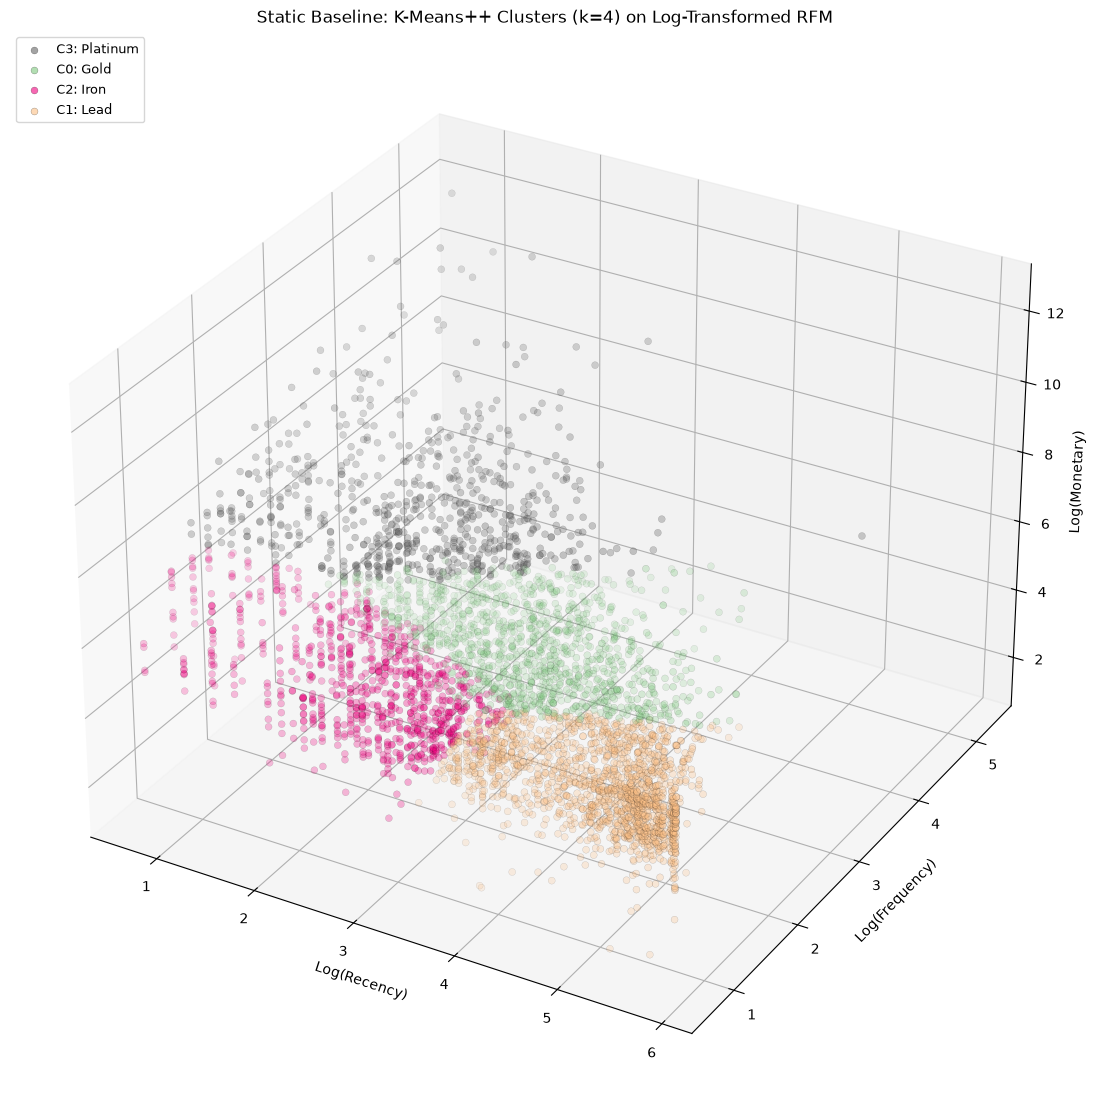

In [94]:
# Plot on the log scale 
plot_df = np.log1p(rfm[["Recency", "Frequency", "Monetary"]]).copy()
plot_df["Cluster"] = rfm["Cluster"].values

fig = plt.figure(figsize=(11, 14))
ax = fig.add_subplot(111, projection="3d")

colors = plt.cm.Accent(np.linspace(0, 1, 4))
labels = {3: "Platinum",
          0: "Gold",
          2: "Iron",
          1: "Lead"}

for c in [3, 0, 2, 1]:
    sub = plot_df[plot_df["Cluster"] == c]
    ax.scatter(sub["Recency"], sub["Frequency"], sub["Monetary"],
               s=25, alpha=0.6, color=colors[c], edgecolor="k", linewidth=0.2,
               label=f"C{c}: {labels[c]}")

ax.set_xlabel("Log(Recency)")
ax.set_ylabel("Log(Frequency)")
ax.set_zlabel("Log(Monetary)")
ax.set_title("Static Baseline: K-Means++ Clusters (k=4) on Log-Transformed RFM")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

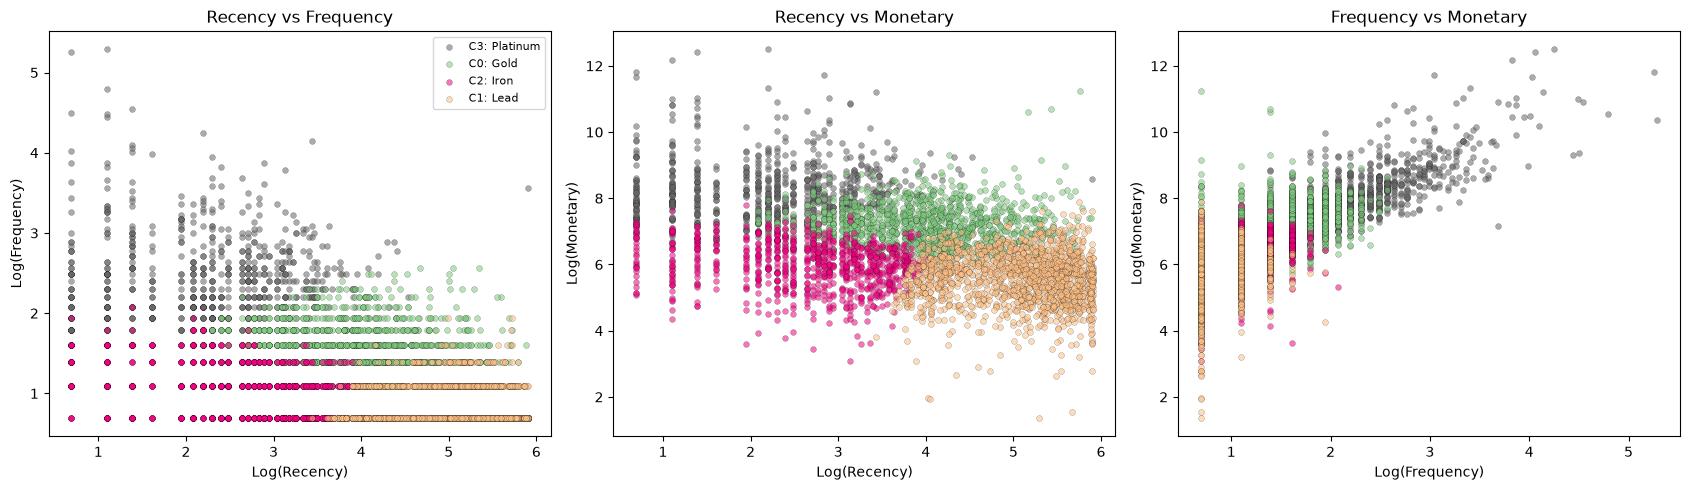

In [95]:
pairs = [("Recency", "Frequency"), ("Recency", "Monetary"), ("Frequency", "Monetary")]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (xcol, ycol) in zip(axes, pairs):
    for c in [3, 0, 2, 1]:
        sub = plot_df[plot_df["Cluster"] == c]
        ax.scatter(sub[xcol], sub[ycol], s=18, alpha=0.55,
                   color=colors[c], edgecolor="k", linewidth=0.2,
                   label=f"C{c}: {labels[c]}")
    ax.set_xlabel(f"Log({xcol})")
    ax.set_ylabel(f"Log({ycol})")
    ax.set_title(f"{xcol} vs {ycol}")

axes[0].legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

In [96]:
# C3: Platinum
c3_customers = rfm[rfm["Cluster"] == 3].index
c3_txns = df_static[df_static["CustomerID"].isin(c3_customers)]
c3_txns.groupby(c3_txns["InvDate"].dt.to_period("M"))["InvoiceNo"].nunique()

InvDate
2010-12     774
2011-01     535
2011-02     515
2011-03     668
2011-04     586
2011-05     826
2011-06     735
2011-07     704
2011-08     694
2011-09     877
2011-10     876
2011-11    1426
Freq: M, Name: InvoiceNo, dtype: int64

Cluster 3 (Platinum) is active every month, and heavily so. Their invoices run from around 515 to nearly 900 across the year, then jump to 1,426 in November. These are the customers who buy consistently all year and also ramp up for the holiday season.

In [97]:
# C0: Gold 
c0_customers = rfm[rfm["Cluster"] == 0].index
c0_txns = df_static[df_static["CustomerID"].isin(c0_customers)]
c0_txns.groupby(c0_txns["InvDate"].dt.to_period("M"))["InvoiceNo"].nunique()

InvDate
2010-12    342
2011-01    274
2011-02    276
2011-03    357
2011-04    339
2011-05    473
2011-06    417
2011-07    385
2011-08    377
2011-09    545
2011-10    563
2011-11    382
Freq: M, Name: InvoiceNo, dtype: int64

Cluster 0 (Gold) is similarly active across the whole year, ranging from roughly 274 to 563 invoices per month, with a rise in September and October. The one telling detail is that November drops to 382, below its September–October peak. This suggests Cluster 0 are steady, all-year buyers whose most recent purchase tends to fall a little before the very end of the period, which fits their median Recency of 52 days. They are engaged, but not concentrated at the holiday peak the way Cluster 2 is.

In [98]:
# C1: Lead
c1_customers = rfm[rfm["Cluster"] == 1].index
c1_txns = df_static[df_static["CustomerID"].isin(c1_customers)]
c1_txns.groupby(c1_txns["InvDate"].dt.to_period("M"))["InvoiceNo"].nunique()

InvDate
2010-12    224
2011-01    151
2011-02    168
2011-03    242
2011-04    179
2011-05    196
2011-06    183
2011-07    175
2011-08    143
2011-09    210
2011-10    175
2011-11      1
Freq: M, Name: InvoiceNo, dtype: int64

Cluster 1 (Lead). Their activity is spread across the earlier months (151 to 242 invoices) and then collapses to a single invoice in November. This is exactly what "inactive" should look like from a 1 December snapshot: these customers were active earlier in the year and then stopped, which is why their median Recency is 180 days. The near-total absence in November is the signature of a lapsed segment.

In [99]:
# C2: Iron
c2_customers = rfm[rfm["Cluster"] == 2].index
c2_txns = df_static[df_static["CustomerID"].isin(c2_customers)]
c2_txns.groupby(c2_txns["InvDate"].dt.to_period("M"))["InvoiceNo"].nunique()

InvDate
2010-12     56
2011-01     24
2011-02     33
2011-03     45
2011-04     36
2011-05     50
2011-06     55
2011-07     57
2011-08     54
2011-09    110
2011-10    291
2011-11    835
Freq: M, Name: InvoiceNo, dtype: int64

Cluster 2 (Iron) shows the sharp late-year concentration, flat through mid-year then surging to 835 in November.

In [100]:
# Rename to make the source explicit
rfm = rfm.rename(columns={"Cluster": "cluster_static"})

# Add readable archetype names alongside the numeric label
archetype_map = {
    3: "Platinum",
    0: "Gold",
    2: "Iron",
    1: "Lead",
}
rfm["archetype_static"] = rfm["cluster_static"].map(archetype_map)

# Dedicated lookup table for joining window labels onto later
customer_labels = rfm[["cluster_static", "archetype_static"]].copy()

print(customer_labels["archetype_static"].value_counts())
customer_labels.head()

archetype_static
Lead        1560
Gold        1189
Iron         851
Platinum     694
Name: count, dtype: int64


,cluster_static,archetype_static
CustomerID,,
12346,0,Gold
12347,0,Gold
12348,0,Gold
12349,2,Iron
12350,1,Lead


---

## **Temporal Windowing**

In [101]:
# Define the four quarterly windows: (label, start inclusive, end exclusive)
windows = [
    ("W1", "2010-12-01", "2011-03-01"),
    ("W2", "2011-03-01", "2011-06-01"),
    ("W3", "2011-06-01", "2011-09-01"),
    ("W4", "2011-09-01", "2011-12-01"),
]

def build_window_rfm(df, start, end):
    mask = (df["InvDate"] >= start) & (df["InvDate"] < end)
    win = df[mask]
    snapshot = pd.to_datetime(end)  # day after the window's last day
    rfm_w = win.groupby("CustomerID").agg(
        Recency=("InvDate", lambda x: (snapshot - x.max()).days),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("TotalPrice", "sum"),
    )
    return rfm_w

# Build all four and store them in a dictionary
rfm_windows = {}
for label, start, end in windows:
    rfm_windows[label] = build_window_rfm(df, start, end)
    print(f"{label} ({start} to {end}): {len(rfm_windows[label]):,} active customers")

W1 (2010-12-01 to 2011-03-01): 1,681 active customers
W2 (2011-03-01 to 2011-06-01): 1,992 active customers
W3 (2011-06-01 to 2011-09-01): 1,944 active customers
W4 (2011-09-01 to 2011-12-01): 2,846 active customers


In [102]:
for label in rfm_windows:
    print(f"\n===== {label} =====")
    print(rfm_windows[label].describe().round(2))


===== W1 =====
       Recency  Frequency  Monetary
count  1681.00    1681.00   1681.00
mean     39.20       2.01    937.44
std      28.88       2.45   3094.88
min       1.00       1.00      0.85
25%      13.00       1.00    211.80
50%      33.00       1.00    389.50
75%      71.00       2.00    793.98
max      90.00      44.00  77183.60

===== W2 =====
       Recency  Frequency  Monetary
count  1992.00    1992.00   1992.00
mean     36.94       2.01    854.36
std      26.03       2.38   2241.60
min       1.00       1.00      2.90
25%      14.00       1.00    226.69
50%      28.00       1.00    394.86
75%      57.25       2.00    814.99
max      92.00      41.00  52454.10

===== W3 =====
       Recency  Frequency  Monetary
count  1944.00    1944.00   1944.00
mean     38.55       2.05    969.82
std      26.44       2.43   3328.83
min       1.00       1.00      5.90
25%      15.00       1.00    221.11
50%      34.00       1.00    405.69
75%      59.00       2.00    835.96
max      92.00  

---

## **Temporal Clustering**

W1: k=2:0.413, k=3:0.379, k=4:0.378, k=5:0.292, k=6:0.288, k=7:0.310, k=8:0.308, k=9:0.315, k=10:0.315
W2: k=2:0.437, k=3:0.353, k=4:0.350, k=5:0.296, k=6:0.296, k=7:0.307, k=8:0.305, k=9:0.307, k=10:0.312
W3: k=2:0.418, k=3:0.342, k=4:0.357, k=5:0.289, k=6:0.298, k=7:0.301, k=8:0.304, k=9:0.296, k=10:0.304
W4: k=2:0.430, k=3:0.326, k=4:0.338, k=5:0.292, k=6:0.292, k=7:0.299, k=8:0.296, k=9:0.301, k=10:0.300


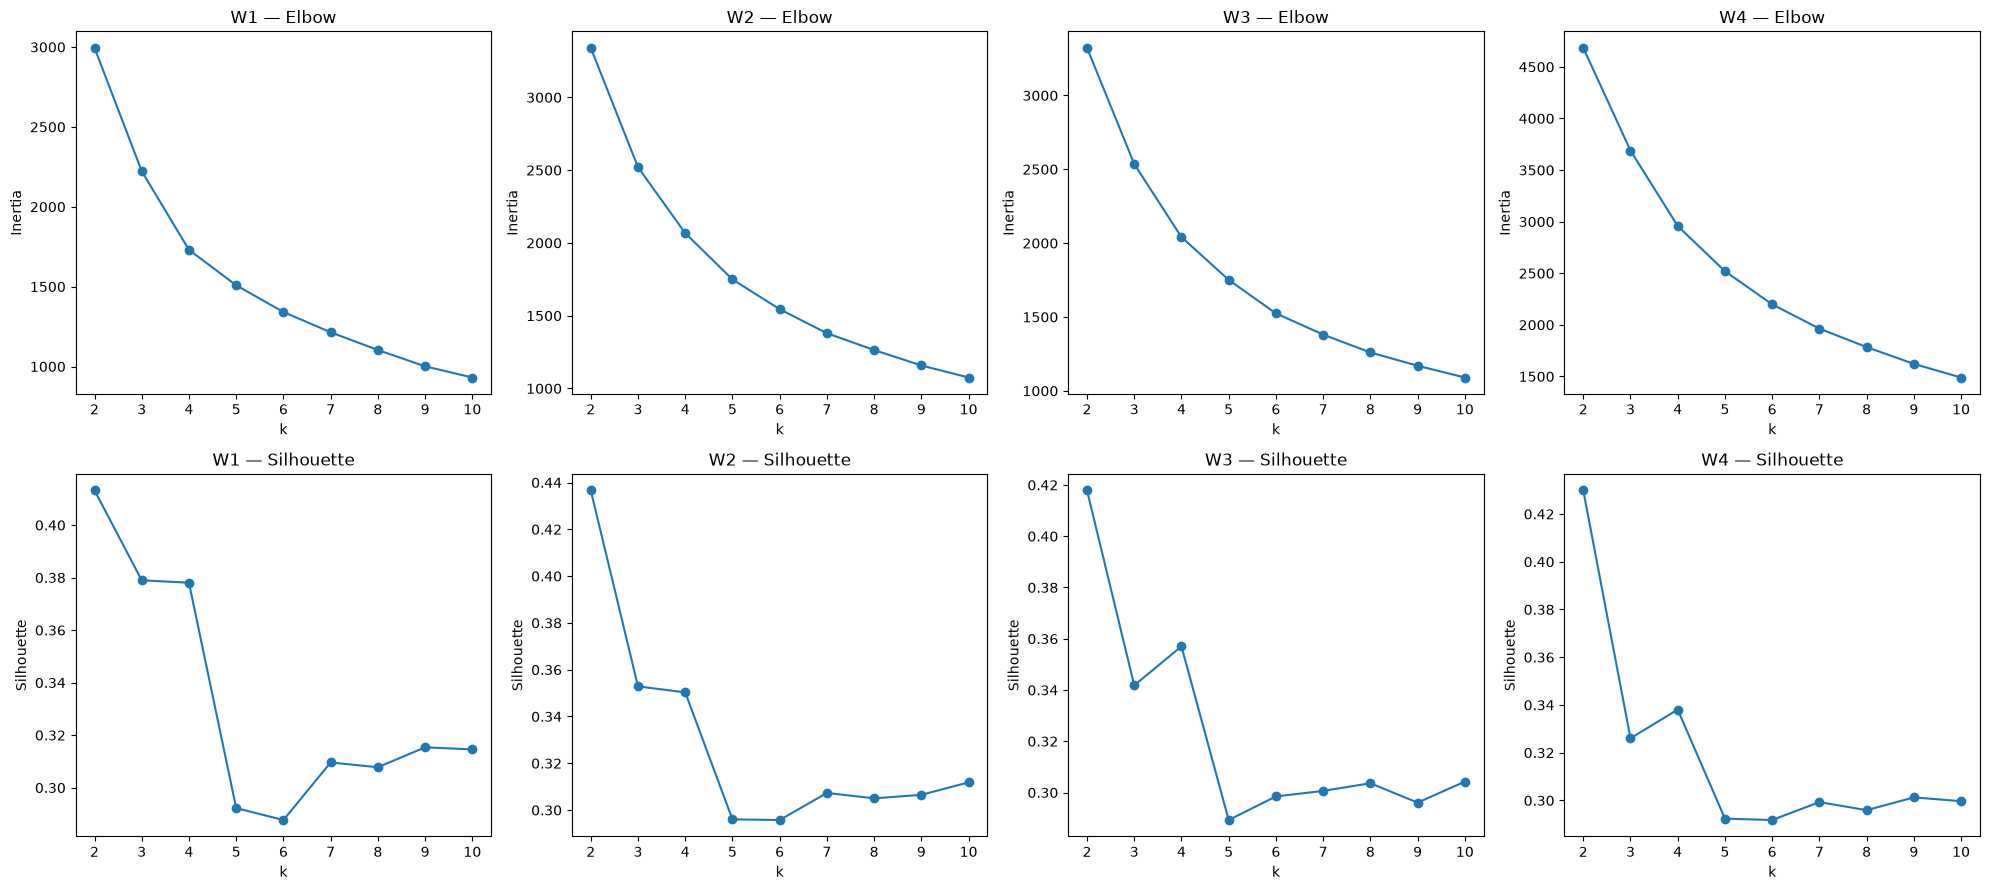

In [103]:
rfm_windows_scaled = {}

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
k_range = range(2, 11)

for j, label in enumerate(rfm_windows):
    rfm_w = rfm_windows[label]
    scaled = StandardScaler().fit_transform(np.log1p(rfm_w))
    rfm_windows_scaled[label] = scaled

    inertia, silhouette = [], []
    for k in k_range:
        km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
        lbls = km.fit_predict(scaled)
        inertia.append(km.inertia_)
        silhouette.append(silhouette_score(scaled, lbls))

    axes[0,j].plot(list(k_range), inertia, marker="o")
    axes[0,j].set_title(f"{label} — Elbow")
    axes[0,j].set_xlabel("k")
    axes[0,j].set_ylabel("Inertia")

    axes[1,j].plot(list(k_range), silhouette, marker="o")
    axes[1,j].set_title(f"{label} — Silhouette")
    axes[1,j].set_xlabel("k")
    axes[1,j].set_ylabel("Silhouette")

    print(f"{label}: " + ", ".join(f"k={k}:{s:.3f}" for k, s in zip(k_range, silhouette)))

plt.tight_layout()
plt.show()

In [104]:
window_models = {}
window_labels = {}
window_profiles = {}

for label in rfm_windows:
    rfm_w = rfm_windows[label].copy()
    scaled = rfm_windows_scaled[label]

    km = KMeans(n_clusters=4, init="k-means++", n_init=10, random_state=42)
    rfm_w["Cluster"] = km.fit_predict(scaled)

    window_models[label] = km
    window_labels[label] = rfm_w[["Cluster"]].rename(columns={"Cluster": f"cluster_{label}"})

    prof = rfm_w.groupby("Cluster").agg(
        Count=("Recency", "size"),
        Med_Recency=("Recency", "median"),
        Med_Frequency=("Frequency", "median"),
        Med_Monetary=("Monetary", "median"),
        Avg_Monetary=("Monetary", "mean"),
    ).round(2)
    prof["Pct"] = (prof["Count"] / prof["Count"].sum() * 100).round(1)
    window_profiles[label] = prof

    print(f"\n===== {label} =====")
    print(prof)


===== W1 =====
         Count  Med_Recency  Med_Frequency  Med_Monetary  Avg_Monetary   Pct
Cluster                                                                     
0          169          7.0            5.0       1987.91       4020.28  10.1
1          442         32.0            2.0        818.03       1292.36  26.3
2          766         69.0            1.0        238.08        260.27  45.6
3          304          7.0            1.0        330.12        413.91  18.1

===== W2 =====
         Count  Med_Recency  Med_Frequency  Med_Monetary  Avg_Monetary   Pct
Cluster                                                                     
0          194          8.0            5.0       1986.10       3914.12   9.7
1          899         61.0            1.0        281.66        316.15  45.1
2          502         22.0            2.0        843.06       1052.07  25.2
3          397         13.0            1.0        302.40        327.92  19.9

===== W3 =====
         Count  Med_Recency 

In [105]:
# Align each window's clusters with the baseline archetypes.
# Window and baseline centroids are both in standardised log-RFM space. The assignment is
# solved as a one-to-one matching (Hungarian algorithm) on Euclidean distance, so no two
# window clusters can receive the same archetype. When every window cluster's nearest
# baseline centroid is already distinct, the Hungarian solution equals the nearest match.
baseline_centroids = kmeans.cluster_centers_
baseline_names = {3: "Platinum", 0: "Gold", 2: "Iron", 1: "Lead"}

matched_labels = {}

for label in rfm_windows:
    win_centroids = window_models[label].cluster_centers_
    cost = np.linalg.norm(win_centroids[:, None, :] - baseline_centroids[None, :, :], axis=2)

    rows, cols = linear_sum_assignment(cost)
    mapping = {int(r): baseline_names[int(c)] for r, c in zip(rows, cols)}
    nearest = {i: baseline_names[int(np.argmin(cost[i]))] for i in range(len(cost))}

    print(f"{label} mapping: {mapping} | same as nearest-centroid match: {mapping == nearest} | "
          f"matched distances: {np.round(cost[rows, cols], 3).tolist()}")

    lbl_df = window_labels[label].copy()
    lbl_df[f"archetype_{label}"] = lbl_df[f"cluster_{label}"].map(mapping)
    matched_labels[label] = lbl_df

W1 mapping: {0: 'Platinum', 1: 'Gold', 2: 'Lead', 3: 'Iron'} | same as nearest-centroid match: True | matched distances: [0.532, 0.197, 0.307, 0.515]
W2 mapping: {0: 'Platinum', 1: 'Lead', 2: 'Gold', 3: 'Iron'} | same as nearest-centroid match: True | matched distances: [0.666, 0.316, 0.377, 0.072]
W3 mapping: {0: 'Platinum', 1: 'Iron', 2: 'Lead', 3: 'Gold'} | same as nearest-centroid match: True | matched distances: [0.42, 0.462, 0.285, 0.131]
W4 mapping: {0: 'Iron', 1: 'Lead', 2: 'Platinum', 3: 'Gold'} | same as nearest-centroid match: True | matched distances: [0.18, 0.226, 0.212, 0.061]


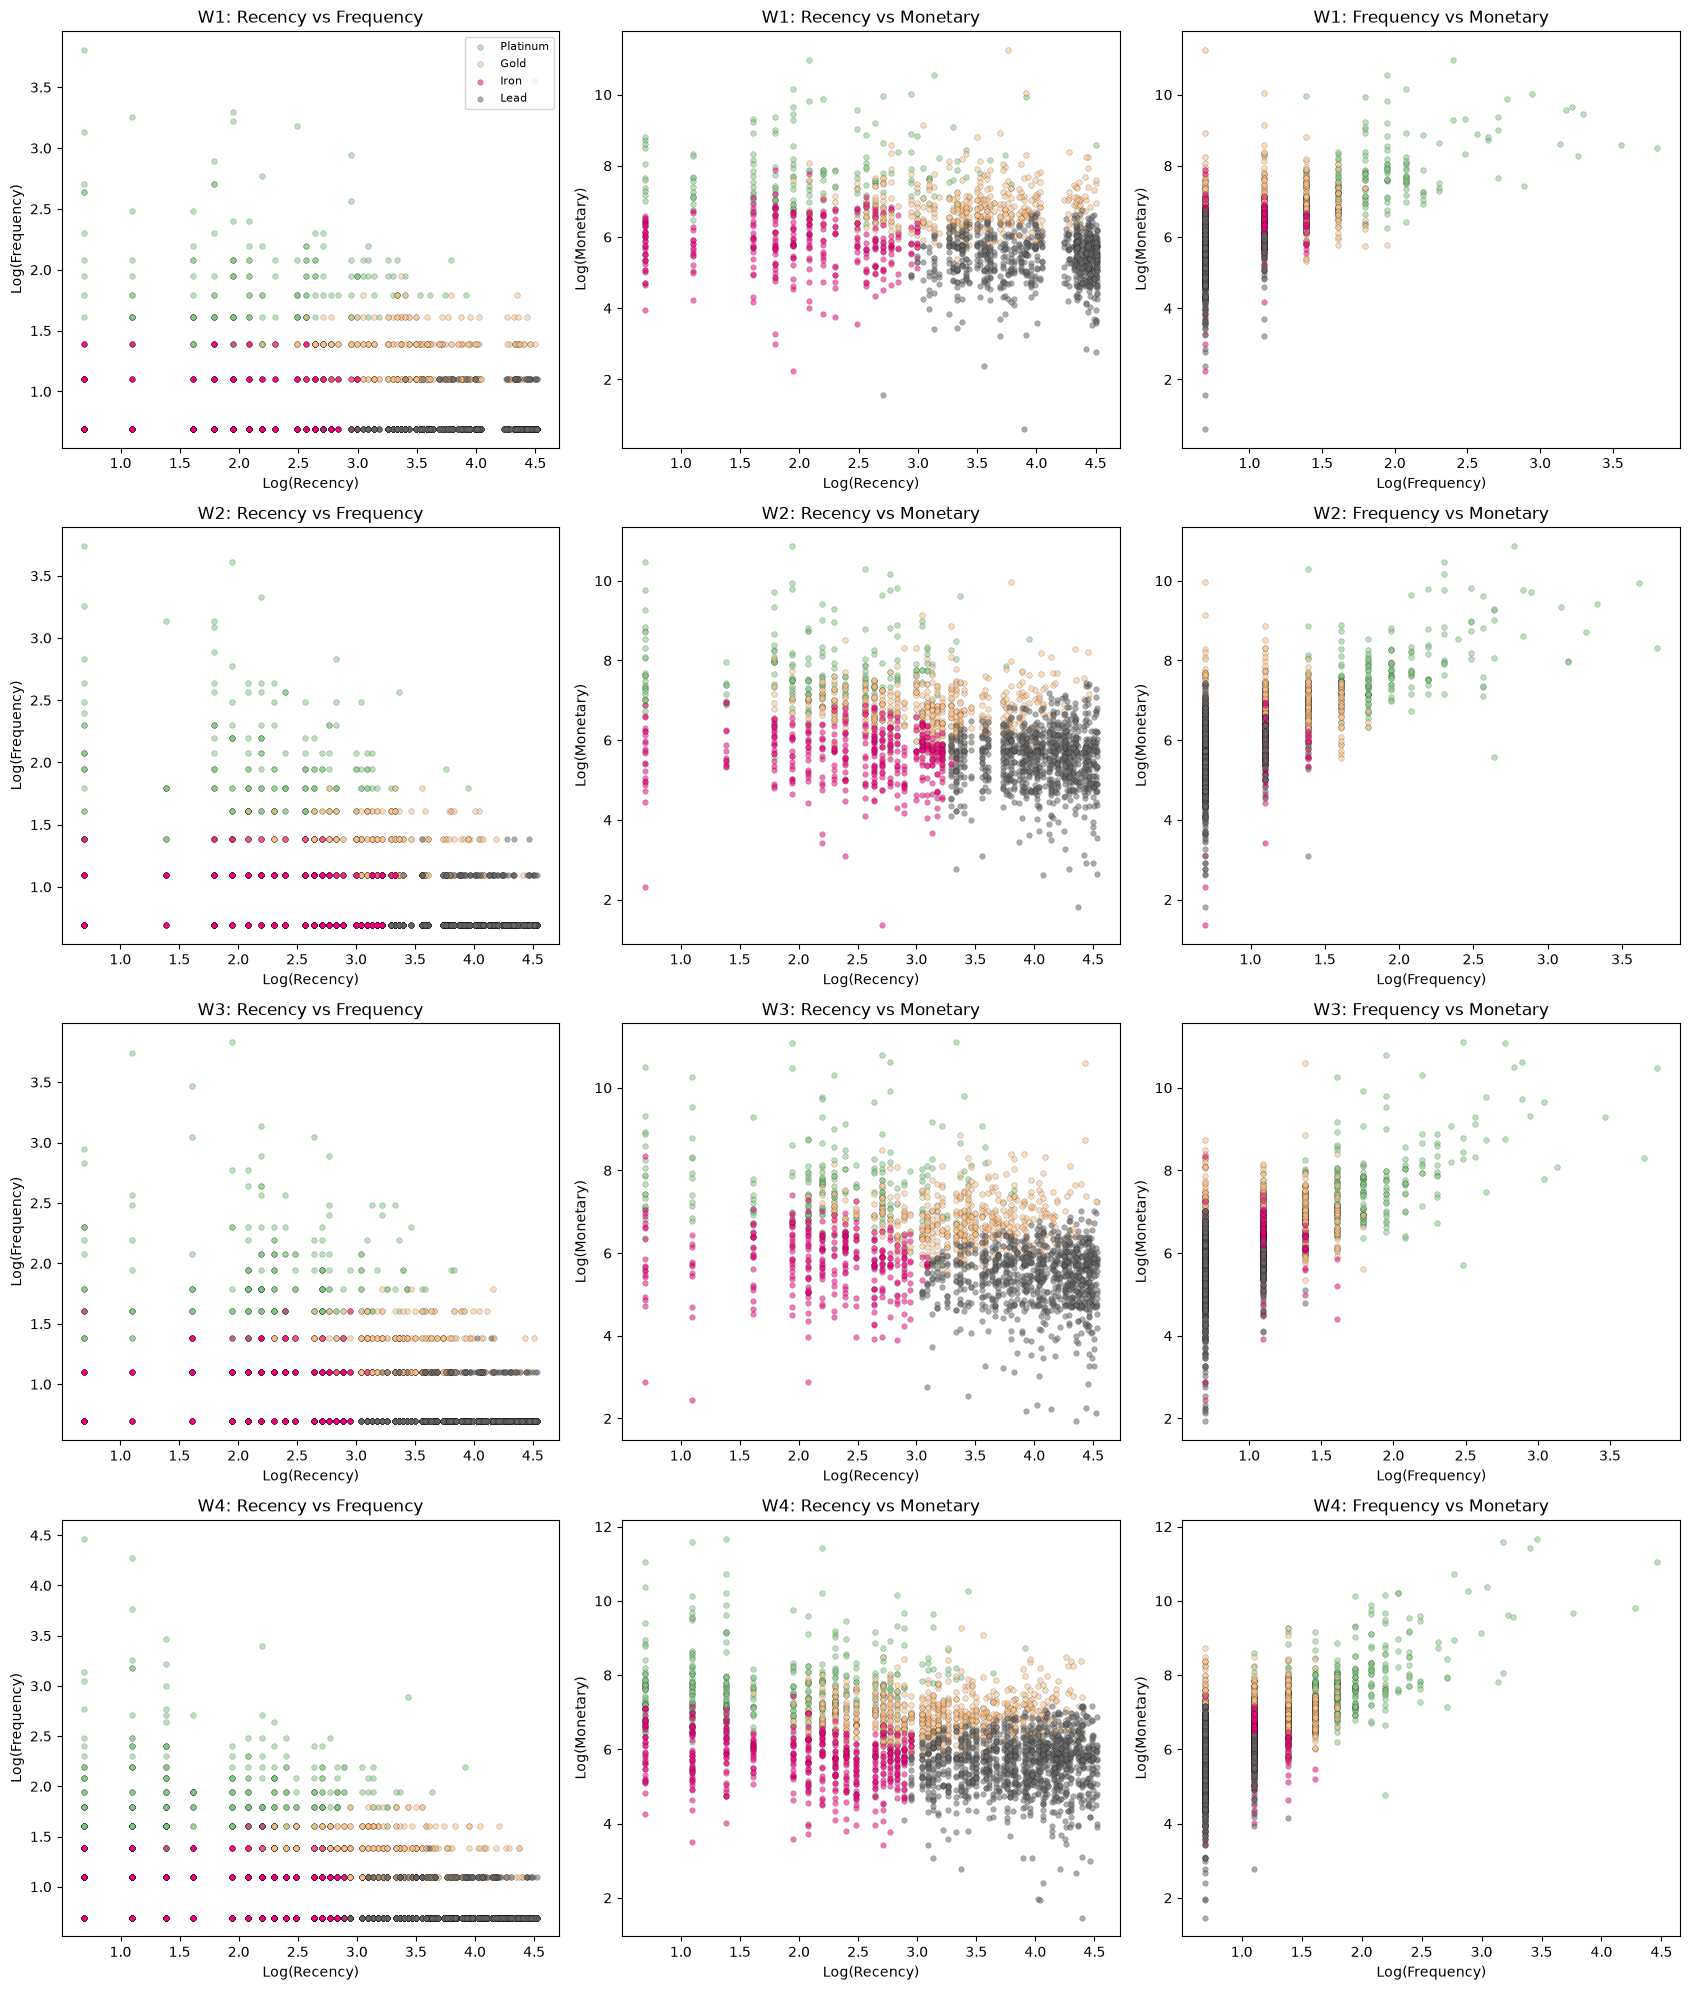

In [106]:
archetype_order = ["Platinum", "Gold", "Iron", "Lead"]
arch_colors = dict(zip(archetype_order, plt.cm.Accent(np.linspace(0, 1, 4))))
pairs = [("Recency", "Frequency"), ("Recency", "Monetary"), ("Frequency", "Monetary")]

fig, axes = plt.subplots(4, 3, figsize=(17, 20))

for i, label in enumerate(["W1", "W2", "W3", "W4"]):
    plot_df = np.log1p(rfm_windows[label][["Recency", "Frequency", "Monetary"]]).copy()
    plot_df["Archetype"] = matched_labels[label][f"archetype_{label}"].values

    for j, (xcol, ycol) in enumerate(pairs):
        ax = axes[i, j]
        for arch in archetype_order:
            sub = plot_df[plot_df["Archetype"] == arch]
            ax.scatter(sub[xcol], sub[ycol], s=16, alpha=0.55,
                       color=arch_colors[arch], edgecolor="k", linewidth=0.2,
                       label=arch)
        ax.set_xlabel(f"Log({xcol})")
        ax.set_ylabel(f"Log({ycol})")
        ax.set_title(f"{label}: {xcol} vs {ycol}")

axes[0, 0].legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

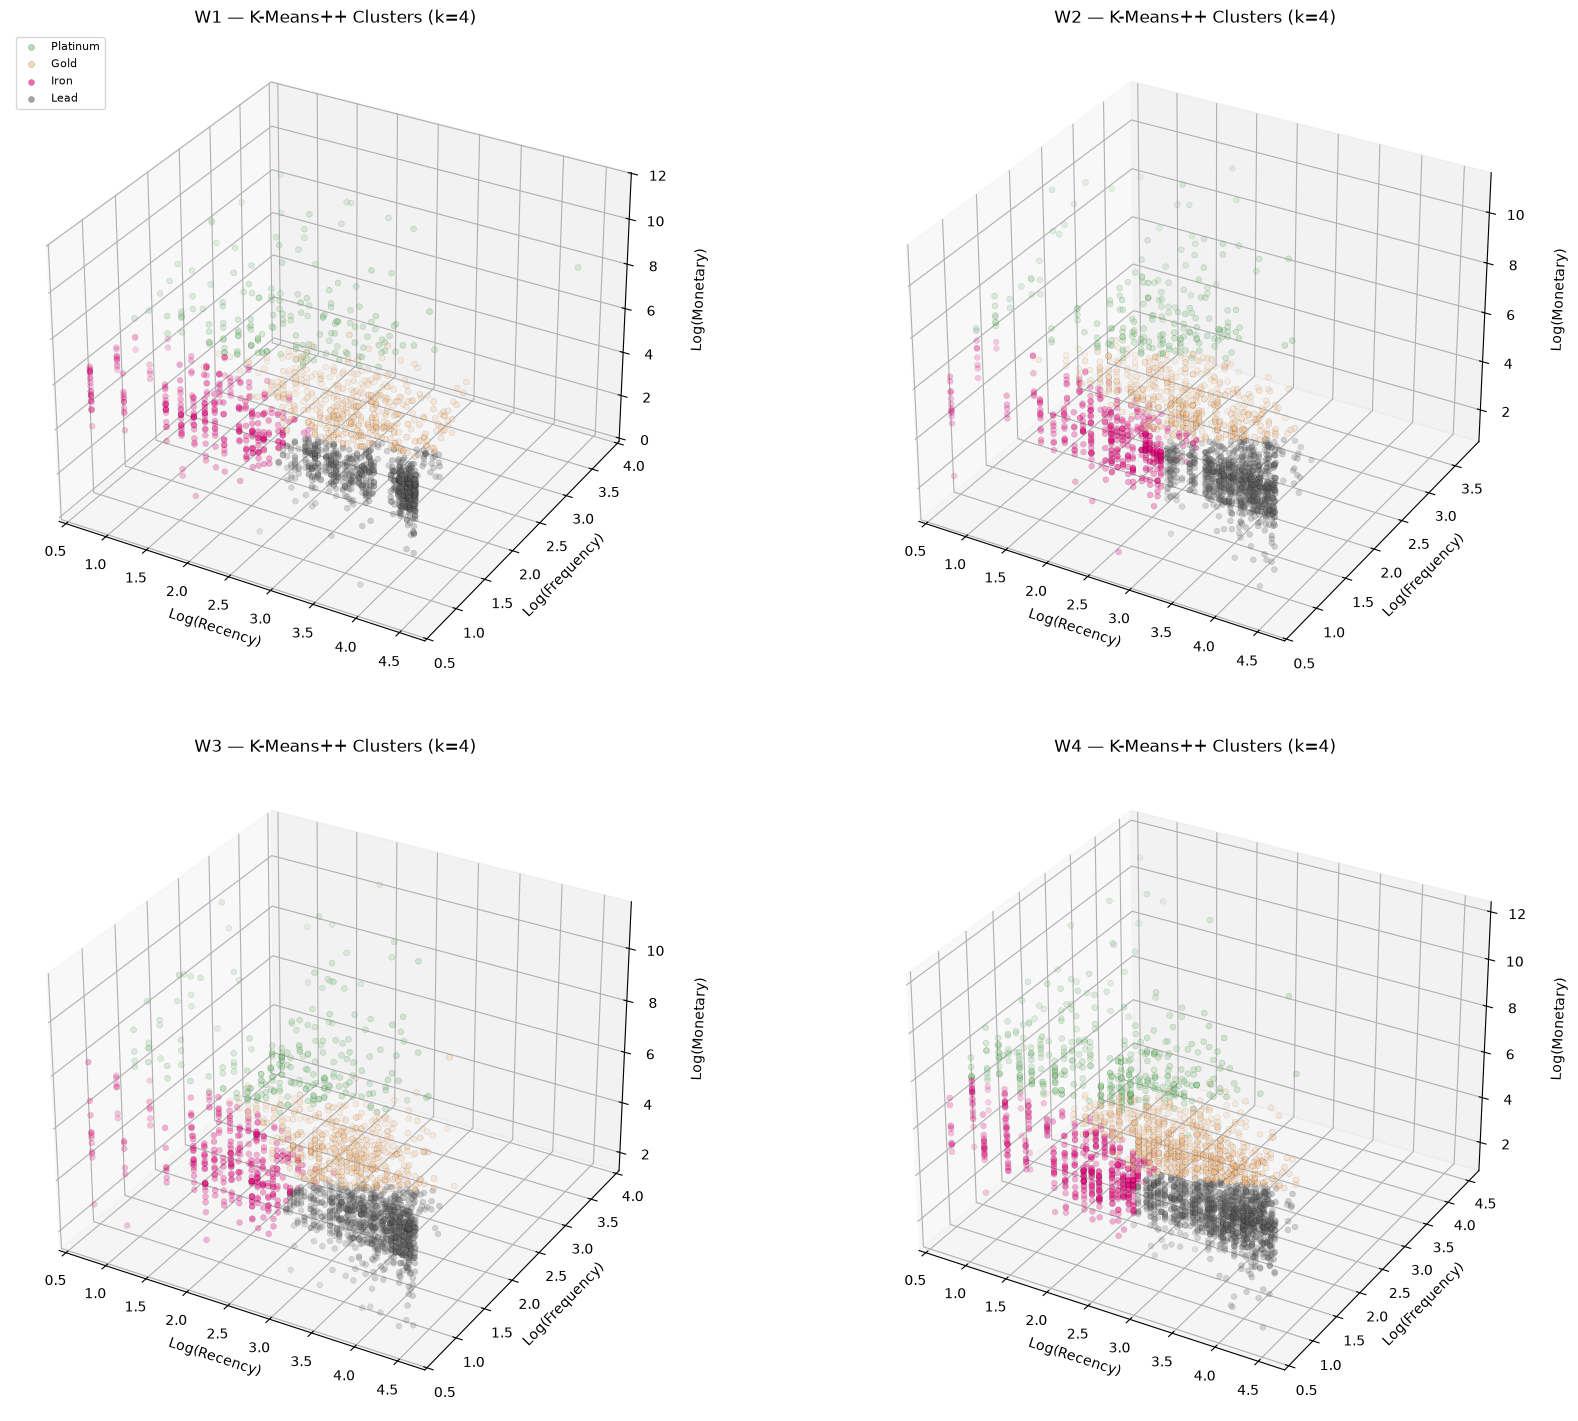

In [107]:
fig = plt.figure(figsize=(18, 15))

for i, label in enumerate(["W1", "W2", "W3", "W4"]):
    ax = fig.add_subplot(2, 2, i + 1, projection="3d")
    plot_df = np.log1p(rfm_windows[label][["Recency", "Frequency", "Monetary"]]).copy()
    plot_df["Archetype"] = matched_labels[label][f"archetype_{label}"].values

    for arch in archetype_order:
        sub = plot_df[plot_df["Archetype"] == arch]
        ax.scatter(sub["Recency"], sub["Frequency"], sub["Monetary"],
                   s=18, alpha=0.6, color=arch_colors[arch],
                   edgecolor="k", linewidth=0.2, label=arch)

    ax.set_xlabel("Log(Recency)")
    ax.set_ylabel("Log(Frequency)")
    ax.set_zlabel("Log(Monetary)", labelpad=12)
    ax.set_title(f"{label} — K-Means++ Clusters (k=4)")
    if i == 0:
        ax.legend(loc="upper left", fontsize=8)

plt.subplots_adjust(left=0.02, right=0.94, top=0.95, bottom=0.03, wspace=0.08, hspace=0.12)
plt.show()

## **RQ1: Archetype Composition and Transitions (Section IV-B)**

Table IV is built from the window profiles above, and Table V from the transition matrices below.

In [108]:
traj = customer_labels.copy()

for label in rfm_windows:
    traj = traj.join(matched_labels[label][[f"archetype_{label}"]], how="left")

# Customers not active in a window get an explicit state
for label in rfm_windows:
    traj[f"archetype_{label}"] = traj[f"archetype_{label}"].fillna("Absent")

print(f"Total customers: {len(traj):,}")
traj.head(15)

Total customers: 4,294


,cluster_static,archetype_static,archetype_W1,archetype_W2,archetype_W3,archetype_W4
CustomerID,,,,,,
12346,0,Gold,Gold,Absent,Absent,Absent
12347,0,Gold,Gold,Lead,Gold,Gold
12348,0,Gold,Gold,Lead,Absent,Lead
12349,2,Iron,Absent,Absent,Absent,Gold
12350,1,Lead,Lead,Absent,Absent,Absent
12352,0,Gold,Iron,Lead,Absent,Gold
12353,1,Lead,Absent,Iron,Absent,Absent
12354,1,Lead,Absent,Gold,Absent,Absent
12355,1,Lead,Absent,Iron,Absent,Absent


In [109]:
window_list = ["W1", "W2", "W3", "W4"]

for a, b in zip(window_list[:-1], window_list[1:]):
    print(f"\n===== {a} -> {b} =====")
    ct = pd.crosstab(traj[f"archetype_{a}"], traj[f"archetype_{b}"])
    print(ct)


===== W1 -> W2 =====
archetype_W2  Absent  Gold  Iron  Lead  Platinum
archetype_W1                                    
Absent          1577   206   230   568        32
Gold             122   142    43    90        45
Iron             144    35    45    66        14
Lead             452    77    70   158         9
Platinum           7    42     9    17        94

===== W2 -> W3 =====
archetype_W3  Absent  Gold  Iron  Lead  Platinum
archetype_W2                                    
Absent          1484   170   154   470        24
Gold             125   149    39   129        60
Iron             208    40    52    85        12
Lead             519    96    68   205        11
Platinum          14    49     5    13       113

===== W3 -> W4 =====
archetype_W4  Absent  Gold  Iron  Lead  Platinum
archetype_W3                                    
Absent           828   326   324   777        95
Gold             104   154    47   103        96
Iron             125    53    36    83        21
Lea

In [110]:
# Table V: transitions as a percentage of each row (earlier window)
for a, b in zip(window_list[:-1], window_list[1:]):
    print(f"\n===== {a} -> {b} (% of row) =====")
    order = ["Platinum", "Gold", "Iron", "Lead", "Absent"]
    ct = pd.crosstab(traj[f"archetype_{a}"], traj[f"archetype_{b}"], normalize="index") * 100
    n = traj[f"archetype_{a}"].value_counts().rename("n")
    print(ct.reindex(index=order, columns=order).round(1).join(n))


===== W1 -> W2 (% of row) =====
              Platinum  Gold  Iron  Lead  Absent     n
archetype_W1                                          
Platinum          55.6  24.9   5.3  10.1     4.1   169
Gold              10.2  32.1   9.7  20.4    27.6   442
Iron               4.6  11.5  14.8  21.7    47.4   304
Lead               1.2  10.1   9.1  20.6    59.0   766
Absent             1.2   7.9   8.8  21.7    60.4  2613

===== W2 -> W3 (% of row) =====
              Platinum  Gold  Iron  Lead  Absent     n
archetype_W2                                          
Platinum          58.2  25.3   2.6   6.7     7.2   194
Gold              12.0  29.7   7.8  25.7    24.9   502
Iron               3.0  10.1  13.1  21.4    52.4   397
Lead               1.2  10.7   7.6  22.8    57.7   899
Absent             1.0   7.4   6.7  20.4    64.5  2302

===== W3 -> W4 (% of row) =====
              Platinum  Gold  Iron  Lead  Absent     n
archetype_W3                                          
Platinum          60.

---

## **Static Association Rule Mining (Supplementary)**

> **Supplementary.** The whole-period rule mining in this section and the *Static ARM vs Temporal ARM* comparison are exploratory and are not reported in the thesis. The helper functions defined here (`build_baskets`, `fmt_rules`, `rule_key`) are used by the later sections.

In [111]:
# Item identifier used in baskets. Products are identified by StockCode, because some
# descriptions are shared by distinct stock codes (see Data Cleaning). Descriptions are
# attached again only when rules are displayed.
ITEM_COL = "StockCode"

code_desc = df.drop_duplicates("StockCode").set_index("StockCode")["Description"].str.strip().to_dict()


def item_name(item):
    return code_desc.get(item, item) if ITEM_COL == "StockCode" else item


def build_baskets(df):
    # Group products by invoice
    basket_list = df.groupby("InvoiceNo")[ITEM_COL].apply(lambda s: list(set(s))).tolist()

    # One-hot encode
    te = TransactionEncoder()
    te_array = te.fit(basket_list).transform(basket_list)
    basket_encoded = pd.DataFrame(te_array, columns=te.columns_)

    return basket_encoded

In [112]:
baseline_basket = build_baskets(df_static)
print(f"Whole-period baskets: {baseline_basket.shape[0]:,} invoices, {baseline_basket.shape[1]:,} unique products")

Whole-period baskets: 17,639 invoices, 3,654 unique products


In [113]:
baseline_itemsets = fpgrowth(baseline_basket, min_support=0.02, use_colnames=True)
print(f"Frequent itemsets: {len(baseline_itemsets):,} (min_support=0.02)")

Frequent itemsets: 257 (min_support=0.02)


min_support of 0.02 means an itemset must appear in 2% of invoices.

In [114]:
baseline_rules = association_rules(baseline_itemsets, metric="lift", min_threshold=1.0)
baseline_rules = baseline_rules[(baseline_rules["lift"] >= 2.0) & (baseline_rules["confidence"] >= 0.3)]
baseline_rules = baseline_rules.sort_values("lift", ascending=False).reset_index(drop=True)

print(f"Rules after filtering (lift ≥ 2.0, confidence ≥ 0.3): {len(baseline_rules):,}")
print(f"Median lift: {baseline_rules["lift"].median():.2f}")
print(f"Median confidence: {baseline_rules["confidence"].median():.3f}")
print(f"Median support: {baseline_rules["support"].median():.4f}")

Rules after filtering (lift ≥ 2.0, confidence ≥ 0.3): 88
Median lift: 7.80
Median confidence: 0.457
Median support: 0.0236


In [115]:
def fmt_rules(rules, n=15):
    out = rules.head(n).copy()
    out["antecedents"] = out["antecedents"].apply(lambda s: ", ".join(sorted(item_name(x) for x in s)))
    out["consequents"] = out["consequents"].apply(lambda s: ", ".join(sorted(item_name(x) for x in s)))
    return out[["antecedents", "consequents", "support", "confidence", "lift"]].round(3)

In [116]:
fmt_rules(baseline_rules,30)

,antecedents,consequents,support,confidence,lift
0,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY...",PINK REGENCY TEACUP AND SAUCER,0.021,0.719,23.623
1,PINK REGENCY TEACUP AND SAUCER,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY...",0.021,0.706,23.623
2,GREEN REGENCY TEACUP AND SAUCER,"PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY ...",0.021,0.563,23.483
3,"PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY ...",GREEN REGENCY TEACUP AND SAUCER,0.021,0.896,23.483
4,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.025,0.832,21.817
5,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.025,0.664,21.817
6,ROSES REGENCY TEACUP AND SAUCER,"GREEN REGENCY TEACUP AND SAUCER, PINK REGENCY ...",0.021,0.496,19.575
7,"GREEN REGENCY TEACUP AND SAUCER, PINK REGENCY ...",ROSES REGENCY TEACUP AND SAUCER,0.021,0.848,19.575
8,GARDENERS KNEELING PAD KEEP CALM,GARDENERS KNEELING PAD CUP OF TEA,0.024,0.611,18.230
9,GARDENERS KNEELING PAD CUP OF TEA,GARDENERS KNEELING PAD KEEP CALM,0.024,0.728,18.230


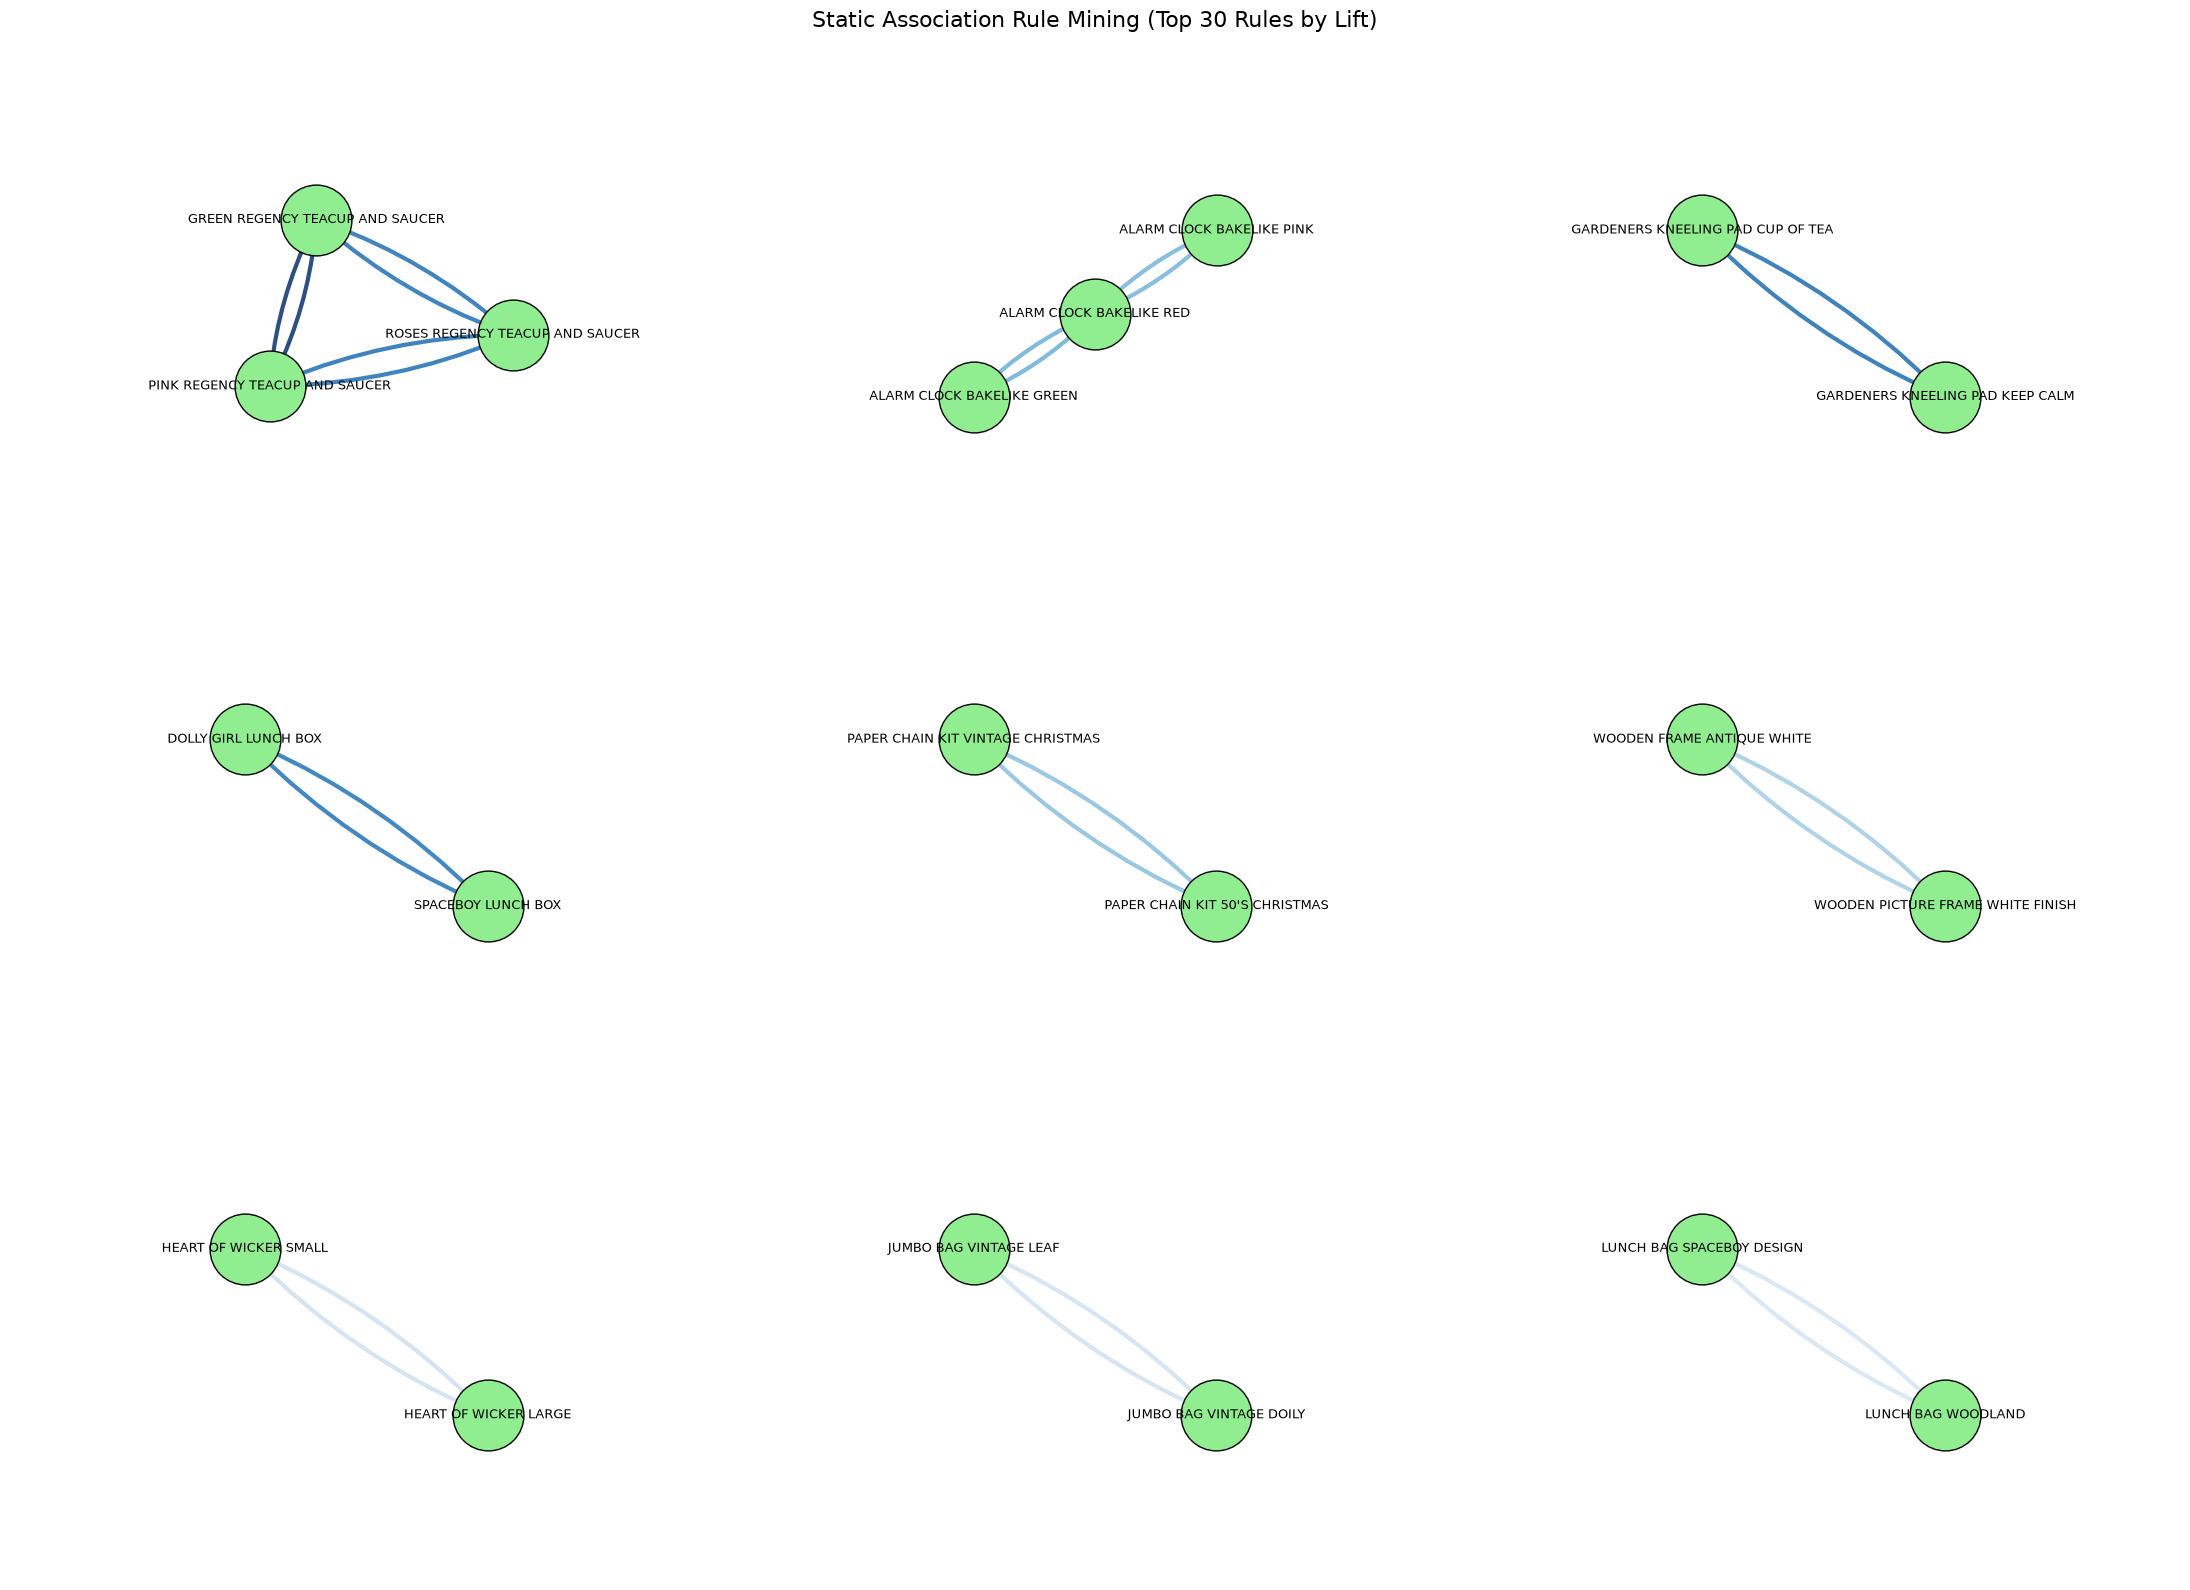

In [117]:
top_n = 30
sub = baseline_rules.head(top_n)

G = nx.DiGraph()
for _, row in sub.iterrows():
    for a in row["antecedents"]:
        for c in row["consequents"]:
            G.add_edge(a, c, weight=row["lift"])

components = list(nx.connected_components(G.to_undirected()))
components.sort(key=len, reverse=True)

pos = {}
ncols = 3
spacing_x, spacing_y = 3.0, 2.6

for i, comp in enumerate(components):
    subg = G.subgraph(comp)
    sub_pos = nx.spring_layout(subg, k=0.9, seed=42, iterations=200)

    xs = np.array([p[0] for p in sub_pos.values()])
    ys = np.array([p[1] for p in sub_pos.values()])
    if np.ptp(xs) > 0: xs = (xs - xs.mean()) / np.ptp(xs)
    if np.ptp(ys) > 0: ys = (ys - ys.mean()) / np.ptp(ys)

    cx = (i % ncols) * spacing_x
    cy = -(i // ncols) * spacing_y

    for node, x, y in zip(sub_pos.keys(), xs, ys):
        pos[node] = (cx + x * 1.0, cy + y * 0.85)

fig, ax = plt.subplots(figsize=(22, 16))

weights = [G[u][v]["weight"] for u, v in G.edges()]
nx.draw_networkx_edges(G, pos, ax=ax, edge_color=weights, edge_cmap=plt.cm.Blues,
                       edge_vmin=min(weights)*0.7, edge_vmax=max(weights),
                       width=3, alpha=0.85, arrowsize=18,
                       connectionstyle="arc3,rad=0.10")
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=2600,
                       node_color="lightgreen", edgecolors="black", linewidths=1.0)
nx.draw_networkx_labels(G, pos, labels={n: item_name(n) for n in G.nodes()}, ax=ax, font_size=9)

ax.set_title("Static Association Rule Mining (Top 30 Rules by Lift)", fontsize=16, pad=20)
ax.axis("off")
ax.margins(0.08)
plt.tight_layout()
plt.show()

---

## **Temporal Unsegmented Association Rule Mining**

In [118]:
# Build baskets for each of the four windows
window_baskets = {}
for label, start, end in windows:
    mask = (df["InvDate"] >= start) & (df["InvDate"] < end)
    df_w = df[mask]
    window_baskets[label] = build_baskets(df_w)
    print(f"{label}: {window_baskets[label].shape[0]:,} invoices, {window_baskets[label].shape[1]:,} unique products")

W1: 3,372 invoices, 2,755 unique products
W2: 3,997 invoices, 2,762 unique products
W3: 3,979 invoices, 2,812 unique products
W4: 6,291 invoices, 3,014 unique products


In [119]:
min_support = 0.02  # same threshold for every rule set (Section III-G)

window_itemsets = {}
for label in window_baskets:
    basket = window_baskets[label]
    itemsets = fpgrowth(basket, min_support=min_support, use_colnames=True)
    window_itemsets[label] = itemsets
    print(f"{label}: {len(itemsets):,} frequent itemsets found (min_support={min_support})")

W1: 278 frequent itemsets found (min_support=0.02)
W2: 305 frequent itemsets found (min_support=0.02)
W3: 459 frequent itemsets found (min_support=0.02)
W4: 385 frequent itemsets found (min_support=0.02)


In [120]:
window_rules = {}
for label in window_itemsets:
    itemsets = window_itemsets[label]
    if len(itemsets) == 0:
        print(f"{label}: no frequent itemsets — skipping rule generation")
        continue
    rules = association_rules(itemsets, metric="lift", min_threshold=1.0)
    rules = rules.sort_values("lift", ascending=False)
    window_rules[label] = rules
    print(f"{label}: {len(rules):,} rules generated (lift ≥ 1.0)")

W1: 72 rules generated (lift ≥ 1.0)
W2: 156 rules generated (lift ≥ 1.0)
W3: 716 rules generated (lift ≥ 1.0)
W4: 174 rules generated (lift ≥ 1.0)


In [121]:
# Window 1
pd.set_option("display.max_colwidth", None)
fmt_rules(window_rules["W1"])

,antecedents,consequents,support,confidence,lift
4,POPPY'S PLAYHOUSE KITCHEN,POPPY'S PLAYHOUSE BEDROOM,0.021,0.735,28.152
5,POPPY'S PLAYHOUSE BEDROOM,POPPY'S PLAYHOUSE KITCHEN,0.021,0.818,28.152
28,CHILDRENS CUTLERY POLKADOT BLUE,CHILDRENS CUTLERY POLKADOT PINK,0.021,0.742,23.392
29,CHILDRENS CUTLERY POLKADOT PINK,CHILDRENS CUTLERY POLKADOT BLUE,0.021,0.673,23.392
62,GREEN REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.029,0.782,19.114
63,ROSES REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.029,0.703,19.114
21,WOOD S/3 CABINET ANT WHITE FINISH,WOOD 2 DRAWER CABINET WHITE FINISH,0.022,0.612,16.367
20,WOOD 2 DRAWER CABINET WHITE FINISH,WOOD S/3 CABINET ANT WHITE FINISH,0.022,0.587,16.367
59,SPACEBOY LUNCH BOX,DOLLY GIRL LUNCH BOX,0.023,0.543,14.882
58,DOLLY GIRL LUNCH BOX,SPACEBOY LUNCH BOX,0.023,0.618,14.882


In [122]:
# Window 2
pd.set_option("display.max_colwidth", None)
fmt_rules(window_rules["W2"])

,antecedents,consequents,support,confidence,lift
21,PINK HAPPY BIRTHDAY BUNTING,BLUE HAPPY BIRTHDAY BUNTING,0.023,0.717,24.067
20,BLUE HAPPY BIRTHDAY BUNTING,PINK HAPPY BIRTHDAY BUNTING,0.023,0.765,24.067
119,"GREEN REGENCY TEACUP AND SAUCER, REGENCY CAKESTAND 3 TIER","PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER",0.023,0.776,19.627
122,"PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER","GREEN REGENCY TEACUP AND SAUCER, REGENCY CAKESTAND 3 TIER",0.023,0.570,19.627
123,"PINK REGENCY TEACUP AND SAUCER, REGENCY CAKESTAND 3 TIER","GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER",0.023,0.826,19.077
118,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER","PINK REGENCY TEACUP AND SAUCER, REGENCY CAKESTAND 3 TIER",0.023,0.520,19.077
114,"GREEN REGENCY TEACUP AND SAUCER, REGENCY CAKESTAND 3 TIER, ROSES REGENCY TEACUP AND SAUCER",PINK REGENCY TEACUP AND SAUCER,0.023,0.865,18.596
127,PINK REGENCY TEACUP AND SAUCER,"GREEN REGENCY TEACUP AND SAUCER, REGENCY CAKESTAND 3 TIER, ROSES REGENCY TEACUP AND SAUCER",0.023,0.484,18.596
72,DOLLY GIRL LUNCH BOX,SPACEBOY LUNCH BOX,0.024,0.707,18.585
73,SPACEBOY LUNCH BOX,DOLLY GIRL LUNCH BOX,0.024,0.618,18.585


In [123]:
# Window 3
pd.set_option("display.max_colwidth", None)
fmt_rules(window_rules["W3"])

,antecedents,consequents,support,confidence,lift
51,PINK REGENCY TEACUP AND SAUCER,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER",0.021,0.686,24.154
46,"GREEN REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER",PINK REGENCY TEACUP AND SAUCER,0.021,0.735,24.154
49,GREEN REGENCY TEACUP AND SAUCER,"PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER",0.021,0.550,23.773
48,"PINK REGENCY TEACUP AND SAUCER, ROSES REGENCY TEACUP AND SAUCER",GREEN REGENCY TEACUP AND SAUCER,0.021,0.902,23.773
43,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.025,0.826,21.778
42,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.025,0.662,21.778
713,SET OF 12 FAIRY CAKE BAKING CASES,SET OF 12 MINI LOAF BAKING CASES,0.022,0.589,20.572
712,SET OF 12 MINI LOAF BAKING CASES,SET OF 12 FAIRY CAKE BAKING CASES,0.022,0.781,20.572
540,SCANDINAVIAN PAISLEY PICNIC BAG,PINK VINTAGE PAISLEY PICNIC BAG,0.022,0.638,20.462
541,PINK VINTAGE PAISLEY PICNIC BAG,SCANDINAVIAN PAISLEY PICNIC BAG,0.022,0.710,20.462


In [124]:
# Window 4
pd.set_option("display.max_colwidth", None)
fmt_rules(window_rules["W4"])

,antecedents,consequents,support,confidence,lift
75,PINK REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.022,0.832,27.272
74,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.022,0.724,27.272
76,ROSES REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.021,0.598,22.534
77,PINK REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.021,0.784,22.534
40,GREEN REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.023,0.750,21.545
41,ROSES REGENCY TEACUP AND SAUCER,GREEN REGENCY TEACUP AND SAUCER,0.023,0.658,21.545
158,SET OF 3 WOODEN TREE DECORATIONS,SET OF 3 WOODEN STOCKING DECORATION,0.025,0.755,21.104
159,SET OF 3 WOODEN STOCKING DECORATION,SET OF 3 WOODEN TREE DECORATIONS,0.025,0.698,21.104
161,SET OF 3 WOODEN SLEIGH DECORATIONS,SET OF 3 WOODEN TREE DECORATIONS,0.022,0.672,20.312
160,SET OF 3 WOODEN TREE DECORATIONS,SET OF 3 WOODEN SLEIGH DECORATIONS,0.022,0.659,20.312


In [125]:
for label in window_rules:
    r = window_rules[label]
    print(f"\n{label}: {len(r)} rules")
    print(f"  Median lift: {r['lift'].median():.2f}")
    print(f"  Median confidence: {r['confidence'].median():.3f}")
    print(f"  Rules with lift > 5: {(r['lift'] > 5).sum()}")


W1: 72 rules
  Median lift: 7.57
  Median confidence: 0.432
  Rules with lift > 5: 48

W2: 156 rules
  Median lift: 7.47
  Median confidence: 0.474
  Rules with lift > 5: 134

W3: 716 rules
  Median lift: 6.59
  Median confidence: 0.429
  Rules with lift > 5: 590

W4: 174 rules
  Median lift: 8.78
  Median confidence: 0.485
  Rules with lift > 5: 162


In [126]:
window_rules_filtered = {}
for label in window_rules:
    r = window_rules[label]
    filtered = r[(r["lift"] >= 2.0) & (r["confidence"] >= 0.3)]
    window_rules_filtered[label] = filtered.sort_values("lift", ascending=False)
    print(f"{label}: {len(filtered):,} rules after filtering (lift ≥ 2.0, confidence ≥ 0.3)")

W1: 55 rules after filtering (lift ≥ 2.0, confidence ≥ 0.3)
W2: 133 rules after filtering (lift ≥ 2.0, confidence ≥ 0.3)
W3: 502 rules after filtering (lift ≥ 2.0, confidence ≥ 0.3)
W4: 161 rules after filtering (lift ≥ 2.0, confidence ≥ 0.3)


---

## **Static ARM vs Temporal ARM (Supplementary)**

In [127]:
rows = [{
    "Scope": "Whole period (static)",
    "Rules": len(baseline_rules),
    "Med_Support": round(baseline_rules["support"].median(), 4),
    "Med_Confidence": round(baseline_rules["confidence"].median(), 3),
    "Med_Lift": round(baseline_rules["lift"].median(), 2),
}]

for label in ["W1", "W2", "W3", "W4"]:
    r = window_rules_filtered[label]
    rows.append({
        "Scope": f"{label} (windowed global)",
        "Rules": len(r),
        "Med_Support": round(r["support"].median(), 4),
        "Med_Confidence": round(r["confidence"].median(), 3),
        "Med_Lift": round(r["lift"].median(), 2),
    })

pd.DataFrame(rows)

,Scope,Rules,Med_Support,Med_Confidence,Med_Lift
0,Whole period (static),88,0.0236,0.457,7.80
1,W1 (windowed global),55,0.0219,0.511,8.59
2,W2 (windowed global),133,0.0240,0.500,8.49
3,W3 (windowed global),502,0.0231,0.507,6.76
4,W4 (windowed global),161,0.0234,0.496,8.84


In [128]:
def rule_key(row):
    return (frozenset(row["antecedents"]), frozenset(row["consequents"]))

In [129]:
baseline_keys = set(baseline_rules.apply(rule_key, axis=1))

print(f"Static baseline rules: {len(baseline_keys):,}\n")
for label in ["W1", "W2", "W3", "W4"]:
    win_keys = set(window_rules_filtered[label].apply(rule_key, axis=1))
    shared = baseline_keys & win_keys
    print(f"{label}: {len(shared):,} shared "
          f"({len(shared)/len(baseline_keys)*100:.1f}% of baseline, "
          f"{len(shared)/len(win_keys)*100:.1f}% of {label})")

# Baseline rules that appear in no window at all
in_any = set().union(*[set(window_rules_filtered[w].apply(rule_key, axis=1)) for w in ["W1","W2","W3","W4"]])
print(f"\nBaseline rules found in no individual window: {len(baseline_keys - in_any):,}")

Static baseline rules: 88

W1: 22 shared (25.0% of baseline, 40.0% of W1)
W2: 61 shared (69.3% of baseline, 45.9% of W2)
W3: 84 shared (95.5% of baseline, 16.7% of W3)
W4: 52 shared (59.1% of baseline, 32.3% of W4)

Baseline rules found in no individual window: 0


---

## **RQ2: Segment-Conditioned Versus Unsegmented Rules (Section IV-C)**

## **Segmented Association Rule Mining**

In [130]:
archetype_order = ["Platinum", "Gold", "Iron", "Lead"]

for label, start, end in windows:
    mask = (df["InvDate"] >= start) & (df["InvDate"] < end)
    df_w = df[mask]
    labels_w = matched_labels[label][f"archetype_{label}"]
    df_w = df_w.merge(labels_w.rename("Archetype"), left_on="CustomerID", right_index=True, how="left")
    
    print(f"\n===== {label} =====")
    for arch in archetype_order:
        sub = df_w[df_w["Archetype"] == arch]
        print(f"  {arch:20s}: {sub['InvoiceNo'].nunique():>5,} invoices, {sub['CustomerID'].nunique():>5,} customers")


===== W1 =====
  Platinum            : 1,135 invoices,   169 customers
  Gold                : 1,030 invoices,   442 customers
  Iron                :   403 invoices,   304 customers
  Lead                :   804 invoices,   766 customers

===== W2 =====
  Platinum            : 1,343 invoices,   194 customers
  Gold                : 1,174 invoices,   502 customers
  Iron                :   510 invoices,   397 customers
  Lead                :   970 invoices,   899 customers

===== W3 =====
  Platinum            : 1,414 invoices,   220 customers
  Gold                : 1,120 invoices,   504 customers
  Iron                :   467 invoices,   318 customers
  Lead                :   978 invoices,   902 customers

===== W4 =====
  Platinum            : 2,479 invoices,   388 customers
  Gold                : 1,819 invoices,   767 customers
  Iron                :   707 invoices,   498 customers
  Lead                : 1,286 invoices, 1,193 customers


In [131]:
# Invoice share and median basket size by archetype (Section IV-B and III-H)
rows = []
for label, start, end in windows:
    mask = (df["InvDate"] >= start) & (df["InvDate"] < end)
    df_w = df[mask].merge(matched_labels[label][f"archetype_{label}"].rename("Archetype"),
                          left_on="CustomerID", right_index=True, how="left")
    n_inv_total = df_w["InvoiceNo"].nunique()
    size_all = df_w.groupby("InvoiceNo")[ITEM_COL].nunique()
    rows.append({"Window": label, "Scope": "Unsegmented", "Invoices": n_inv_total,
                 "Invoice share (%)": 100.0, "Median basket size": size_all.median()})
    for arch in archetype_order:
        sub = df_w[df_w["Archetype"] == arch]
        size = sub.groupby("InvoiceNo")[ITEM_COL].nunique()
        rows.append({"Window": label, "Scope": arch, "Invoices": len(size),
                     "Invoice share (%)": round(len(size) / n_inv_total * 100, 1),
                     "Median basket size": size.median()})

pd.DataFrame(rows)

,Window,Scope,Invoices,Invoice share (%),Median basket size
0,W1,Unsegmented,3372,100.0,14.0
1,W1,Platinum,1135,33.7,14.0
2,W1,Gold,1030,30.5,15.0
3,W1,Iron,403,12.0,15.0
4,W1,Lead,804,23.8,13.5
5,W2,Unsegmented,3997,100.0,15.0
6,W2,Platinum,1343,33.6,12.0
7,W2,Gold,1174,29.4,17.0
8,W2,Iron,510,12.8,13.5
9,W2,Lead,970,24.3,15.0


In [132]:
cluster_rules = {}
cluster_itemsets = {}
segment_n_baskets = {}

for label, start, end in windows:
    mask = (df["InvDate"] >= start) & (df["InvDate"] < end)
    df_w = df[mask]
    labels_w = matched_labels[label][f"archetype_{label}"]
    df_w = df_w.merge(labels_w.rename("Archetype"), left_on="CustomerID", right_index=True, how="left")

    for arch in archetype_order:
        sub = df_w[df_w["Archetype"] == arch]
        n_inv = sub["InvoiceNo"].nunique()
        key = (label, arch)
        segment_n_baskets[key] = n_inv

        # Safeguard against unstable rules from very small segments (not triggered in this data)
        if n_inv < 100:
            print(f"{label} / {arch}: only {n_inv} invoices — skipped (too few for stable rules)")
            cluster_rules[key] = None
            cluster_itemsets[key] = 0
            continue

        basket = build_baskets(sub)
        itemsets = fpgrowth(basket, min_support=0.02, use_colnames=True)
        cluster_itemsets[key] = len(itemsets)

        if len(itemsets) == 0:
            print(f"{label} / {arch}: no frequent itemsets at min_support=0.02")
            cluster_rules[key] = None
            continue

        rules = association_rules(itemsets, metric="lift", min_threshold=1.0)
        rules = rules[(rules["lift"] >= 2.0) & (rules["confidence"] >= 0.3)]
        cluster_rules[key] = rules.sort_values("lift", ascending=False)
        print(f"{label} / {arch}: {len(itemsets):,} itemsets, {len(rules):,} rules (from {n_inv:,} invoices)")

W1 / Platinum: 279 itemsets, 109 rules (from 1,135 invoices)
W1 / Gold: 397 itemsets, 191 rules (from 1,030 invoices)
W1 / Iron: 362 itemsets, 174 rules (from 403 invoices)
W1 / Lead: 220 itemsets, 32 rules (from 804 invoices)
W2 / Platinum: 308 itemsets, 210 rules (from 1,343 invoices)
W2 / Gold: 484 itemsets, 404 rules (from 1,174 invoices)
W2 / Iron: 296 itemsets, 223 rules (from 510 invoices)
W2 / Lead: 289 itemsets, 88 rules (from 970 invoices)
W3 / Platinum: 570 itemsets, 819 rules (from 1,414 invoices)
W3 / Gold: 939 itemsets, 1,844 rules (from 1,120 invoices)
W3 / Iron: 353 itemsets, 378 rules (from 467 invoices)
W3 / Lead: 239 itemsets, 81 rules (from 978 invoices)
W4 / Platinum: 440 itemsets, 232 rules (from 2,479 invoices)
W4 / Gold: 538 itemsets, 328 rules (from 1,819 invoices)
W4 / Iron: 302 itemsets, 73 rules (from 707 invoices)
W4 / Lead: 291 itemsets, 100 rules (from 1,286 invoices)


In [133]:
comparison = []

for label, start, end in windows:
    g = window_rules_filtered[label]
    comparison.append({
        "Window": label,
        "Scope": "Global (unsegmented)",
        "Rules": len(g),
        "Med_Support": round(g["support"].median(), 4),
        "Med_Confidence": round(g["confidence"].median(), 3),
        "Med_Lift": round(g["lift"].median(), 2),
    })
    for arch in archetype_order:
        r = cluster_rules[(label, arch)]
        if r is None or len(r) == 0:
            continue
        comparison.append({
            "Window": label,
            "Scope": arch,
            "Rules": len(r),
            "Med_Support": round(r["support"].median(), 4),
            "Med_Confidence": round(r["confidence"].median(), 3),
            "Med_Lift": round(r["lift"].median(), 2),
        })

comparison_df = pd.DataFrame(comparison)
comparison_df

,Window,Scope,Rules,Med_Support,Med_Confidence,Med_Lift
0,W1,Global (unsegmented),55,0.0219,0.511,8.59
1,W1,Platinum,109,0.0220,0.511,9.52
2,W1,Gold,191,0.0243,0.525,9.81
3,W1,Iron,174,0.0273,0.588,10.95
4,W1,Lead,32,0.0255,0.458,6.85
5,W2,Global (unsegmented),133,0.0240,0.500,8.49
6,W2,Platinum,210,0.0231,0.485,8.79
7,W2,Gold,404,0.0247,0.522,8.57
8,W2,Iron,223,0.0235,0.520,9.39
9,W2,Lead,88,0.0227,0.662,14.95


In [134]:
# Table VI: baskets, frequent itemsets, and retained rules by window and scope
rows = []
for label, start, end in windows:
    rows.append({"Window": label, "Scope": "Unsegmented",
                 "Baskets": len(window_baskets[label]),
                 "Itemsets": len(window_itemsets[label]),
                 "Rules": len(window_rules_filtered[label])})
    for arch in archetype_order:
        r = cluster_rules[(label, arch)]
        rows.append({"Window": label, "Scope": arch,
                     "Baskets": segment_n_baskets[(label, arch)],
                     "Itemsets": cluster_itemsets[(label, arch)],
                     "Rules": 0 if r is None else len(r)})

table6_df = pd.DataFrame(rows)
table6_df

,Window,Scope,Baskets,Itemsets,Rules
0,W1,Unsegmented,3372,278,55
1,W1,Platinum,1135,279,109
2,W1,Gold,1030,397,191
3,W1,Iron,403,362,174
4,W1,Lead,804,220,32
5,W2,Unsegmented,3997,305,133
6,W2,Platinum,1343,308,210
7,W2,Gold,1174,484,404
8,W2,Iron,510,296,223
9,W2,Lead,970,289,88


---

## **RQ3: Temporal Evolution of Segment-Conditioned Rules (Section IV-D)**

Rules are identified by their exact antecedent and consequent. Tables VIII and IX are produced below.

In [135]:
# Build the set of rule keys present in each (window, archetype)
rule_sets = {}
for label in ["W1", "W2", "W3", "W4"]:
    for arch in archetype_order:
        r = cluster_rules[(label, arch)]
        if r is None or len(r) == 0:
            rule_sets[(label, arch)] = set()
        else:
            rule_sets[(label, arch)] = set(r.apply(rule_key, axis=1))
        print(f"{label} / {arch}: {len(rule_sets[(label, arch)]):,} unique rules")

W1 / Platinum: 109 unique rules
W1 / Gold: 191 unique rules
W1 / Iron: 174 unique rules
W1 / Lead: 32 unique rules
W2 / Platinum: 210 unique rules
W2 / Gold: 404 unique rules
W2 / Iron: 223 unique rules
W2 / Lead: 88 unique rules
W3 / Platinum: 819 unique rules
W3 / Gold: 1,844 unique rules
W3 / Iron: 378 unique rules
W3 / Lead: 81 unique rules
W4 / Platinum: 232 unique rules
W4 / Gold: 328 unique rules
W4 / Iron: 73 unique rules
W4 / Lead: 100 unique rules


In [136]:
print("\nRule dynamics within each archetype:\n")
for arch in archetype_order:
    print(f"===== {arch} =====")
    for a, b in zip(["W1","W2","W3"], ["W2","W3","W4"]):
        prev, curr = rule_sets[(a, arch)], rule_sets[(b, arch)]
        persist = prev & curr
        emerge = curr - prev
        disappear = prev - curr
        pct = (len(persist) / len(prev) * 100) if len(prev) else 0
        print(f"  {a}→{b}: persisted {len(persist):,} ({pct:.1f}% of {a}), emerged {len(emerge):,}, disappeared {len(disappear):,}")
    print()


Rule dynamics within each archetype:

===== Platinum =====
  W1→W2: persisted 11 (10.1% of W1), emerged 199, disappeared 98
  W2→W3: persisted 119 (56.7% of W2), emerged 700, disappeared 91
  W3→W4: persisted 113 (13.8% of W3), emerged 119, disappeared 706

===== Gold =====
  W1→W2: persisted 73 (38.2% of W1), emerged 331, disappeared 118
  W2→W3: persisted 259 (64.1% of W2), emerged 1,585, disappeared 145
  W3→W4: persisted 132 (7.2% of W3), emerged 196, disappeared 1,712

===== Iron =====
  W1→W2: persisted 49 (28.2% of W1), emerged 174, disappeared 125
  W2→W3: persisted 79 (35.4% of W2), emerged 299, disappeared 144
  W3→W4: persisted 10 (2.6% of W3), emerged 63, disappeared 368

===== Lead =====
  W1→W2: persisted 4 (12.5% of W1), emerged 84, disappeared 28
  W2→W3: persisted 9 (10.2% of W2), emerged 72, disappeared 79
  W3→W4: persisted 12 (14.8% of W3), emerged 88, disappeared 69



In [137]:
print("Rule dynamics with symmetric measures:\n")
for arch in archetype_order:
    print(f"===== {arch} =====")
    for a, b in zip(["W1","W2","W3"], ["W2","W3","W4"]):
        prev, curr = rule_sets[(a, arch)], rule_sets[(b, arch)]
        persist = prev & curr
        union = prev | curr
        pct_prev = (len(persist) / len(prev) * 100) if len(prev) else 0
        pct_curr = (len(persist) / len(curr) * 100) if len(curr) else 0
        jaccard = (len(persist) / len(union)) if len(union) else 0
        print(f"  {a}→{b}: persisted {len(persist):,} = {pct_prev:.1f}% of {a} ({len(prev):,}), "
              f"{pct_curr:.1f}% of {b} ({len(curr):,}), Jaccard={jaccard:.3f}")
    print()

Rule dynamics with symmetric measures:

===== Platinum =====
  W1→W2: persisted 11 = 10.1% of W1 (109), 5.2% of W2 (210), Jaccard=0.036
  W2→W3: persisted 119 = 56.7% of W2 (210), 14.5% of W3 (819), Jaccard=0.131
  W3→W4: persisted 113 = 13.8% of W3 (819), 48.7% of W4 (232), Jaccard=0.120

===== Gold =====
  W1→W2: persisted 73 = 38.2% of W1 (191), 18.1% of W2 (404), Jaccard=0.140
  W2→W3: persisted 259 = 64.1% of W2 (404), 14.0% of W3 (1,844), Jaccard=0.130
  W3→W4: persisted 132 = 7.2% of W3 (1,844), 40.2% of W4 (328), Jaccard=0.065

===== Iron =====
  W1→W2: persisted 49 = 28.2% of W1 (174), 22.0% of W2 (223), Jaccard=0.141
  W2→W3: persisted 79 = 35.4% of W2 (223), 20.9% of W3 (378), Jaccard=0.151
  W3→W4: persisted 10 = 2.6% of W3 (378), 13.7% of W4 (73), Jaccard=0.023

===== Lead =====
  W1→W2: persisted 4 = 12.5% of W1 (32), 4.5% of W2 (88), Jaccard=0.034
  W2→W3: persisted 9 = 10.2% of W2 (88), 11.1% of W3 (81), Jaccard=0.056
  W3→W4: persisted 12 = 14.8% of W3 (81), 12.0% of W

In [138]:
print("Lift of persistent vs transient rules:\n")
for arch in archetype_order:
    for a, b in zip(["W1","W2","W3"], ["W2","W3","W4"]):
        r_prev = cluster_rules[(a, arch)]
        if r_prev is None or len(r_prev) == 0:
            continue
        keys = r_prev.apply(rule_key, axis=1)
        persisted_mask = keys.isin(rule_sets[(b, arch)])
        if persisted_mask.sum() == 0 or (~persisted_mask).sum() == 0:
            continue
        lp = r_prev.loc[persisted_mask, "lift"].median()
        lt = r_prev.loc[~persisted_mask, "lift"].median()
        print(f"{arch:18s} {a}→{b}: persisted lift={lp:.2f}, disappeared lift={lt:.2f}")
    print()

Lift of persistent vs transient rules:

Platinum           W1→W2: persisted lift=11.04, disappeared lift=9.52
Platinum           W2→W3: persisted lift=7.63, disappeared lift=9.86
Platinum           W3→W4: persisted lift=5.06, disappeared lift=6.28

Gold               W1→W2: persisted lift=9.18, disappeared lift=10.74
Gold               W2→W3: persisted lift=8.18, disappeared lift=9.93
Gold               W3→W4: persisted lift=5.32, disappeared lift=6.76

Iron               W1→W2: persisted lift=12.34, disappeared lift=7.20
Iron               W2→W3: persisted lift=7.32, disappeared lift=12.50
Iron               W3→W4: persisted lift=16.68, disappeared lift=10.06

Lead               W1→W2: persisted lift=8.51, disappeared lift=6.85
Lead               W2→W3: persisted lift=10.70, disappeared lift=19.54
Lead               W3→W4: persisted lift=9.82, disappeared lift=8.61



In [139]:
print("Rules appearing in each number of windows (per archetype):\n")
for arch in archetype_order:
    all_rules = set().union(*[rule_sets[(w, arch)] for w in ["W1","W2","W3","W4"]])
    counts = {1: 0, 2: 0, 3: 0, 4: 0}
    for r in all_rules:
        n = sum(1 for w in ["W1","W2","W3","W4"] if r in rule_sets[(w, arch)])
        counts[n] += 1
    total = len(all_rules)
    print(f"{arch}: {total:,} distinct rules across all windows")
    for n in [1, 2, 3, 4]:
        print(f"  in {n} window(s): {counts[n]:,} ({counts[n]/total*100:.1f}%)")
    print()

Rules appearing in each number of windows (per archetype):

Platinum: 1,111 distinct rules across all windows
  in 1 window(s): 912 (82.1%)
  in 2 window(s): 146 (13.1%)
  in 3 window(s): 46 (4.1%)
  in 4 window(s): 7 (0.6%)

Gold: 2,257 distinct rules across all windows
  in 1 window(s): 1,865 (82.6%)
  in 2 window(s): 304 (13.5%)
  in 3 window(s): 58 (2.6%)
  in 4 window(s): 30 (1.3%)

Iron: 699 distinct rules across all windows
  in 1 window(s): 553 (79.1%)
  in 2 window(s): 143 (20.5%)
  in 3 window(s): 3 (0.4%)
  in 4 window(s): 0 (0.0%)

Lead: 263 distinct rules across all windows
  in 1 window(s): 228 (86.7%)
  in 2 window(s): 32 (12.2%)
  in 3 window(s): 3 (1.1%)
  in 4 window(s): 0 (0.0%)



In [140]:
print("Rules present in all four windows:\n")
for arch in ["Platinum", "Gold", "Iron", "Lead"]:
    all_four = set.intersection(*[rule_sets[(w, arch)] for w in ["W1","W2","W3","W4"]])
    print(f"===== {arch}: {len(all_four)} rules =====")
    for r in sorted(all_four, key=lambda r: (sorted(r[0]), sorted(r[1]))):
        ant = ", ".join(sorted(item_name(x) for x in r[0]))
        con = ", ".join(sorted(item_name(x) for x in r[1]))
        print(f"  {ant}  →  {con}")
    print()

Rules present in all four windows:

===== Platinum: 7 rules =====
  JUMBO STORAGE BAG SUKI  →  JUMBO BAG RED RETROSPOT
  JUMBO BAG PINK POLKADOT  →  JUMBO BAG RED RETROSPOT
  SPACEBOY LUNCH BOX  →  DOLLY GIRL LUNCH BOX
  DOLLY GIRL LUNCH BOX  →  SPACEBOY LUNCH BOX
  GREEN REGENCY TEACUP AND SAUCER  →  ROSES REGENCY TEACUP AND SAUCER
  ROSES REGENCY TEACUP AND SAUCER  →  GREEN REGENCY TEACUP AND SAUCER
  JUMBO BAG STRAWBERRY  →  JUMBO BAG RED RETROSPOT

===== Gold: 30 rules =====
  LUNCH BAG RED RETROSPOT  →  LUNCH BAG WOODLAND
  LUNCH BAG RED RETROSPOT  →  LUNCH BAG  BLACK SKULL.
  LUNCH BAG RED RETROSPOT  →  LUNCH BAG SPACEBOY DESIGN
  LUNCH BAG RED RETROSPOT  →  LUNCH BAG SUKI DESIGN
  LUNCH BAG RED RETROSPOT  →  LUNCH BAG PINK POLKADOT
  LUNCH BAG WOODLAND  →  LUNCH BAG RED RETROSPOT
  LUNCH BAG WOODLAND  →  LUNCH BAG  BLACK SKULL.
  LUNCH BAG WOODLAND  →  LUNCH BAG SPACEBOY DESIGN
  LUNCH BAG  BLACK SKULL.  →  LUNCH BAG RED RETROSPOT
  LUNCH BAG  BLACK SKULL.  →  LUNCH BAG WOODLAND

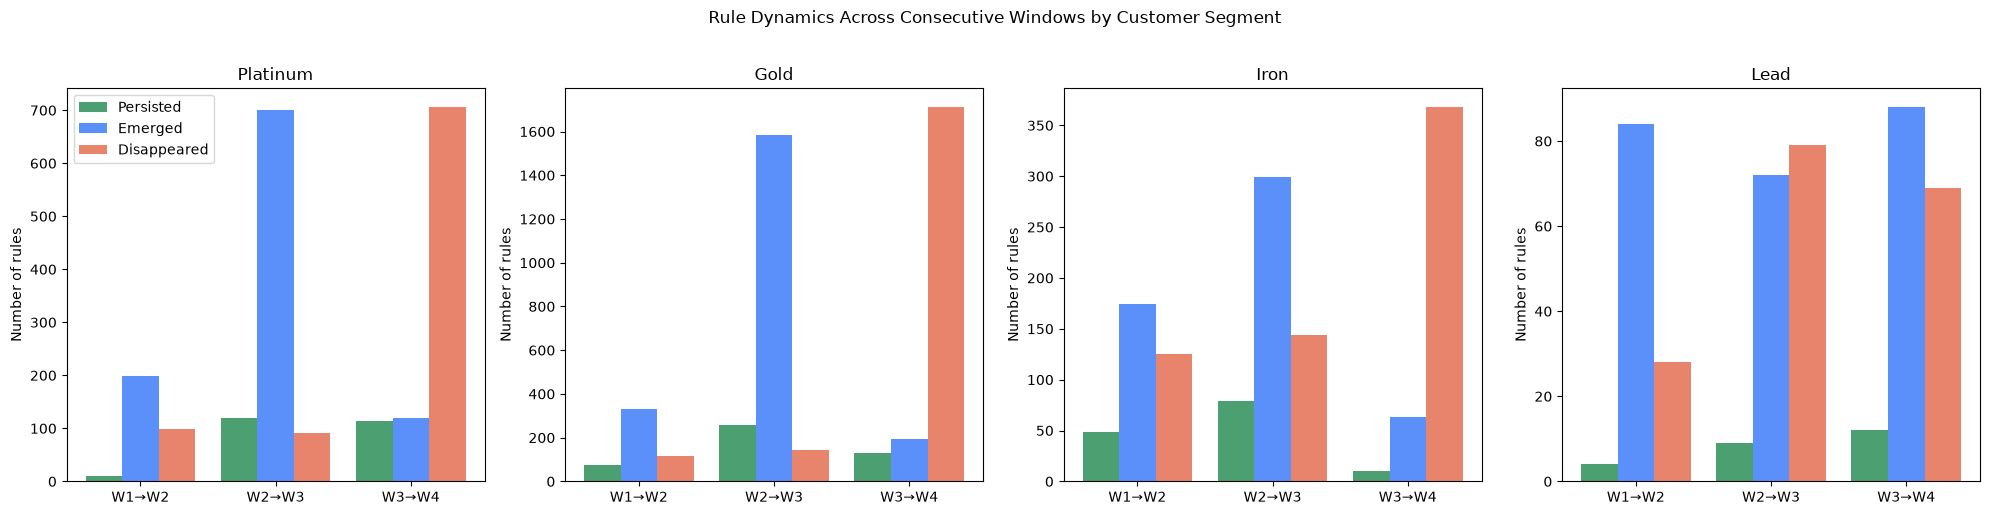

In [141]:
transitions = [("W1","W2"), ("W2","W3"), ("W3","W4")]
fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=False)

for ax, arch in zip(axes, archetype_order):
    persisted, emerged, disappeared = [], [], []
    for a, b in transitions:
        prev, curr = rule_sets[(a, arch)], rule_sets[(b, arch)]
        persisted.append(len(prev & curr))
        emerged.append(len(curr - prev))
        disappeared.append(len(prev - curr))

    x = np.arange(len(transitions))
    width = 0.27
    ax.bar(x - width, persisted, width, label="Persisted", color="#4C9F70")
    ax.bar(x, emerged, width, label="Emerged", color="#5B8FF9")
    ax.bar(x + width, disappeared, width, label="Disappeared", color="#E8846B")

    ax.set_title(arch)
    ax.set_xticks(x)
    ax.set_xticklabels([f"{a}→{b}" for a, b in transitions])
    ax.set_ylabel("Number of rules")

axes[0].legend()
plt.suptitle("Rule Dynamics Across Consecutive Windows by Customer Segment", y=1.02)
plt.tight_layout()
plt.show()

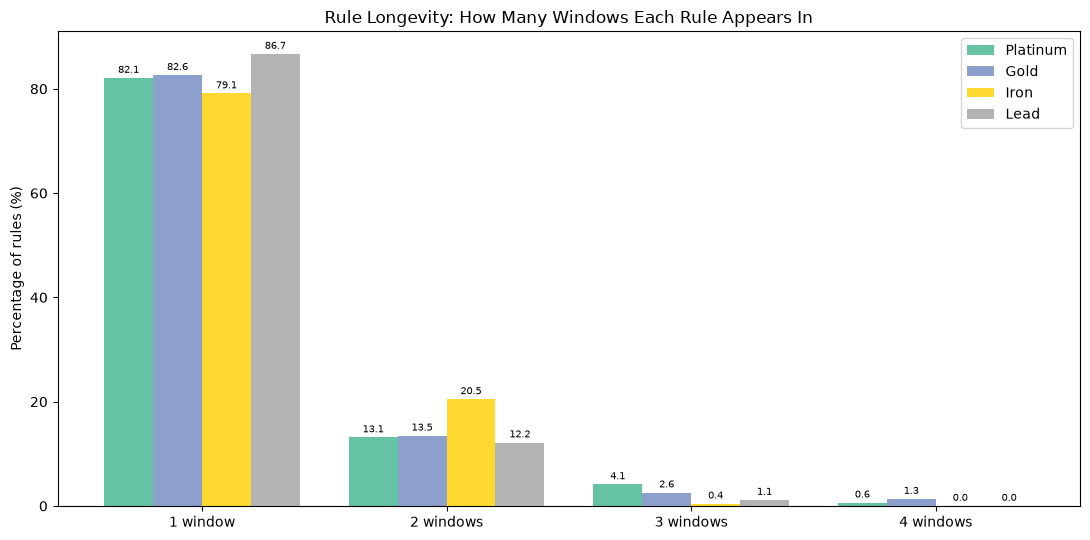

In [142]:
fig, ax = plt.subplots(figsize=(11, 5.5))

x = np.arange(4)
width = 0.2
colors = plt.cm.Set2(np.linspace(0, 1, 4))

for i, arch in enumerate(archetype_order):
    all_rules = set().union(*[rule_sets[(w, arch)] for w in ["W1","W2","W3","W4"]])
    counts = []
    for n in [1, 2, 3, 4]:
        c = sum(1 for r in all_rules
                if sum(1 for w in ["W1","W2","W3","W4"] if r in rule_sets[(w, arch)]) == n)
        counts.append(c / len(all_rules) * 100)
    bars = ax.bar(x + (i - 1.5) * width, counts, width, label=arch, color=colors[i])
    ax.bar_label(bars, fmt="%.1f", fontsize=7, padding=2)

ax.set_xticks(x)
ax.set_xticklabels(["1 window", "2 windows", "3 windows", "4 windows"])
ax.set_ylabel("Percentage of rules (%)")
ax.set_title("Rule Longevity: How Many Windows Each Rule Appears In")
ax.legend()
plt.tight_layout()
plt.show()

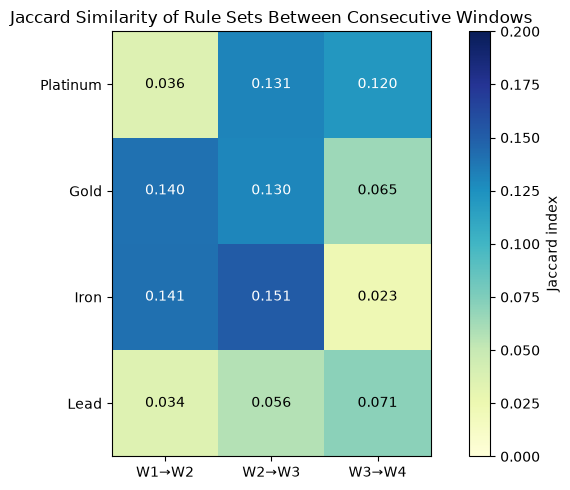

In [143]:
fig, ax = plt.subplots(figsize=(8, 5))

matrix = []
for arch in archetype_order:
    row = []
    for a, b in transitions:
        prev, curr = rule_sets[(a, arch)], rule_sets[(b, arch)]
        union = prev | curr
        row.append(len(prev & curr) / len(union) if union else 0)
    matrix.append(row)

matrix = np.array(matrix)
im = ax.imshow(matrix, cmap="YlGnBu", vmin=0, vmax=0.2)

ax.set_xticks(range(len(transitions)))
ax.set_xticklabels([f"{a}→{b}" for a, b in transitions])
ax.set_yticks(range(len(archetype_order)))
ax.set_yticklabels(archetype_order)

for i in range(len(archetype_order)):
    for j in range(len(transitions)):
        ax.text(j, i, f"{matrix[i, j]:.3f}", ha="center", va="center",
                color="white" if matrix[i, j] > 0.1 else "black")

ax.set_title("Jaccard Similarity of Rule Sets Between Consecutive Windows")
plt.colorbar(im, ax=ax, label="Jaccard index")
plt.tight_layout()
plt.show()

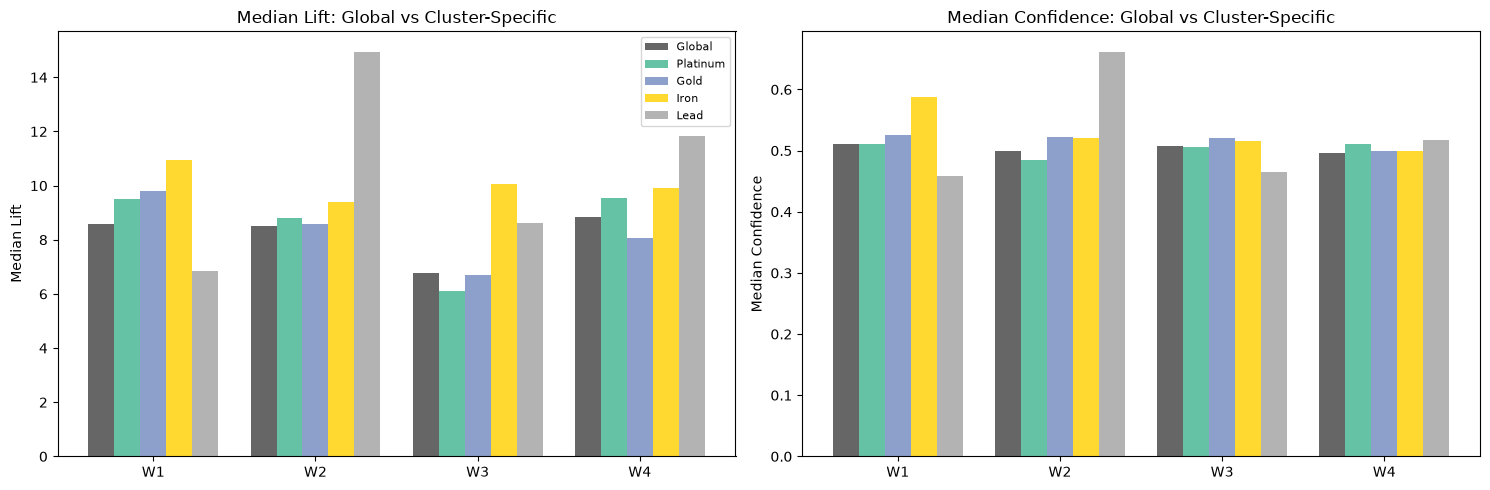

In [144]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

windows_list = ["W1", "W2", "W3", "W4"]
x = np.arange(len(windows_list))
width = 0.16

for metric, ax in zip(["Med_Lift", "Med_Confidence"], axes):
    glob_vals = [comparison_df[(comparison_df["Window"] == w) &
                 (comparison_df["Scope"] == "Global (unsegmented)")][metric].iloc[0]
                 for w in windows_list]
    ax.bar(x - 2*width, glob_vals, width, label="Global", color="#666666")

    for i, arch in enumerate(archetype_order):
        vals = []
        for w in windows_list:
            sub = comparison_df[(comparison_df["Window"] == w) & (comparison_df["Scope"] == arch)]
            vals.append(sub[metric].iloc[0] if len(sub) else 0)
        ax.bar(x + (i - 1)*width, vals, width, label=arch, color=colors[i])

    ax.set_xticks(x)
    ax.set_xticklabels(windows_list)
    ax.set_ylabel(metric.replace("Med_", "Median "))
    ax.set_title(f"{metric.replace('Med_', 'Median ')}: Global vs Cluster-Specific")

axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

---

### **Mann-Whitney U Tests (Table VII)**

Two-sided tests comparing each segment-conditioned rule set with the unsegmented rule set of the same window, after mirrored rule pairs are reduced to one. The effect size is the rank-biserial correlation (positive when segment-conditioned values are higher). p-values are Holm-adjusted across the four archetypes within each window and metric.

In [145]:
def dedupe(rules):
    key = rules.apply(lambda r: frozenset([frozenset(r["antecedents"]),
                                           frozenset(r["consequents"])]), axis=1)
    return rules.loc[~key.duplicated()]

rows = []
for w in ["W1", "W2", "W3", "W4"]:
    base = dedupe(window_rules_filtered[w])
    for arch in archetype_order:
        seg = cluster_rules[(w, arch)]
        if seg is None or len(seg) == 0:
            continue
        seg = dedupe(seg)
        for metric in ["support", "confidence", "lift"]:
            a, b = seg[metric], base[metric]
            u, p = mannwhitneyu(a, b, alternative="two-sided")
            rows.append({"Window": w, "Archetype": arch, "Metric": metric,
                         "n_seg": len(a), "n_unseg": len(b),
                         "Median seg": round(a.median(), 4),
                         "Median unseg": round(b.median(), 4),
                         "r": round(2 * u / (len(a) * len(b)) - 1, 3),
                         "p": p})

mw = pd.DataFrame(rows)
mw["p (Holm)"] = mw.groupby(["Window", "Metric"])["p"].transform(
    lambda s: multipletests(s, method="holm")[1])
mw["p"] = mw["p"].round(4)
mw["p (Holm)"] = mw["p (Holm)"].round(4)
print(mw.to_string(index=False))

Window Archetype     Metric  n_seg  n_unseg  Median seg  Median unseg      r      p  p (Holm)
    W1  Platinum    support     66       35      0.0220        0.0219  0.061 0.6140    0.6140
    W1  Platinum confidence     66       35      0.5000        0.5145 -0.090 0.4623    0.9245
    W1  Platinum       lift     66       35      8.6994        7.7373  0.113 0.3554    0.8457
    W1      Gold    support    109       35      0.0243        0.0219  0.219 0.0508    0.1016
    W1      Gold confidence    109       35      0.5238        0.5145 -0.026 0.8213    0.9245
    W1      Gold       lift    109       35      9.1800        7.7373  0.163 0.1475    0.5899
    W1      Iron    support    110       35      0.0261        0.0219  0.420 0.0002    0.0006
    W1      Iron confidence    110       35      0.5789        0.5145  0.156 0.1663    0.6653
    W1      Iron       lift    110       35      6.6752        7.7373  0.062 0.5840    0.8457
    W1      Lead    support     20       35      0.0255     

### **Size-Matched Null Model**

A segment-conditioned rule set is mined from fewer baskets than the unsegmented rule set of the same window, and smaller samples can raise lift through estimation noise alone. For each archetype in each window, the null model draws the same number of baskets at random (without replacement) from all baskets of that window, mines them with the same thresholds, and records the median lift after mirrored pairs are reduced to one. Repeating this `N_NULL` times gives the distribution of median lift expected from sample size alone.

The observed median lift is compared with this distribution using a z-score and an empirical two-sided p-value, Holm-adjusted across the four archetypes within each window. Runtime grows with `N_NULL`; reduce it for a quick check.

In [146]:
N_NULL = 200
rng = np.random.default_rng(42)


def median_lift_of(basket):
    basket = basket.loc[:, basket.any()]
    itemsets = fpgrowth(basket, min_support=0.02, use_colnames=True)
    if len(itemsets) == 0:
        return np.nan
    rules = association_rules(itemsets, metric="lift", min_threshold=1.0)
    rules = rules[(rules["lift"] >= 2.0) & (rules["confidence"] >= 0.3)]
    if len(rules) == 0:
        return np.nan
    return dedupe(rules)["lift"].median()


null_rows = []
null_dists = {}
for label in ["W1", "W2", "W3", "W4"]:
    pool = window_baskets[label]
    for arch in archetype_order:
        key = (label, arch)
        seg = cluster_rules[key]
        if seg is None or len(seg) == 0:
            continue
        n = segment_n_baskets[key]
        observed = dedupe(seg)["lift"].median()

        null = np.array([median_lift_of(pool.sample(n=n, random_state=int(rng.integers(2**32 - 1))))
                         for _ in range(N_NULL)])
        no_rules = int(np.isnan(null).sum())
        null = null[~np.isnan(null)]
        null_dists[key] = null

        mu, sd = null.mean(), null.std(ddof=1)
        p = (1 + np.sum(np.abs(null - mu) >= abs(observed - mu))) / (len(null) + 1)
        null_rows.append({"Window": label, "Archetype": arch, "Baskets": n,
                          "Observed median lift": round(observed, 2),
                          "Null mean": round(mu, 2), "Null SD": round(sd, 2),
                          "z": round((observed - mu) / sd, 2), "p": p,
                          "Replicates without rules": no_rules})
        print(f"{label} / {arch}: done")

null_df = pd.DataFrame(null_rows)
null_df["p (Holm)"] = null_df.groupby("Window")["p"].transform(lambda s: multipletests(s, method="holm")[1])
null_df["p"] = null_df["p"].round(4)
null_df["p (Holm)"] = null_df["p (Holm)"].round(4)
null_df

W1 / Platinum: done
W1 / Gold: done
W1 / Iron: done
W1 / Lead: done
W2 / Platinum: done
W2 / Gold: done
W2 / Iron: done
W2 / Lead: done
W3 / Platinum: done
W3 / Gold: done
W3 / Iron: done
W3 / Lead: done
W4 / Platinum: done
W4 / Gold: done
W4 / Iron: done
W4 / Lead: done


,Window,Archetype,Baskets,Observed median lift,Null mean,Null SD,z,p,Replicates without rules,p (Holm)
0,W1,Platinum,1135,8.70,8.53,1.07,0.16,0.7861,0,1.0000
1,W1,Gold,1030,9.18,8.65,1.12,0.47,0.5423,0,1.0000
2,W1,Iron,403,6.68,9.97,2.55,-1.29,0.0995,0,0.2985
3,W1,Lead,804,6.18,8.77,1.31,-1.97,0.0597,0,0.2388
4,W2,Platinum,1343,8.26,10.79,7.57,-0.33,0.4080,0,1.0000
5,W2,Gold,1174,8.22,11.02,7.45,-0.38,0.4428,0,1.0000
6,W2,Iron,510,8.69,13.47,8.91,-0.54,0.3682,0,1.0000
7,W2,Lead,970,13.02,11.57,7.91,0.18,0.9055,0,1.0000
8,W3,Platinum,1414,5.97,6.87,0.46,-1.96,0.0398,0,0.1194
9,W3,Gold,1120,6.37,7.04,0.58,-1.15,0.2388,0,0.2388


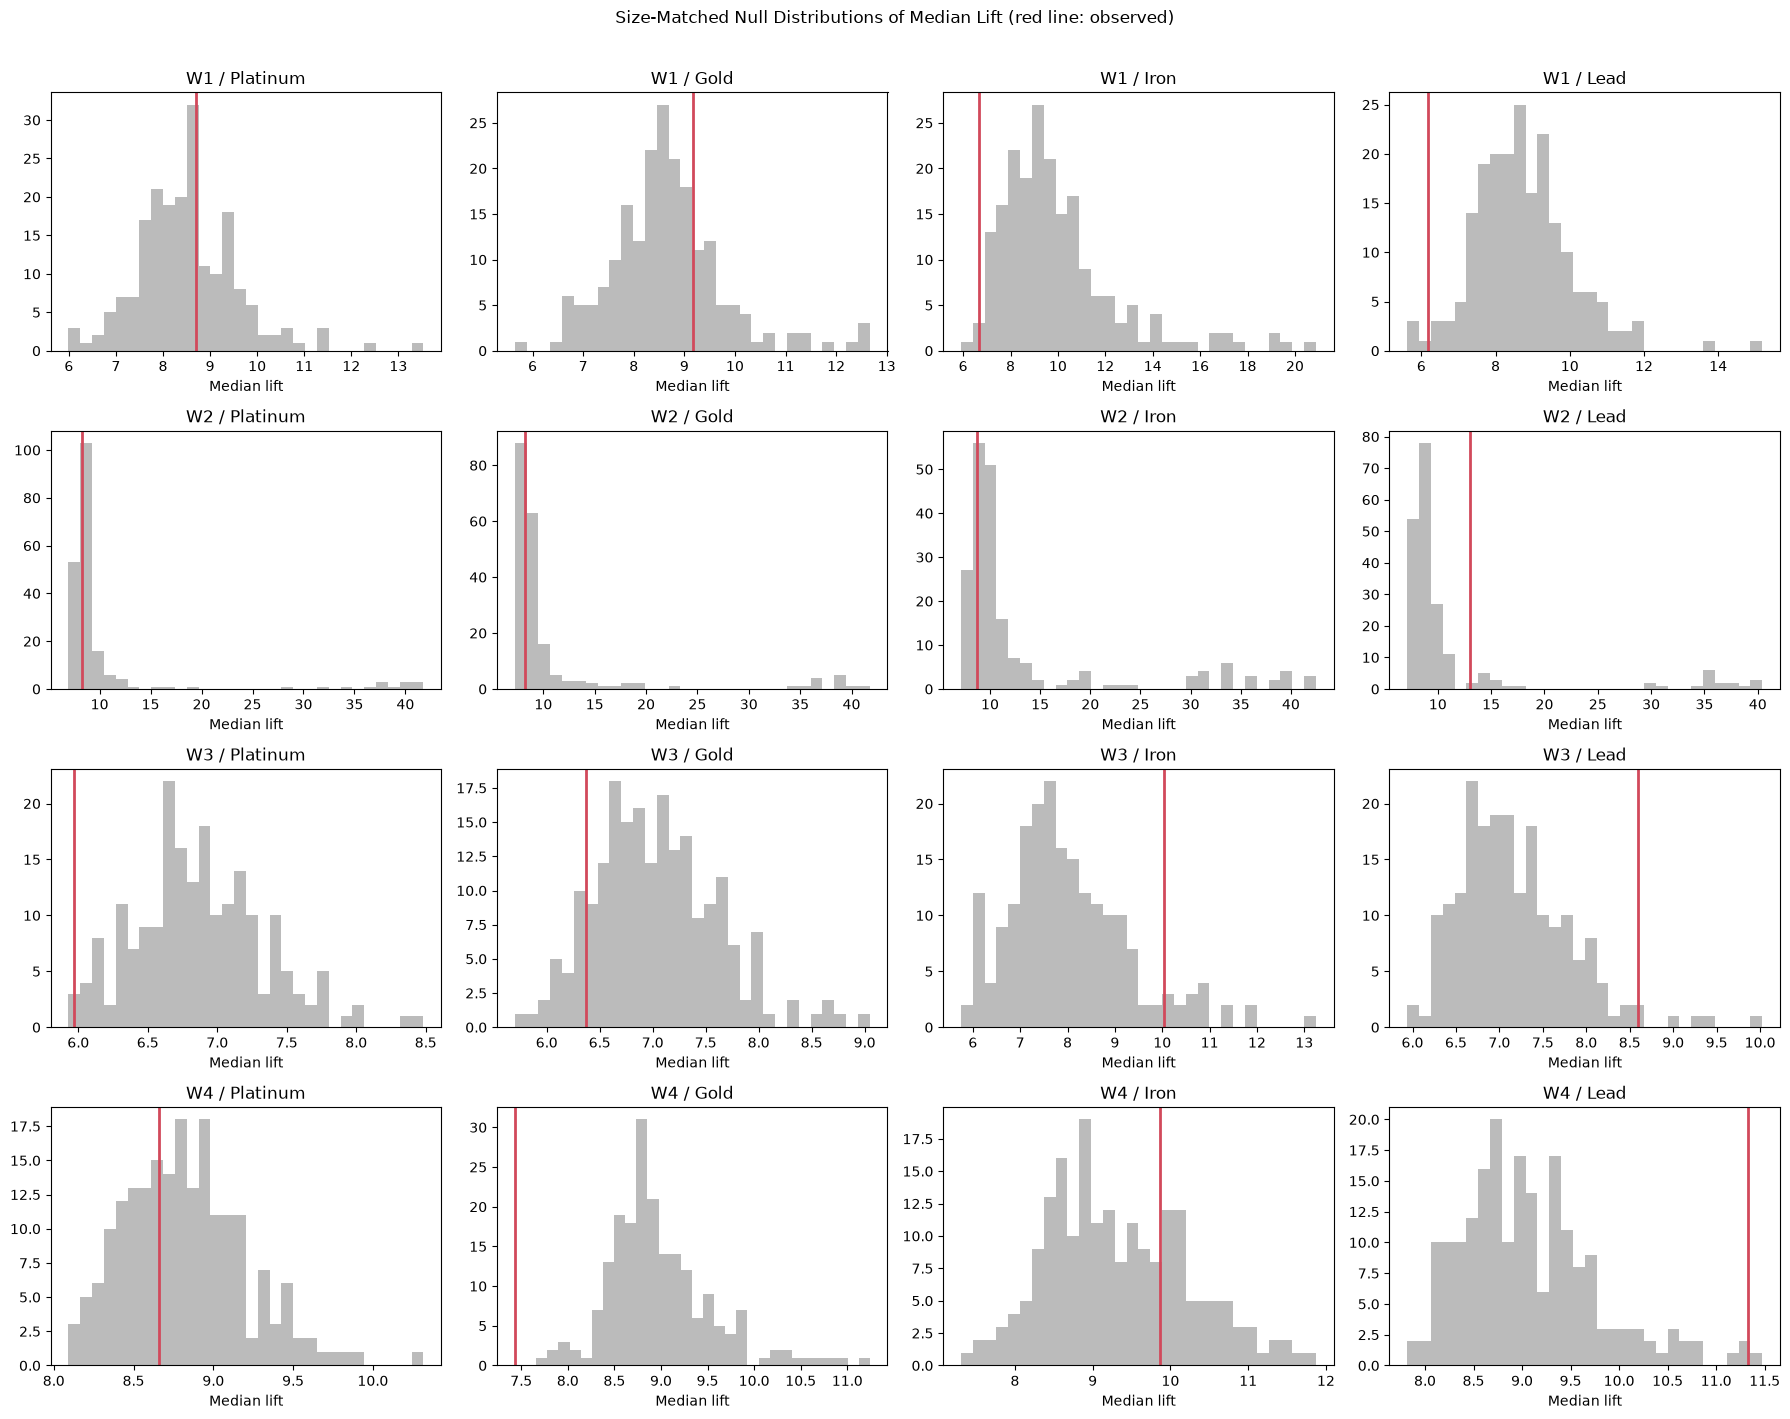

In [147]:
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for i, label in enumerate(["W1", "W2", "W3", "W4"]):
    for j, arch in enumerate(archetype_order):
        ax = axes[i, j]
        key = (label, arch)
        if key not in null_dists:
            ax.axis("off")
            continue
        ax.hist(null_dists[key], bins=30, color="#BBBBBB")
        observed = null_df[(null_df["Window"] == label) & (null_df["Archetype"] == arch)]["Observed median lift"].iloc[0]
        ax.axvline(observed, color="#D1495B", linewidth=2)
        ax.set_title(f"{label} / {arch}")
        ax.set_xlabel("Median lift")
plt.suptitle("Size-Matched Null Distributions of Median Lift (red line: observed)", y=1.01)
plt.tight_layout()
plt.show()

## **Computational Environment**

In [148]:
print(f"Python       {sys.version.split()[0]}")
print(f"Platform     {platform.platform()}")
print(f"Processor    {platform.processor() or platform.machine()}")
for name, mod in [("numpy", np), ("pandas", pd), ("scikit-learn", sklearn), ("scipy", scipy),
                  ("statsmodels", statsmodels), ("mlxtend", mlxtend), ("matplotlib", matplotlib),
                  ("networkx", nx), ("missingno", msno)]:
    print(f"{name:12s} {getattr(mod, '__version__', 'unknown')}")

Python       3.12.7
Platform     macOS-26.3.1-arm64-arm-64bit
Processor    arm
numpy        2.5.2
pandas       3.0.5
scikit-learn 1.9.0
scipy        1.18.0
statsmodels  0.14.2
mlxtend      0.25.0
matplotlib   3.11.1
networkx     3.3
missingno    0.5.2
